# CBIR Topeng Bali — Notebook Eksperimen

**Judul:** Temu Kembali Citra Topeng Tradisional Bali Berbasis Fusi Fitur Warna (HSV), Bentuk (HOG dan Hu Moments), dan Tekstur (LBP) dengan Relevance Feedback pada Balinese Mask Image Dataset

Notebook ini menjalankan seluruh skenario pada proposal: baseline (adaptasi Soni dkk. [16]), Model 1, Model 2, uji ketahanan (Skenario 3), dan Model 3 / relevance feedback Rocchio (Skenario 4), lalu menyusun isi Tabel 3, 4, dan 5.
Tidak ada model yang dilatih; label hanya dipakai sebagai kunci jawaban evaluasi. Data uji hanya dipakai untuk pelaporan; semua pemilihan (bobot, normalisasi) memakai data validasi.

## Kesesuaian dengan proposal
Dipertahankan persis seperti proposal: fitur HSV 16x4x4 (256), HOG (1.764), Hu Moments (7), LBP uniform P=8 R=1 grid 2x2 (236); cosine berbobot; grid bobot 0,1 (66 dan 286 kombinasi) dengan mAP ketat validasi; kueri = data uji, galeri = latih + validasi; Rocchio alpha=1, beta=0,75, gamma=0,15, 3 putaran, residual ranking, umpan balik dari label pada 10 teratas; relevansi ketat dan longgar (keluarga Barong dan Jauk); seed 42.

## Perbedaan data terhadap proposal (dicatat sebagai temuan, proposal tidak diubah)
- Tabel 2 proposal memuat 3.887 citra (2.958/636/293), sedangkan dataset yang dibaca notebook memuat 4.710 citra (3.558/804/348) dengan sebaran per kelas berbeda. Sel 5 mencetak perbandingan per kelas; **laporkan angka aktual**.
- Dataset adalah ekspor Roboflow (nama berkas `.rf.`) yang memuat versi augmentasi dari foto sumber yang sama. Karena itu dilakukan audit kebocoran (kelompok foto sumber dan near-duplicate dHash) dan hasil juga dilaporkan **tanpa** kueri near-duplicate.
- Satu gambar bisa memuat lebih dari satu topeng; label per gambar = kelas anotasi terbesar (sesuai definisi satu gambar = satu unit). `UNIT_MODE = "annotation"` tersedia sebagai alternatif.
- SURF tidak tersedia di OpenCV Kaggle, sehingga baseline memakai SIFT + HOG (keterbatasan adaptasi yang sudah tercantum di proposal).

## Tambahan analisis di luar proposal (diberi label "tambahan" pada keluaran)
1. **Ablasi fitur pada data uji** (tiap fitur sendirian, bobot sama, bobot validasi) untuk menunjukkan kontribusi HSV, HOG, Hu, LBP terhadap judul.
2. **Normalisasi skor per blok** (`centered+zscore`) sebagai salah satu opsi normalisasi, dipilih lewat mAP validasi, dan **Model 2b** (semua blok berbobot >= 0,1) untuk menguji Hu/LBP bila dipaksa ikut berkontribusi.
3. **Skenario 2b**: pra-pemrosesan penuh tanpa kotak anotasi (kondisi pengguna website nyata).
4. **Relevance feedback yang adil**: kontrol tanpa umpan balik pada galeri residual yang sama, dan presisi kumulatif.
5. **Interval kepercayaan bootstrap** dan selisih berpasangan antar model; P@1, R@50/100/200, R-precision; tabel per kelas dan kebingungan top-10.

6. **Pembanding yang adil**: baseline dengan bobot SIFT/HOG dituning di validasi, serta varian HOG saja dan SIFT saja; uji signifikansi Model 1 terhadap HOG saja.
7. **Relevance feedback** juga diuji tanpa kueri near-duplicate dan pada Skenario 2b; **ketahanan** juga diuji dengan perturbasi pada citra mentah.
8. **Eksperimen fitur alternatif** (Hu dari tepi, LBP halus/multiskala) dan **pemeriksaan hipotesis otomatis**; semua grafik metrik memuat label angka.

## Menjalankan di VS Code (lokal)
1. Pasang ekstensi **Python** dan **Jupyter**, lalu `pip install -r requirements.txt` (disarankan di venv).
2. Letakkan dataset di folder `dataset/` di samping notebook ini, atau atur `CBIR_DATASET_ROOT` (path dataset). Keluaran: `cbir_topeng_output/`.
3. *Run All*. Sel terakhir (**15b**) menyimpan model ke `model_cbir/`, yang dibaca `cbir_engine.py` dan aplikasi Streamlit.

## Sebelum menjalankan
- Dataset dibaca dari `/kaggle/input/datasets/sofyan16/citradata` (atau variabel lingkungan `CBIR_DATASET_ROOT`). Sumber dataset menurut proposal: Mendeley Data, doi:10.17632/db79gdymts.1 (CC BY 4.0); pastikan salinan yang dipakai berasal dari dataset itu. Keluaran ditulis ke `/kaggle/working/cbir_topeng`.
- Jalankan semua sel dari atas (*Run All*). Periksa keluaran sel **3** dan **5**: jumlah label harus 13 dan jumlah gambar sesuai dataset.


## 1. Persiapan lingkungan dan pustaka

In [7]:
import os, re, io, json, time, math, zipfile, warnings, shutil
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import yaml

from tqdm.auto import tqdm
from joblib import Parallel, delayed
from skimage.feature import hog, local_binary_pattern
from scipy.spatial.distance import cdist

try:
    from IPython.display import display
except Exception:  # dijalankan sebagai skrip biasa
    def display(x):
        print(x)

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
print("OpenCV:", cv2.__version__, "| NumPy:", np.__version__, "| pandas:", pd.__version__)

OpenCV: 5.0.0 | NumPy: 2.2.6 | pandas: 2.3.3


## 2. Konfigurasi eksperimen
Parameter utama mengikuti proposal. Ubah hanya bagian **Lokasi dataset** bila dataset tidak ditemukan otomatis.

In [8]:
# ---- Lokasi dataset dan output ------------------------------------------------
KAGGLE_INPUT = Path("/kaggle/input")
# Direktori disamakan dengan notebook sebelumnya (dataset Kaggle pribadi sofyan16/citradata).
# Bila folder ini tidak ada, notebook mencari dataset lain di /kaggle/input secara otomatis.
# Urutan pilihan: (1) variabel lingkungan CBIR_DATASET_ROOT, (2) dataset Kaggle bila ada, (3) folder ./dataset (VS Code / lokal).
# Di VS Code cukup letakkan dataset di folder "dataset" di samping notebook, atau isi DATASET_ROOT dengan path folder dataset Anda.
DATASET_ROOT = os.environ.get("CBIR_DATASET_ROOT") or ("/kaggle/input/datasets/sofyan16/citradata" if KAGGLE_INPUT.exists() else "./../dataset")
_default_work = "/kaggle/working/cbir_topeng" if Path("/kaggle/working").exists() else "./cbir_topeng_output"
WORK_DIR = Path(os.environ.get("CBIR_WORK_DIR") or _default_work)
WORK_DIR.mkdir(parents=True, exist_ok=True)

# ---- Unit pencarian -----------------------------------------------------------
# "image"      : satu gambar = satu unit; label = kelas anotasi terbesar (sesuai proposal).
# "annotation" : tiap kotak anotasi dipotong menjadi satu unit (disarankan bila gambar berupa kolase
#                beberapa topeng). Jumlah unit akan berbeda dari Tabel 2.
UNIT_MODE = os.environ.get("CBIR_UNIT_MODE", "image")

# ---- Pengaman -----------------------------------------------------------------
EXPECTED_N_LABELS = 13
EXPECTED_TOTAL = 3887            # total pada Tabel 2 proposal (hanya untuk pembanding; proposal tidak diubah, selisih dicatat sebagai temuan dataset)
ALLOW_PROPOSAL_ORDER_FALLBACK = False  # True = id kelas YOLO dipetakan menurut urutan Tabel 2 bila tidak ada data.yaml (berisiko salah label; dimatikan)
ALLOW_ARBITRARY_FOLDER_LABELS = True   # folder kelas dengan nama bebas boleh dipakai bila jumlahnya wajar

# ---- Fitur (sesuai proposal) --------------------------------------------------
IMAGE_SIZE = (128, 128)
SEG_MAX_SIDE = 160               # segmentasi dilakukan pada citra yang diperkecil agar cepat
HSV_BINS = (16, 4, 4)
HOG_ORIENTATIONS = 9
HOG_PIXELS_PER_CELL = (16, 16)
HOG_CELLS_PER_BLOCK = (2, 2)
LBP_P, LBP_R = 8, 1
LBP_GRID = (2, 2)
LBP_BINS_PER_CELL = 59
K_VALUES = (5, 10, 20)
RECALL_K_LARGE = (50, 100, 200)  # tambahan: R@k pada k besar (jumlah citra relevan per kelas ~270, sehingga R@5/10/20 maksimal hanya ~2-7%)
TABLE_K = 10                     # k untuk tabel TP/TN/FP/FN
WEIGHT_STEP = 0.1                # sesuai proposal (66 kombinasi untuk 3 blok, 286 untuk 4 blok)
MIN_WEIGHT_ALL = 0.1             # tambahan (Model 2b): bobot minimum agar semua blok ikut berkontribusi
BOOTSTRAP_N = 1000               # tambahan: jumlah resampling bootstrap untuk interval kepercayaan
RUN_S2_AUTO_SEG = True           # tambahan: Skenario 2b = pra-pemrosesan penuh TANPA kotak anotasi (kondisi pengguna nyata)

# ---- Eksperimen ---------------------------------------------------------------
TUNE_MAX_QUERIES = None          # None = semua kueri validasi
FEEDBACK_MAX_QUERIES = None
ROBUSTNESS_MAX_QUERIES = 100
RUN_ROBUST_RAW = True            # tambahan: ketahanan dengan perturbasi pada citra MENTAH (butuh Skenario 2b)
RUN_EXTRA_FEATURES = True        # tambahan: ekstraksi Hu(tepi), LBP halus 4x4, LBP multiskala untuk eksperimen tambahan (tidak mengubah model usulan)
ROCCHIO_ALPHA, ROCCHIO_BETA, ROCCHIO_GAMMA = 1.0, 0.75, 0.15
FEEDBACK_TOP_K = 10
FEEDBACK_ROUNDS = 3
# Normalisasi blok fitur sebelum cosine: "l2" (L2 saja), "centered" (rata-rata galeri dikurangkan lalu L2),
# "centered+zscore" (+ z-score kemiripan per kueri agar rentang tiap blok sebanding), atau "auto" (dicoba semuanya;
# dipilih yang mAP VALIDASI Model 2-nya tertinggi; data uji tidak dipakai untuk memilih).
NORMALIZATION = os.environ.get("CBIR_NORM", "auto")
NEAR_DUP_HAMMING = 5             # ambang citra hampir duplikat (dari 64 bit dHash)
N_JOBS = int(os.environ.get("CBIR_N_JOBS") or max(1, (os.cpu_count() or 2)))
RUN_GRADIO_DEMO = False

CLASS_NAMES_PROPOSAL = [
    "Topeng Dalem Arsa Wijaya", "Topeng Bujuh", "Topeng Tua", "Topeng Keras",
    "Topeng Sidakarya", "Topeng Penasar", "Topeng Wijil", "Topeng Telek",
    "Topeng Jauk Keras", "Topeng Jauk Manis", "Topeng Barong Bangkung",
    "Topeng Barong Ket", "Topeng Barong Macan",
]
# Jumlah total per kelas pada Tabel 2 proposal (untuk pemeriksaan silang)
EXPECTED_COUNTS = dict(zip(CLASS_NAMES_PROPOSAL,
                           [340, 340, 340, 340, 340, 320, 340, 340, 282, 339, 77, 224, 265]))
print("Output:", WORK_DIR, "| UNIT_MODE:", UNIT_MODE, "| N_JOBS:", N_JOBS)

Output: cbir_topeng_output | UNIT_MODE: image | N_JOBS: 16


## 3. Menemukan dataset dan memeriksa strukturnya
Sel ini **menampilkan semua kandidat dataset** di `/kaggle/input`. Pastikan dataset yang terpilih adalah dataset topeng Bali yang lengkap.

In [9]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

def is_hidden(path):
    return any(part.startswith(".") or part.lower() == "__macosx" for part in path.parts)

def list_images(base):
    base = Path(base)
    if not base.exists():
        return []
    out = []
    for p in base.rglob("*"):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS and not is_hidden(p.relative_to(base)):
            out.append(p)
    return sorted(out)

def safe_extract_zip(zip_path, destination):
    destination = Path(destination); destination.mkdir(parents=True, exist_ok=True)
    root = destination.resolve()
    with zipfile.ZipFile(zip_path) as zf:
        for m in zf.infolist():
            target = (destination / m.filename).resolve()
            if target != root and root not in target.parents:
                print("Lewati path ZIP tidak aman:", m.filename); continue
            zf.extract(m, destination)
    return destination

def candidate_roots():
    roots = []
    if KAGGLE_INPUT.exists():
        for d in sorted(KAGGLE_INPUT.iterdir()):
            if not d.is_dir():
                continue
            if d.name == "datasets":
                for user in sorted(d.iterdir()):
                    if user.is_dir():
                        roots += [x for x in sorted(user.iterdir()) if x.is_dir()]
            else:
                roots.append(d)
    return roots

def find_dataset_root():
    if DATASET_ROOT:
        if Path(DATASET_ROOT).exists():
            return Path(DATASET_ROOT)
        print(f"PERINGATAN: DATASET_ROOT tidak ditemukan ({DATASET_ROOT}); mencari dataset lain di {KAGGLE_INPUT} ...")
    cands = candidate_roots()
    rows = [(len(list_images(c)), c) for c in cands]
    print("Kandidat dataset di", KAGGLE_INPUT)
    for n, c in rows:
        print(f"  {n:6d} gambar  {c}")
    rows = [r for r in rows if r[0] > 0]
    if rows:
        return max(rows, key=lambda r: r[0])[1]
    # input hanya berisi ZIP -> ekstrak
    for c in cands:
        for z in sorted(c.rglob("*.zip")):
            target = WORK_DIR / "extracted" / re.sub(r"[^A-Za-z0-9_.-]+", "_", z.stem)
            print("Mengekstrak", z)
            safe_extract_zip(z, target)
            if list_images(target):
                return target
    return None

ROOT = find_dataset_root()
if ROOT is None or not list_images(ROOT):
    raise FileNotFoundError(
        "\nDATASET TIDAK DITEMUKAN.\n"
        "Letakkan dataset topeng Bali (gambar + label YOLO/data.yaml atau folder per kelas) di folder ./dataset, "
        "atau isi DATASET_ROOT / variabel lingkungan CBIR_DATASET_ROOT dengan path-nya. (Di Kaggle: 'Add Input'.)"
    )
IMAGE_PATHS = list_images(ROOT)
print("\nAkar dataset terpilih:", ROOT)
print("Jumlah gambar:", len(IMAGE_PATHS))

# Diagnosis struktur
ext_counter = {}
for p in ROOT.rglob("*"):
    if p.is_file() and not is_hidden(p.relative_to(ROOT)):
        ext_counter[p.suffix.lower()] = ext_counter.get(p.suffix.lower(), 0) + 1
print("Jenis berkas:", dict(sorted(ext_counter.items(), key=lambda kv: -kv[1])[:8]))
first_level = {}
for p in IMAGE_PATHS:
    rel = p.relative_to(ROOT)
    key = rel.parts[0] if len(rel.parts) > 1 else "."
    first_level[key] = first_level.get(key, 0) + 1
print("Gambar per folder tingkat 1:", first_level)
print("Berkas YAML :", [str(p.relative_to(ROOT)) for p in ROOT.rglob("*.yaml")][:5])
print("Berkas label .txt:", sum(1 for _ in ROOT.rglob("*.txt")))
print("Berkas JSON :", [str(p.relative_to(ROOT)) for p in ROOT.rglob("*.json")][:5])
print("Contoh path:")
for p in IMAGE_PATHS[:3]:
    print(" -", p.relative_to(ROOT))

# Contoh isi berkas non-gambar (membantu mengenali format label)
_shown = set()
for p in sorted(ROOT.rglob("*")):
    if not p.is_file() or p.suffix.lower() in IMAGE_EXTENSIONS or is_hidden(p.relative_to(ROOT)):
        continue
    ext = p.suffix.lower()
    if ext in _shown or ext not in {".csv", ".json", ".xml", ".txt", ".yaml", ".yml"}:
        continue
    _shown.add(ext)
    try:
        print(f"\nContoh isi {p.relative_to(ROOT)}:")
        print("   " + "\n   ".join(p.read_text(encoding="utf-8", errors="ignore")[:400].splitlines()[:6]))
    except Exception as e:
        print("   (tidak terbaca)", e)


Akar dataset terpilih: ..\dataset
Jumlah gambar: 4710
Jenis berkas: {'.jpg': 4710, '.xml': 4710}
Gambar per folder tingkat 1: {'test': 348, 'train': 3558, 'valid': 804}
Berkas YAML : []
Berkas label .txt: 0
Berkas JSON : []
Contoh path:
 - test\bangkal-ig-11-_jpg.rf.471068c0915fe9413cbeb75156e69bed.jpg
 - test\bangkal-ig-12-_jpg.rf.58151fc71b8a1f66626601d99f67ca28.jpg
 - test\bangkal-ig-13-_jpg.rf.8786ca927cf51dc55245595fa03b38e4.jpg

Contoh isi test\bangkal-ig-11-_jpg.rf.471068c0915fe9413cbeb75156e69bed.xml:
   <annotation>
   	<folder></folder>
   	<filename>bangkal-ig-11-_jpg.rf.471068c0915fe9413cbeb75156e69bed.jpg</filename>
   	<path>bangkal-ig-11-_jpg.rf.471068c0915fe9413cbeb75156e69bed.jpg</path>
   	<source>
   		<database>roboflow.com</database>


## 4. Membaca label, anotasi, dan pembagian data
Label berasal dari (a) anotasi YOLO `.txt` + `data.yaml`, (b) anotasi COCO `.json`, atau (c) folder kelas yang namanya cocok dengan 13 nama topeng.
**Nama folder dataset (misalnya `citradata`) tidak pernah dipakai sebagai label.** Gambar yang labelnya tidak ditemukan dikeluarkan dan dilaporkan.

In [10]:
def normalize_key(text):
    return re.sub(r"[^a-z0-9]", "", str(text).lower())

_CANON = {}
for _n in CLASS_NAMES_PROPOSAL:
    _CANON[normalize_key(_n)] = _n
    _CANON[normalize_key(_n.replace("Topeng ", ""))] = _n
_ALIASES = {
    "dalemarsawijaya": "Topeng Dalem Arsa Wijaya", "arsawijaya": "Topeng Dalem Arsa Wijaya",
    "dalemarsa": "Topeng Dalem Arsa Wijaya", "barongbangkung": "Topeng Barong Bangkung",
    "bangkung": "Topeng Barong Bangkung", "barongket": "Topeng Barong Ket", "ket": "Topeng Barong Ket",
    "barongmacan": "Topeng Barong Macan", "macan": "Topeng Barong Macan",
    "jaukkeras": "Topeng Jauk Keras", "jaukmanis": "Topeng Jauk Manis",
    "keras": "Topeng Keras", "bujuh": "Topeng Bujuh", "tua": "Topeng Tua",
    "sidakarya": "Topeng Sidakarya", "penasar": "Topeng Penasar",
    "wijil": "Topeng Wijil", "telek": "Topeng Telek",
}
def canonicalize_label(value):
    if value is None:
        return None
    key = normalize_key(value)
    return _CANON.get(key) or _ALIASES.get(key)

GENERIC_DIRS = {"images", "image", "imgs", "img", "labels", "label", "train", "training", "valid",
                "validation", "val", "test", "testing", "dataset", "data", "all", "raw",
                "balinese_mask_image_dataset", "__macosx"}

def split_from_path(path):
    parts = [p.lower() for p in Path(path).relative_to(ROOT).parts[:-1]]
    if any(p in {"test", "testing", "uji"} for p in parts): return "test"
    if any(p in {"valid", "validation", "val", "validasi"} for p in parts): return "val"
    if any(p in {"train", "training", "latih"} for p in parts): return "train"
    return None

# ---- nama kelas dari data.yaml ----
YAML_NAMES = None
for _p in sorted(ROOT.rglob("*.yaml")) + sorted(ROOT.rglob("*.yml")):
    try:
        _obj = yaml.safe_load(_p.read_text(encoding="utf-8", errors="ignore"))
        if isinstance(_obj, dict) and "names" in _obj:
            _names = _obj["names"]
            if isinstance(_names, dict):
                _names = [_names[k] for k in sorted(_names, key=lambda x: int(x))]
            if isinstance(_names, (list, tuple)) and _names:
                YAML_NAMES = [str(x) for x in _names]
                print("Nama kelas dibaca dari:", _p.relative_to(ROOT))
                break
    except Exception:
        continue
USED_PROPOSAL_ORDER = False
if YAML_NAMES:
    print("Nama kelas YAML:", YAML_NAMES)

def yolo_class_name(class_id):
    global USED_PROPOSAL_ORDER
    if YAML_NAMES and 0 <= class_id < len(YAML_NAMES):
        raw = YAML_NAMES[class_id]
        return canonicalize_label(raw) or str(raw)
    if ALLOW_PROPOSAL_ORDER_FALLBACK and 0 <= class_id < len(CLASS_NAMES_PROPOSAL):
        USED_PROPOSAL_ORDER = True
        return CLASS_NAMES_PROPOSAL[class_id]
    return f"class_{class_id}"

# ---- indeks berkas label (dibuat sekali agar cepat pada dataset besar) ----
TXT_INDEX, XML_INDEX = {}, {}
for _p in ROOT.rglob("*"):
    if _p.is_file() and not is_hidden(_p.relative_to(ROOT)):
        if _p.suffix.lower() == ".txt":
            TXT_INDEX.setdefault(_p.stem, []).append(_p)
        elif _p.suffix.lower() == ".xml":
            XML_INDEX.setdefault(_p.stem, []).append(_p)

def _pick_same_split(paths, image_path):
    if len(paths) == 1:
        return paths[0]
    target = split_from_path(image_path)
    same = [p for p in paths if split_from_path(p) == target]
    return (same or paths)[0]

def find_yolo_label_file(image_path):
    cands = TXT_INDEX.get(Path(image_path).stem, [])
    return _pick_same_split(cands, image_path) if cands else None

def _yolo_from_numbers(cid, nums):
    if len(nums) == 4:
        xc, yc, w, h = nums
    elif len(nums) >= 6 and len(nums) % 2 == 0:
        xs, ys = nums[0::2], nums[1::2]
        xc, yc = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
        w, h = max(xs) - min(xs), max(ys) - min(ys)
    else:
        return None
    return (w * h, yolo_class_name(cid), (xc, yc, w, h))

def read_yolo_annotations(image_path):
    f = find_yolo_label_file(image_path)
    if f is None:
        return []
    anns = []
    for line in f.read_text(encoding="utf-8", errors="ignore").strip().splitlines():
        vals = line.split()
        if len(vals) < 5:
            continue
        try:
            cid = int(float(vals[0])); nums = [float(x) for x in vals[1:]]
        except Exception:
            continue
        a = _yolo_from_numbers(cid, nums)
        if a:
            anns.append(a)
    return anns

# ---- anotasi COCO (opsional) ----
COCO = {}
for _p in sorted(ROOT.rglob("*.json")):
    try:
        _obj = json.loads(_p.read_text(encoding="utf-8", errors="ignore"))
    except Exception:
        continue
    if isinstance(_obj, dict) and {"images", "annotations", "categories"} <= set(_obj):
        cats = {c["id"]: c["name"] for c in _obj["categories"]}
        imgs = {i["id"]: i for i in _obj["images"]}
        for a in _obj["annotations"]:
            im = imgs.get(a["image_id"])
            if im is None or "bbox" not in a:
                continue
            x, y, w, h = a["bbox"]; W_, H_ = im["width"], im["height"]
            nm = canonicalize_label(cats.get(a["category_id"])) or str(cats.get(a["category_id"]))
            COCO.setdefault(Path(im["file_name"]).name.lower(), []).append((w * h / (W_ * H_), nm, ((x + w / 2) / W_, (y + h / 2) / H_, w / W_, h / H_)))
if COCO:
    print("Anotasi COCO ditemukan untuk", len(COCO), "gambar.")
def read_coco_annotations(image_path):
    return COCO.get(Path(image_path).name.lower(), [])

# ---- label dari CSV (Roboflow: _classes.csv one-hot, atau _annotations.csv dengan kolom class/bbox) ----
CSV_LABELS = {}
def _canon_or_raw(v):
    v = str(v).strip()
    return canonicalize_label(v) or v
for _p in sorted(ROOT.rglob("*.csv")):
    try:
        _df = pd.read_csv(_p)
    except Exception:
        continue
    _low = {str(c).strip().lower(): c for c in _df.columns}
    _fcol = next((_low[k] for k in ("filename", "file_name", "image", "image_name", "file", "path") if k in _low), None)
    if _fcol is None:
        continue
    _cls = next((_low[k] for k in ("class", "label", "category", "classname", "class_name") if k in _low), None)
    _box = [_low.get(k) for k in ("xmin", "ymin", "xmax", "ymax")]
    n_before = len(CSV_LABELS)
    if _cls is not None:                                   # satu baris per objek (atau per gambar)
        for r in _df.itertuples(index=False):
            row = r._asdict() if hasattr(r, "_asdict") else {}
            rec = dict(zip(_df.columns, r))
            fname = Path(str(rec[_fcol])).name.lower()
            name = _canon_or_raw(rec[_cls])
            if all(b is not None for b in _box) and _low.get("width") and _low.get("height"):
                W_, H_ = float(rec[_low["width"]]), float(rec[_low["height"]])
                x0, y0, x1, y1 = (float(rec[b]) for b in _box)
                bbox = (((x0 + x1) / 2) / W_, ((y0 + y1) / 2) / H_, (x1 - x0) / W_, (y1 - y0) / H_)
                CSV_LABELS.setdefault((_p.parent.resolve(), fname), []).append((bbox[2] * bbox[3], name, bbox))
            else:
                CSV_LABELS.setdefault((_p.parent.resolve(), fname), []).append((1.0, name, None))
    else:                                                  # one-hot: kolom = nama kelas
        _cols = [c for c in _df.columns if c != _fcol and pd.api.types.is_numeric_dtype(_df[c])]
        if len(_cols) >= 2:
            for r in _df.itertuples(index=False):
                rec = dict(zip(_df.columns, r)); fname = Path(str(rec[_fcol])).name.lower()
                active = [c for c in _cols if float(rec[c]) >= 0.5]
                for c in active:
                    CSV_LABELS.setdefault((_p.parent.resolve(), fname), []).append((1.0 / len(active), _canon_or_raw(c), None))
    if len(CSV_LABELS) > n_before:
        print(f"Label dibaca dari CSV: {_p.relative_to(ROOT)} ({len(CSV_LABELS) - n_before} gambar)")

_CSV_BY_NAME = {}
for (_d, _n), _v in CSV_LABELS.items():
    _CSV_BY_NAME.setdefault(_n, []).append(_v)
def read_csv_annotations(image_path):
    p = Path(image_path)
    v = CSV_LABELS.get((p.parent.resolve(), p.name.lower()))
    if v is None:
        c = _CSV_BY_NAME.get(p.name.lower(), [])
        v = c[0] if len(c) >= 1 else None
    return v or []

# ---- anotasi Pascal VOC XML (opsional) ----
def read_voc_annotations(image_path):
    import xml.etree.ElementTree as ET
    cands = XML_INDEX.get(Path(image_path).stem, [])
    if not cands:
        return []
    try:
        root = ET.parse(_pick_same_split(cands, image_path)).getroot()
        W_ = float(root.findtext("size/width", "0")); H_ = float(root.findtext("size/height", "0"))
        anns = []
        for o in root.findall("object"):
            nm = _canon_or_raw(o.findtext("name", ""))
            bb = o.find("bndbox")
            if bb is not None and W_ > 0 and H_ > 0:
                x0, y0, x1, y1 = (float(bb.findtext(k, "0")) for k in ("xmin", "ymin", "xmax", "ymax"))
                bbox = (((x0 + x1) / 2) / W_, ((y0 + y1) / 2) / H_, (x1 - x0) / W_, (y1 - y0) / H_)
                anns.append((bbox[2] * bbox[3], nm, bbox))
            else:
                anns.append((1.0, nm, None))
        return anns
    except Exception:
        return []

def nearest_class_folder(image_path):
    """Folder kelas terdekat; dipakai hanya bila namanya bukan folder generik dan bukan nama akar dataset."""
    rel = Path(image_path).relative_to(ROOT)
    for parent in reversed(rel.parts[:-1]):
        if parent.lower() in GENERIC_DIRS:
            continue
        return parent
    return None

def group_id_of(image_path):
    stem = Path(image_path).stem
    stem = re.split(r"\.rf\.", stem)[0]            # ekspor Roboflow: versi augmentasi satu foto sumber
    return re.sub(r"_(jpg|jpeg|png)$", "", stem, flags=re.I)

# ---- bangun rekaman ----
rows, unreadable, unlabeled, unlabeled_examples = [], 0, 0, []
folder_candidates = {}
tmp = []
for p in tqdm(IMAGE_PATHS, desc="Membaca anotasi"):
    anns = read_yolo_annotations(p) or read_coco_annotations(p) or read_csv_annotations(p) or read_voc_annotations(p)
    tmp.append((p, anns, None, None))

n_with_ann = sum(1 for _, a, _, _ in tmp if a)
multi = sum(1 for _, a, _, _ in tmp if len(a) > 1)
multi_cls = sum(1 for _, a, _, _ in tmp if len({x[1] for x in a}) > 1)
print(f"\nGambar diproses: {len(tmp)}")
print(f"Gambar dengan anotasi: {n_with_ann} | memuat >1 objek: {multi} | memuat >1 kelas: {multi_cls}")
if n_with_ann and multi / n_with_ann > 0.10 and UNIT_MODE == "image":
    print("PERINGATAN: >10% gambar memuat lebih dari satu objek (mis. kolase). Label per gambar "
          "= kelas anotasi terbesar sehingga bisa tidak mewakili seluruh isi gambar. "
          "Pertimbangkan UNIT_MODE = 'annotation'.")
if USED_PROPOSAL_ORDER:
    print("PERINGATAN: data.yaml tidak ditemukan; id kelas YOLO dipetakan sesuai urutan Tabel 2 proposal. "
          "Periksa kecocokannya pada tabel perbandingan jumlah per kelas di bawah.")

for p, anns, h, w in tmp:
    base = dict(path=str(p), split=split_from_path(p), group=group_id_of(p), height=h, width=w)
    if anns and UNIT_MODE == "annotation":
        for area, name, bbox in anns:
            rows.append({**base, "label": name, "bbox": bbox})
    elif anns:
        area, name, bbox = max(anns, key=lambda x: x[0])
        rows.append({**base, "label": name, "bbox": bbox, "n_ann": len(anns)})
    else:
        folder = nearest_class_folder(p)
        lab = canonicalize_label(folder) if folder else None
        if lab:
            rows.append({**base, "label": lab, "bbox": None})
        else:
            folder_candidates.setdefault(folder, []).append({**base, "bbox": None})

# folder kelas bernama bebas: terima hanya bila jumlahnya wajar
if folder_candidates and ALLOW_ARBITRARY_FOLDER_LABELS:
    names = [k for k in folder_candidates if k]
    n_items = sum(len(folder_candidates[k]) for k in names)
    if 2 <= len(names) <= 50 and n_items >= 0.8 * sum(len(v) for v in folder_candidates.values()):
        print(f"PERINGATAN: memakai nama folder bebas sebagai label ({len(names)} folder): {sorted(names)[:15]}")
        for k in names:
            for r in folder_candidates[k]:
                rows.append({**r, "label": str(k).replace("_", " ").strip()})
        folder_candidates = {k: v for k, v in folder_candidates.items() if not k}
unlabeled = sum(len(v) for v in folder_candidates.values())
unlabeled_examples = [Path(r["path"]).name for v in folder_candidates.values() for r in v][:5]
print(f"Gambar tanpa label (dikeluarkan): {unlabeled}", unlabeled_examples if unlabeled else "")
if unlabeled and len(tmp):
    print(f"  = {unlabeled / len(tmp) * 100:.1f}% dari gambar terbaca")

if not rows:
    raise RuntimeError(
        "\nTIDAK ADA GAMBAR BERLABEL.\n"
        "Dataset tidak memuat label kelas yang bisa dibaca. Pastikan dataset yang ditambahkan berisi:\n"
        "  - folder 'labels' (file .txt YOLO) dan data.yaml, ATAU\n"
        "  - folder per kelas dengan nama topeng, ATAU\n"
        "  - berkas anotasi COCO (.json), ATAU\n"
        "  - berkas CSV Roboflow (_classes.csv / _annotations.csv), ATAU\n"
        "  - berkas Pascal VOC (.xml).\n"
        "Lihat bagian 'Contoh isi berkas' pada keluaran sel 3 untuk mengetahui format label dataset ini, "
        "lalu kirim keluaran sel 3 jika formatnya belum dikenali.\n"
        "Nama folder dataset (mis. 'citradata') tidak dapat dipakai sebagai label kelas."
    )
records_df = pd.DataFrame(rows).drop_duplicates(subset=["path", "label", "bbox"] if UNIT_MODE == "annotation" else ["path"]).reset_index(drop=True)
if "n_ann" not in records_df:
    records_df["n_ann"] = np.nan
# unit berlabel dari folder kelas: nama berkas bisa sama antar kelas -> kelompok dibuat unik per kelas
_folder_rows = records_df["bbox"].isna()
records_df.loc[_folder_rows, "group"] = records_df.loc[_folder_rows, "label"] + "||" + records_df.loc[_folder_rows, "group"]
print("Jumlah unit berlabel:", len(records_df), "| jumlah label:", records_df["label"].nunique())

Membaca anotasi: 100%|██████████| 4710/4710 [01:18<00:00, 60.27it/s] 



Gambar diproses: 4710
Gambar dengan anotasi: 4710 | memuat >1 objek: 307 | memuat >1 kelas: 185
Gambar tanpa label (dikeluarkan): 0 
Jumlah unit berlabel: 4710 | jumlah label: 13


## 5. Pembagian data, pemeriksaan kewajaran, dan tabel jumlah
Bila `train/valid/test` bawaan lengkap, itu yang dipakai. Bila tidak, dibuat pembagian *stratified* 70/15/15 **per kelompok foto sumber** sehingga versi augmentasi dari foto yang sama tidak terpisah antar-split.

Sumber pembagian: pembagian bawaan dataset (train/valid/test)
Train=3558  Validation=804  Test=348  Total=4710
CATATAN DATASET: jumlah unit 4710 berbeda >5% dari Tabel 2 proposal (3887). Proposal tidak diubah: laporkan jumlah aktual pada tabel di bawah sebagai temuan dataset (salinan dataset ini adalah ekspor Roboflow yang memuat versi augmentasi dari foto sumber yang sama).
Kelompok foto sumber yang muncul di >1 split: 1 dari 2882  <-- RISIKO KEBOCORAN; periksa audit dHash di bawah
Perkiraan P@k untuk urutan ACAK (pembanding): 7.7%


split,train,val,test,Total
label,,,,
Topeng Barong Bangkung,280,68,29,377
Topeng Barong Ket,266,63,25,354
Topeng Barong Macan,278,58,28,364
Topeng Bujuh,274,63,27,364
Topeng Dalem Arsa Wijaya,272,67,27,366
Topeng Jauk Keras,266,56,25,347
Topeng Jauk Manis,274,61,26,361
Topeng Keras,284,61,26,371
Topeng Penasar,272,71,31,374



Perbandingan dengan Tabel 2 proposal:


split,train,val,test,Total,Tabel 2 proposal,Selisih
label,,,,,,
Topeng Barong Bangkung,280,68,29,377,77,300
Topeng Barong Ket,266,63,25,354,224,130
Topeng Barong Macan,278,58,28,364,265,99
Topeng Bujuh,274,63,27,364,340,24
Topeng Dalem Arsa Wijaya,272,67,27,366,340,26
Topeng Jauk Keras,266,56,25,347,282,65
Topeng Jauk Manis,274,61,26,361,339,22
Topeng Keras,284,61,26,371,340,31
Topeng Penasar,272,71,31,374,320,54


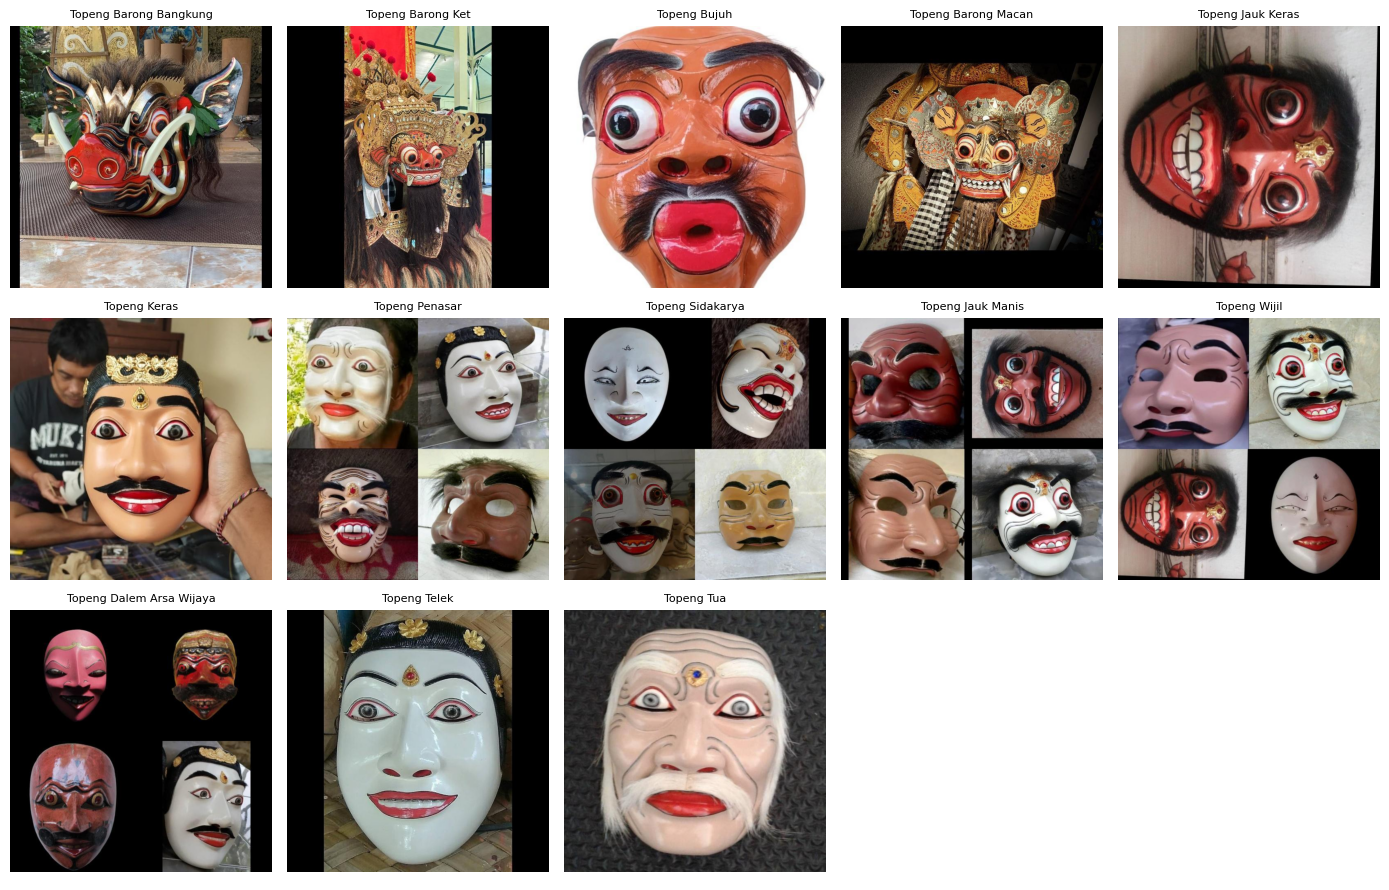

In [11]:
def grouped_stratified_split(df, ratios=(0.70, 0.15, 0.15), seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    split = pd.Series("train", index=df.index, dtype=object)
    for label, sub in df.groupby("label"):
        groups = sub["group"].unique().tolist()
        rng.shuffle(groups)
        sizes = sub.groupby("group").size().to_dict()
        total = len(sub)
        target = {"train": ratios[0] * total, "val": ratios[1] * total, "test": ratios[2] * total}
        got = {"train": 0, "val": 0, "test": 0}
        # tetapkan test lalu val lebih dulu agar kelas kecil tetap terwakili
        for g in groups:
            need = max(("test", "val", "train"), key=lambda s: target[s] - got[s])
            idx = sub.index[sub["group"] == g]
            split.loc[idx] = need
            got[need] += sizes[g]
    return split

have = set(records_df["split"].dropna().unique())
if {"train", "val", "test"} <= have and records_df["split"].notna().all():
    split_source = "pembagian bawaan dataset (train/valid/test)"
else:
    records_df["split"] = grouped_stratified_split(records_df)
    split_source = "pembagian stratified 70/15/15 per kelompok foto sumber (dibuat notebook, seed 42)"
records_df["split"] = records_df["split"].astype(str)
records_df["label"] = records_df["label"].astype(str)

labels_all = records_df["label"].to_numpy(dtype=str)
splits_all = records_df["split"].to_numpy(dtype=str)
paths_all = records_df["path"].to_numpy(dtype=str)
train_idx = np.where(splits_all == "train")[0]
val_idx = np.where(splits_all == "val")[0]
test_idx = np.where(splits_all == "test")[0]
gallery_idx = np.concatenate([train_idx, val_idx])
print("Sumber pembagian:", split_source)
print(f"Train={len(train_idx)}  Validation={len(val_idx)}  Test={len(test_idx)}  Total={len(records_df)}")

# ---------------- PENGAMAN: hentikan bila hasil evaluasi pasti tidak bermakna ----------------
n_labels = records_df["label"].nunique()
if n_labels < 2:
    raise RuntimeError(
        f"\nHANYA {n_labels} LABEL TERBACA ({sorted(records_df['label'].unique())}).\n"
        "Dengan satu label, setiap hasil pencarian dianggap relevan sehingga precision dan mAP selalu 100% "
        "dan tidak bermakna. Periksa dataset (label YOLO/data.yaml atau folder kelas) lalu jalankan ulang."
    )
if len(train_idx) == 0 or len(val_idx) == 0 or len(test_idx) == 0:
    raise RuntimeError("Salah satu split (train/val/test) kosong. Periksa struktur dataset.")
if n_labels != EXPECTED_N_LABELS:
    print(f"PERINGATAN: jumlah label {n_labels} (proposal: {EXPECTED_N_LABELS}). Label terbaca: {sorted(records_df['label'].unique())}")
unk = sorted(set(records_df["label"]) - set(CLASS_NAMES_PROPOSAL))
if unk:
    print("PERINGATAN: label di luar 13 nama proposal (relevansi longgar memperlakukannya sebagai kelas tunggal):", unk)
missing_in_train = sorted(set(labels_all[test_idx]) - set(labels_all[train_idx]))
if missing_in_train:
    print("PERINGATAN: label uji tanpa contoh pada train:", missing_in_train)
if EXPECTED_TOTAL and abs(len(records_df) - EXPECTED_TOTAL) > 0.05 * EXPECTED_TOTAL:
    print(f"CATATAN DATASET: jumlah unit {len(records_df)} berbeda >5% dari Tabel 2 proposal ({EXPECTED_TOTAL}). "
          "Proposal tidak diubah: laporkan jumlah aktual pada tabel di bawah sebagai temuan dataset "
          "(salinan dataset ini adalah ekspor Roboflow yang memuat versi augmentasi dari foto sumber yang sama).")

# kebocoran antar-split melalui kelompok foto sumber
grp_split = records_df.groupby("group")["split"].nunique()
n_leak_groups = int((grp_split > 1).sum())
print(f"Kelompok foto sumber yang muncul di >1 split: {n_leak_groups} dari {len(grp_split)}"
      + ("  <-- RISIKO KEBOCORAN; periksa audit dHash di bawah" if n_leak_groups else ""))

# random baseline yang diharapkan
class_share = records_df["label"].value_counts(normalize=True)
print(f"Perkiraan P@k untuk urutan ACAK (pembanding): {float((class_share ** 2).sum() * 100):.1f}%")

split_counts = (records_df.groupby(["label", "split"]).size().unstack(fill_value=0)
                .reindex(columns=["train", "val", "test"], fill_value=0))
split_counts["Total"] = split_counts.sum(axis=1)
cmp = split_counts.copy()
cmp["Tabel 2 proposal"] = [EXPECTED_COUNTS.get(i, np.nan) for i in cmp.index]
cmp["Selisih"] = cmp["Total"] - cmp["Tabel 2 proposal"]
split_counts.loc["TOTAL"] = split_counts.sum(axis=0)
display(split_counts)
print("\nPerbandingan dengan Tabel 2 proposal:")
display(cmp)
split_counts.to_csv(WORK_DIR / "dataset_counts.csv")
cmp.to_csv(WORK_DIR / "dataset_counts_vs_proposal.csv")

sample_df = records_df.groupby("label", group_keys=False).head(1).reset_index(drop=True)
n_show = min(13, len(sample_df))
fig, axes = plt.subplots((n_show + 4) // 5, 5, figsize=(14, 3.0 * ((n_show + 4) // 5)))
axes = np.array(axes).reshape(-1)
for ax in axes: ax.axis("off")
for ax, row in zip(axes, sample_df.iloc[:n_show].itertuples()):
    im = cv2.cvtColor(cv2.imread(row.path), cv2.COLOR_BGR2RGB)
    ax.imshow(im); ax.set_title(row.label, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.savefig(WORK_DIR / "contoh_citra_per_label.png", dpi=130, bbox_inches="tight"); plt.show()

## 6. Pra-pemrosesan dan ekstraksi fitur handcrafted
- **Skenario 1 (hanya perubahan ukuran):** seluruh citra diubah ke 128×128. Histogram warna, HOG, dan LBP dihitung dari seluruh citra; siluet topeng tetap diperlukan untuk *Hu Moments*.
- **Skenario 2 (pra-pemrosesan penuh):** area topeng dipotong (kotak anotasi bila ada, atau hasil segmentasi), latar dibatasi, kanal V dinormalisasi dengan CLAHE.
- **Skenario 2b (tambahan):** sama dengan Skenario 2 tetapi **tanpa kotak anotasi** (hanya segmentasi otomatis), karena pengguna website tidak memiliki kotak anotasi.
- Segmentasi: GrabCut (kotak awal hampir seluas citra) dengan Otsu sebagai cadangan, dilakukan pada citra yang diperkecil agar cepat.

In [12]:
# Detektor dibuat baru pada setiap pemanggilan dan TIDAK disimpan di variabel global:
# objek cv2.SIFT/SURF tidak dapat di-pickle sehingga akan menggagalkan ekstraksi paralel (joblib).
def get_sift():
    try:
        return cv2.SIFT_create(nfeatures=300) if hasattr(cv2, "SIFT_create") else None
    except Exception:
        return None

def get_surf():
    try:
        ok = hasattr(cv2, "xfeatures2d") and hasattr(cv2.xfeatures2d, "SURF_create")
        return cv2.xfeatures2d.SURF_create(hessianThreshold=400) if ok else None
    except Exception:
        return None

SIFT_AVAILABLE = get_sift() is not None
SURF_AVAILABLE = get_surf() is not None
print("SIFT tersedia:", SIFT_AVAILABLE, "| SURF tersedia:", SURF_AVAILABLE)
if not SURF_AVAILABLE:
    print("Catatan baseline: SURF tidak tersedia pada build OpenCV ini; baseline memakai SIFT + HOG (keterbatasan adaptasi).")
EXTRA_NAMES = ["hu_edge", "lbp_fine", "lbp_ms"] if RUN_EXTRA_FEATURES else []   # tambahan, bukan bagian model usulan
FEATURE_NAMES = ["hsv", "hog", "hu", "lbp"] + (["sift"] if SIFT_AVAILABLE else []) + (["surf"] if SURF_AVAILABLE else []) + EXTRA_NAMES

def shrink(bgr, max_side=SEG_MAX_SIDE):
    h, w = bgr.shape[:2]
    s = max_side / max(h, w)
    if s >= 1:
        return bgr
    return cv2.resize(bgr, (max(1, int(w * s)), max(1, int(h * s))), interpolation=cv2.INTER_AREA)

def largest_contour_mask(mask):
    mask = (mask > 0).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return np.full(mask.shape, 255, np.uint8)
    largest = max(contours, key=cv2.contourArea)
    ratio = cv2.contourArea(largest) / max(1, mask.shape[0] * mask.shape[1])
    if ratio < 0.02 or ratio > 0.98:
        return np.full(mask.shape, 255, np.uint8)
    clean = np.zeros(mask.shape, np.uint8)
    cv2.drawContours(clean, [largest], -1, 255, thickness=cv2.FILLED)
    return clean

def segment_foreground(bgr):
    h, w = bgr.shape[:2]
    if h < 10 or w < 10:
        return np.full((h, w), 255, np.uint8)
    try:
        gc_mask = np.zeros((h, w), np.uint8)
        rect = (max(1, int(0.03 * w)), max(1, int(0.03 * h)), max(2, int(0.94 * w)), max(2, int(0.94 * h)))
        bgd = np.zeros((1, 65), np.float64); fgd = np.zeros((1, 65), np.float64)
        cv2.setRNGSeed(RANDOM_SEED)   # GrabCut memakai inisialisasi acak (k-means): kunci seed agar hasil sama pada mode serial maupun paralel
        cv2.grabCut(bgr, gc_mask, rect, bgd, fgd, 3, cv2.GC_INIT_WITH_RECT)
        binary = np.where((gc_mask == cv2.GC_FGD) | (gc_mask == cv2.GC_PR_FGD), 255, 0).astype(np.uint8)
        clean = largest_contour_mask(binary)
        if 0.03 <= np.mean(clean > 0) <= 0.97:
            return clean
    except Exception:
        pass
    gray = cv2.GaussianBlur(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    _, th = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    bw = max(1, min(h, w) // 30)
    def border_ratio(m):
        b = np.concatenate([m[:bw].ravel(), m[-bw:].ravel(), m[:, :bw].ravel(), m[:, -bw:].ravel()])
        return float(np.mean(b > 0))
    return largest_contour_mask(min([th, cv2.bitwise_not(th)], key=border_ratio))

def crop_from_normalized_bbox(image, bbox, padding=0.05):
    if bbox is None:
        return image
    h, w = image.shape[:2]
    xc, yc, bw, bh = bbox
    x0 = max(0, int((xc - bw / 2 - padding * bw) * w)); x1 = min(w, int((xc + bw / 2 + padding * bw) * w))
    y0 = max(0, int((yc - bh / 2 - padding * bh) * h)); y1 = min(h, int((yc + bh / 2 + padding * bh) * h))
    if x1 - x0 < 5 or y1 - y0 < 5:
        return image
    return image[y0:y1, x0:x1]

def crop_to_mask_bbox(image, mask, padding=0.08):
    ys, xs = np.where(mask > 0)
    if len(xs) < 10:
        return image, mask
    h, w = image.shape[:2]
    x0, x1, y0, y1 = xs.min(), xs.max() + 1, ys.min(), ys.max() + 1
    px, py = int((x1 - x0) * padding), int((y1 - y0) * padding)
    x0, x1, y0, y1 = max(0, x0 - px), min(w, x1 + px), max(0, y0 - py), min(h, y1 + py)
    if x1 - x0 < 5 or y1 - y0 < 5:
        return image, mask
    return image[y0:y1, x0:x1], mask[y0:y1, x0:x1]

def normalize_v_channel(bgr):
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    hsv[:, :, 2] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(hsv[:, :, 2])
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

def preprocess_image(image_path, bbox=None, full_preprocess=False, image=None):
    image = cv2.imread(str(image_path)) if image is None else image.copy()
    if image is None:
        raise ValueError(f"Gambar tidak dapat dibaca: {image_path}")
    if UNIT_MODE == "annotation" and bbox is not None:
        image = crop_from_normalized_bbox(image, bbox)       # unit = satu topeng
        bbox_used = None
    else:
        bbox_used = bbox
    if not full_preprocess:
        resized = cv2.resize(image, IMAGE_SIZE, interpolation=cv2.INTER_AREA)
        shape_mask = segment_foreground(resized)
        return resized, np.full(shape_mask.shape, 255, np.uint8), shape_mask, False
    if bbox_used is not None:
        cropped = shrink(crop_from_normalized_bbox(image, bbox_used))
        mask = segment_foreground(cropped)
    else:
        small = shrink(image)
        mask = segment_foreground(small)
        cropped, mask = crop_to_mask_bbox(small, mask)
    resized = cv2.resize(cropped, IMAGE_SIZE, interpolation=cv2.INTER_AREA)
    shape_mask = (cv2.resize(mask, IMAGE_SIZE, interpolation=cv2.INTER_NEAREST) > 0).astype(np.uint8) * 255
    if np.mean(shape_mask > 0) < 0.02 or np.mean(shape_mask > 0) > 0.98:
        shape_mask = np.full((IMAGE_SIZE[1], IMAGE_SIZE[0]), 255, np.uint8)
    resized = normalize_v_channel(resized)
    return resized, shape_mask.copy(), shape_mask, True

def l2_normalize_rows(matrix, eps=1e-12):
    matrix = np.asarray(matrix, dtype=np.float32)
    return matrix / np.maximum(np.linalg.norm(matrix, axis=1, keepdims=True), eps)

def summarize_local_descriptors(detector, gray, size):
    if detector is None:
        return None
    try:
        _, desc = detector.detectAndCompute(gray, None)
        if desc is None or len(desc) == 0:
            return np.zeros(size * 2, np.float32)
        desc = desc.astype(np.float32)
        return np.concatenate([desc.mean(axis=0), desc.std(axis=0)]).astype(np.float32)
    except Exception:
        return np.zeros(size * 2, np.float32)

def _hu_log(moments):
    hu = cv2.HuMoments(moments).flatten()
    return (-np.sign(hu) * np.log10(np.abs(hu) + 1e-12)).astype(np.float32)

def hu_from_edges(fgray, shape_mask):
    """(tambahan) Hu Moments dari peta tepi Canny di dalam area topeng: menangkap sebaran kontur/ornamen internal, bukan siluet luar."""
    edges = cv2.Canny(fgray, 80, 160)
    edges[shape_mask == 0] = 0
    if np.count_nonzero(edges) < 10:
        return np.zeros(7, np.float32)
    return _hu_log(cv2.moments(edges, binaryImage=True))

def lbp_grid_hist(gray, P, R, grid, method, bins):
    """(tambahan) Histogram LBP per sel pada grid tertentu."""
    lbp_img = local_binary_pattern(gray, P=P, R=R, method=method)
    H, W = lbp_img.shape; parts = []
    for r in range(grid[0]):
        for c in range(grid[1]):
            cell = np.asarray(lbp_img[r * H // grid[0]:(r + 1) * H // grid[0], c * W // grid[1]:(c + 1) * W // grid[1]], dtype=np.int32)
            hist = np.bincount(cell.ravel(), minlength=bins)[:bins].astype(np.float32)
            parts.append(hist / max(float(hist.sum()), 1.0))
    return np.concatenate(parts).astype(np.float32)

def extract_raw_features_from_arrays(bgr, color_mask, shape_mask, use_mask_for_visual=False):
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    fgray = gray.copy()
    if use_mask_for_visual:
        fgray[shape_mask == 0] = 255
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    hsv_hist = cv2.calcHist([hsv], [0, 1, 2], color_mask, list(HSV_BINS), [0, 180, 0, 256, 0, 256]).flatten().astype(np.float32)
    hog_vec = hog(fgray, orientations=HOG_ORIENTATIONS, pixels_per_cell=HOG_PIXELS_PER_CELL,
                  cells_per_block=HOG_CELLS_PER_BLOCK, block_norm="L2-Hys", feature_vector=True).astype(np.float32)
    hu = cv2.HuMoments(cv2.moments((shape_mask > 0).astype(np.uint8) * 255)).flatten()
    hu_log = (-np.sign(hu) * np.log10(np.abs(hu) + 1e-12)).astype(np.float32)
    lbp_img = local_binary_pattern(fgray, P=LBP_P, R=LBP_R, method="nri_uniform")
    parts, (H, W) = [], lbp_img.shape
    for r in range(LBP_GRID[0]):
        for c in range(LBP_GRID[1]):
            cell = np.asarray(lbp_img[r * H // LBP_GRID[0]:(r + 1) * H // LBP_GRID[0],
                                      c * W // LBP_GRID[1]:(c + 1) * W // LBP_GRID[1]], dtype=np.int32)
            hist = np.bincount(cell.ravel(), minlength=LBP_BINS_PER_CELL)[:LBP_BINS_PER_CELL].astype(np.float32)
            parts.append(hist / max(float(hist.sum()), 1.0))
    out = {"hsv": hsv_hist, "hog": hog_vec, "hu": hu_log, "lbp": np.concatenate(parts).astype(np.float32)}
    if RUN_EXTRA_FEATURES:
        out["hu_edge"] = hu_from_edges(fgray, shape_mask)
        out["lbp_fine"] = lbp_grid_hist(fgray, 8, 1, (4, 4), "nri_uniform", 59)
        out["lbp_ms"] = np.concatenate([lbp_grid_hist(fgray, 8, 1, (4, 4), "uniform", 10), lbp_grid_hist(fgray, 16, 2, (4, 4), "uniform", 18)])
    sift = get_sift()
    if sift is not None:
        out["sift"] = summarize_local_descriptors(sift, fgray, 128)
    surf = get_surf()
    if surf is not None:
        out["surf"] = summarize_local_descriptors(surf, fgray, int(surf.descriptorSize()))
    return out

def _extract_one(item):
    cv2.setNumThreads(1)
    path, bbox, full = item
    bgr, cmask, smask, use_mask = preprocess_image(path, bbox=bbox, full_preprocess=full)
    return extract_raw_features_from_arrays(bgr, cmask, smask, use_mask_for_visual=use_mask)

def parallel_map(fn, items, desc, chunk=48):
    if N_JOBS == 1 or len(items) < 8:
        return [fn(it) for it in tqdm(items, desc=desc)]
    out = []
    with Parallel(n_jobs=N_JOBS) as par:
        for i in tqdm(range(0, len(items), chunk), desc=desc):
            out.extend(par(delayed(fn)(it) for it in items[i:i + chunk]))
    return out

def extract_feature_matrices(frame, full_preprocess, description, use_bbox=True):
    t0 = time.time()
    items = [(r.path, (r.bbox if use_bbox else None), full_preprocess) for r in frame.itertuples(index=False)]
    feats = parallel_map(_extract_one, items, description)
    matrices = {k: np.vstack([f[k] for f in feats]).astype(np.float32) for k in FEATURE_NAMES}
    dims = {k: int(v.shape[1]) for k, v in matrices.items()}
    print(f"Selesai {description} dalam {(time.time() - t0) / 60:.1f} menit | dimensi: {dims}")
    return matrices

SIFT tersedia: True | SURF tersedia: False
Catatan baseline: SURF tidak tersedia pada build OpenCV ini; baseline memakai SIFT + HOG (keterbatasan adaptasi).


## 7. Ekstraksi fitur untuk dua skenario
Ekstraksi dilakukan sekali per gambar untuk tiap skenario.

In [13]:
FEATURES = {
    "s1_resize_saja": extract_feature_matrices(records_df, False, "Skenario 1: hanya perubahan ukuran"),
    "s2_praproses_penuh": extract_feature_matrices(records_df, True, "Skenario 2: crop/segmentasi/CLAHE"),
}
# Tambahan: Skenario 2b - pra-pemrosesan penuh tanpa kotak anotasi (hanya bermakna bila anotasi memuat kotak dan UNIT_MODE = "image")
if RUN_S2_AUTO_SEG and UNIT_MODE == "image" and records_df["bbox"].notna().any():
    FEATURES["s2b_praproses_otomatis"] = extract_feature_matrices(records_df, True, "Skenario 2b: pra-pemrosesan penuh tanpa kotak anotasi", use_bbox=False)
EXPECTED_DIMS = {"hsv": 256, "hog": 1764, "hu": 7, "lbp": 236}
for sc, fd in FEATURES.items():
    for name, dim in EXPECTED_DIMS.items():
        if fd[name].shape[1] != dim:
            print("PERINGATAN dimensi", sc, name, fd[name].shape[1], "!=", dim)
print("Fitur selesai.")


Skenario 1: hanya perubahan ukuran: 100%|██████████| 99/99 [03:59<00:00,  2.42s/it]


Selesai Skenario 1: hanya perubahan ukuran dalam 4.0 menit | dimensi: {'hsv': 256, 'hog': 1764, 'hu': 7, 'lbp': 236, 'sift': 256, 'hu_edge': 7, 'lbp_fine': 944, 'lbp_ms': 448}


Skenario 2: crop/segmentasi/CLAHE: 100%|██████████| 99/99 [02:21<00:00,  1.43s/it]


Selesai Skenario 2: crop/segmentasi/CLAHE dalam 2.4 menit | dimensi: {'hsv': 256, 'hog': 1764, 'hu': 7, 'lbp': 236, 'sift': 256, 'hu_edge': 7, 'lbp_fine': 944, 'lbp_ms': 448}


Skenario 2b: pra-pemrosesan penuh tanpa kotak anotasi: 100%|██████████| 99/99 [03:27<00:00,  2.10s/it]


Selesai Skenario 2b: pra-pemrosesan penuh tanpa kotak anotasi dalam 3.5 menit | dimensi: {'hsv': 256, 'hog': 1764, 'hu': 7, 'lbp': 236, 'sift': 256, 'hu_edge': 7, 'lbp_fine': 944, 'lbp_ms': 448}
Fitur selesai.


## 8. Metrik temu kembali
Relevansi **ketat**: label sama. Relevansi **longgar**: satu keluarga topeng (Barong: Bangkung/Ket/Macan; Jauk: Keras/Manis; lainnya berdiri sendiri).
Metrik utama (sesuai proposal): P@k, R@k (k = 5, 10, 20), dan mAP. Tambahan: P@1 (setara akurasi top-1), R@k pada k besar (50/100/200) dan R-precision, karena jumlah citra relevan per kelas ~270 sehingga R@5/10/20 kecil secara alami. TP/TN/FP/FN pada k teratas hanya untuk tabel template (lampiran).

In [14]:
def loose_family(label):
    if label in {"Topeng Barong Bangkung", "Topeng Barong Ket", "Topeng Barong Macan"}:
        return "FAMILY_BARONG"
    if label in {"Topeng Jauk Keras", "Topeng Jauk Manis"}:
        return "FAMILY_JAUK"
    return "CLASS_" + normalize_key(label)

# Nama model (dipakai konsisten di seluruh notebook)
M_RAND = "Acak (pembanding)"
M_BASE = "Baseline SIFT/SURF/HOG + Euclidean"
M_1 = "Model 1: HSV + HOG + Hu"
M_2 = "Model 2: Model 1 + LBP"
M_2B = "Model 2b (tambahan): semua blok aktif"
M_BASE_T = "Baseline [16] dengan bobot dituning di validasi (tambahan)"
M_BASE_HOG = "Varian baseline: HOG saja + Euclidean (tambahan)"
M_BASE_SIFT = "Varian baseline: SIFT saja + Euclidean (tambahan)"
M_HOGCOS = "HOG saja (cosine)"
M_HSVHOG_EQ = "HSV + HOG (bobot sama)"

ALL_LABELS = sorted(set(labels_all))
LAB2ID = {l: i for i, l in enumerate(ALL_LABELS)}
LAB_ID = np.array([LAB2ID[l] for l in labels_all], dtype=np.int32)
_fams = sorted({loose_family(l) for l in ALL_LABELS})
FAM_ID = np.array([_fams.index(loose_family(l)) for l in labels_all], dtype=np.int32)

def per_query_metrics(scores, q_global, g_global, ks=None):
    """Metrik PER KUERI (dalam %), relevansi ketat dan longgar.
    scores: (nq, ng); q_global/g_global: indeks global ke records_df.
    Mengembalikan (dict array, mask kueri valid ketat, mask kueri valid longgar)."""
    ks = tuple(K_VALUES) + tuple(RECALL_K_LARGE) if ks is None else tuple(ks)
    scores = np.atleast_2d(np.asarray(scores, dtype=np.float32))
    q_global = np.asarray(q_global, dtype=int); g_global = np.asarray(g_global, dtype=int)
    order = np.argsort(-scores, axis=1, kind="stable")
    gl, gf = LAB_ID[g_global], FAM_ID[g_global]
    ql, qf = LAB_ID[q_global], FAM_ID[q_global]
    rel_s = gl[order] == ql[:, None]; rel_l = gf[order] == qf[:, None]
    tot_s = (gl[None, :] == ql[:, None]).sum(1).astype(np.float32)
    tot_l = (gf[None, :] == qf[:, None]).sum(1).astype(np.float32)
    ng = scores.shape[1]
    pos = np.arange(1, ng + 1, dtype=np.float32)[None, :]
    cs_s = np.cumsum(rel_s, 1); cs_l = np.cumsum(rel_l, 1)
    out = {"AP_strict": ((cs_s / pos) * rel_s).sum(1) / np.maximum(tot_s, 1) * 100,
           "AP_loose": ((cs_l / pos) * rel_l).sum(1) / np.maximum(tot_l, 1) * 100}
    for k in sorted(set((1,) + ks)):
        kk = min(int(k), ng); hits = cs_s[:, kk - 1]
        out[f"P@{k}"] = hits / kk * 100
        out[f"R@{k}"] = hits / np.maximum(tot_s, 1) * 100
    r_idx = np.clip(tot_s.astype(int) - 1, 0, ng - 1)
    out["R-Prec"] = cs_s[np.arange(len(cs_s)), r_idx] / np.maximum(tot_s, 1) * 100
    return out, tot_s > 0, tot_l > 0       # kueri tanpa citra relevan tersisa tidak dihitung (hindari nilai 0 semu)

def metrics_from_scores(scores, q_global, g_global, ks=K_VALUES):
    pq, vs, vl = per_query_metrics(scores, q_global, g_global, ks=tuple(ks) + tuple(RECALL_K_LARGE))
    def nmean(x, valid):
        return float(np.mean(x[valid])) if valid.any() else float("nan")
    out = {"P@1": nmean(pq["P@1"], vs)}
    for k in ks:
        out[f"P@{k}"] = nmean(pq[f"P@{k}"], vs); out[f"R@{k}"] = nmean(pq[f"R@{k}"], vs)
    for k in RECALL_K_LARGE:
        out[f"R@{k}"] = nmean(pq[f"R@{k}"], vs)
    out["R-Prec"] = nmean(pq["R-Prec"], vs)
    out["mAP_strict"] = nmean(pq["AP_strict"], vs); out["mAP_loose"] = nmean(pq["AP_loose"], vl)
    return out

def map_strict_fast(scores, q_global, g_global):
    order = np.argsort(-scores, axis=1, kind="stable")
    gl = LAB_ID[np.asarray(g_global)]; ql = LAB_ID[np.asarray(q_global)]
    rel = gl[order] == ql[:, None]
    pos = np.arange(1, scores.shape[1] + 1, dtype=np.float32)[None, :]
    tot = np.array([(gl == q).sum() for q in ql], dtype=np.float32)
    return float((((np.cumsum(rel, 1) / pos) * rel).sum(1) / np.maximum(tot, 1)).mean() * 100)

def count_rows(scores, q_global, g_global, k=TABLE_K):
    """TP/FP/FN/TN per kueri pada k teratas (relevansi ketat)."""
    scores = np.atleast_2d(scores); g_global = np.asarray(g_global); gl = LAB_ID[g_global]
    rows = []
    kk = min(k, scores.shape[1])
    for i, qg in enumerate(np.asarray(q_global, dtype=int)):
        top = np.argpartition(-scores[i], kk - 1)[:kk]
        R = int((gl == LAB_ID[qg]).sum()); tp = int((gl[top] == LAB_ID[qg]).sum())
        fp = kk - tp; fn = R - tp; tn = (len(gl) - R) - fp
        rows.append({"label": labels_all[qg], "TP": tp, "FP": fp, "FN": fn, "TN": tn})
    return rows

def template_table(rows, scenario_label, first_col="Scenario"):
    """Format tabel template (LAMPIRAN). Catatan: pada temu kembali, TN sangat besar sehingga Akurasi/Specificity
    mendekati 100% dan tidak informatif; Recall@10 kecil karena jumlah citra relevan (R) jauh lebih besar dari k."""
    df = pd.DataFrame(rows)
    out = []
    for label, sub in df.groupby("label"):
        tp, fp, fn, tn, n = sub.TP.sum(), sub.FP.sum(), sub.FN.sum(), sub.TN.sum(), len(sub)
        prec = tp / (tp + fp) * 100 if tp + fp else np.nan
        rec = tp / (tp + fn) * 100 if tp + fn else np.nan
        f1 = 2 * prec * rec / (prec + rec) if prec == prec and rec == rec and prec + rec > 0 else np.nan
        acc = (tp + tn) / (tp + tn + fp + fn) * 100
        spec = tn / (tn + fp) * 100 if tn + fp else np.nan
        out.append({first_col: scenario_label, "Class / Label": label, "TP": tp / n, "TN": tn / n, "FP": fp / n, "FN": fn / n,
                    "(%) Presisi": prec, "(%) Recall (Sensitivity)": rec, "(%) F1-Score": f1,
                    "(%) Akurasi": acc, "(%) Specificity": spec, "Support": n})
    return pd.DataFrame(out)

print("Metrik siap. Label:", len(ALL_LABELS), "| keluarga relevansi longgar:", len(_fams))


Metrik siap. Label: 13 | keluarga relevansi longgar: 10


## 9. Normalisasi blok fitur, kemiripan cosine, dan pencarian bobot
Tiap blok dinormalisasi L2 (khusus *Hu Moments*: log lalu z-score memakai statistik galeri). Tiga mode normalisasi dicoba dan **dipilih lewat mAP validasi** (data uji tidak dipakai):
`l2`, `centered` (rata-rata galeri dikurangkan sebelum L2, agar kemiripan histogram HSV/LBP tidak menyempit), dan `centered+zscore` (kemiripan cosine tiap blok di-z-score per kueri sehingga **rentang nilai tiap blok sebanding** sebelum dijumlahkan, sejalan dengan Bab 2.2 proposal). Kemiripan akhir = jumlah berbobot kemiripan cosine tiap blok.
Bobot dicari dengan grid berlangkah 0,1 pada **validasi** (kueri validasi terhadap galeri latih), mAP ketat sebagai kriteria. Bila banyak kombinasi sama, dipilih yang paling seimbang.
**Model 2b (tambahan):** bobot terbaik dengan syarat semua blok berbobot >= `MIN_WEIGHT_ALL`, diambil dari grid yang sama; dipakai untuk menguji apakah Hu/LBP berguna ketika dipaksa ikut berkontribusi.


In [15]:
BLOCKS_M1 = ["hsv", "hog", "hu"]
BLOCKS_M2 = ["hsv", "hog", "hu", "lbp"]

def prepare_feature_blocks(raw, gallery_indices, query_indices, center=False, names=None):
    """Normalisasi tiap blok: blok Hu (hu, hu_edge) = z-score galeri (nilai log sudah dari ekstraksi);
    blok lain = (opsional dipusatkan) lalu L2. Statistik hanya dari galeri, jadi data kueri tidak ikut menentukan normalisasi."""
    gi, qi = np.asarray(gallery_indices, int), np.asarray(query_indices, int)
    names = list(names) if names is not None else list(FEATURE_NAMES)
    gn, qn, centers, hu_stats = {}, {}, {}, {}
    for block in names:
        g = raw[block][gi].astype(np.float32).copy(); q = raw[block][qi].astype(np.float32).copy()
        if block.startswith("hu"):
            mu = g.mean(axis=0); sd = g.std(axis=0); sd[sd < 1e-8] = 1.0
            g = (g - mu) / sd; q = (q - mu) / sd; hu_stats[block] = (mu, sd)
        elif center:
            mu = g.mean(axis=0); g = g - mu; q = q - mu; centers[block] = mu
        gn[block] = l2_normalize_rows(g); qn[block] = l2_normalize_rows(q)
    scaler = {"center": centers, "hu_stats": hu_stats}
    if "hu" in hu_stats:
        scaler["mean"], scaler["std"] = hu_stats["hu"]
    return gn, qn, scaler

def standardize_scores(S):
    """z-score kemiripan PER KUERI terhadap seluruh galeri. Membuat rentang kemiripan tiap blok sebanding
    (proposal Bab 2.2: tiap blok dinormalisasi agar rentang nilainya sebanding) sehingga bobot fusi menggambarkan
    kontribusi blok, bukan sebaran nilai cosine-nya. Tidak memakai statistik data uji lain; berlaku juga untuk satu kueri."""
    S = np.asarray(S, dtype=np.float32)
    mu = S.mean(axis=-1, keepdims=True); sd = S.std(axis=-1, keepdims=True)
    return (S - mu) / np.maximum(sd, 1e-8)

def cosine_blocks(gn, qn, names, zs=False):
    sims = {b: qn[b] @ gn[b].T for b in names}
    return {b: standardize_scores(s) for b, s in sims.items()} if zs else sims

def combine_similarity(sims, weights):
    first = next(iter(weights)); out = np.zeros_like(sims[first], dtype=np.float32)
    for b, w in weights.items():
        out += float(w) * sims[b]
    return out

def make_weight_grid(n_blocks, step=WEIGHT_STEP):
    units = int(round(1 / step)); combos = []
    def rec(prefix, remaining, slots):
        if slots == 1:
            combos.append(tuple(prefix + [remaining])); return
        for v in range(remaining + 1):
            rec(prefix + [v], remaining - v, slots - 1)
    rec([], units, n_blocks)
    return [tuple(v / units for v in c) for c in combos]

def evaluate_weight_grid(sims, q_global, g_global, names, max_queries=TUNE_MAX_QUERIES):
    """Evaluasi seluruh kombinasi bobot (grid berlangkah WEIGHT_STEP) pada data VALIDASI. Mengembalikan DataFrame riwayat."""
    q_global = np.asarray(q_global)
    if max_queries is not None and len(q_global) > int(max_queries):
        rng = np.random.default_rng(RANDOM_SEED)
        chosen = np.sort(rng.choice(len(q_global), int(max_queries), replace=False))
        q_global = q_global[chosen]; sims = {k: v[chosen] for k, v in sims.items()}
    hist = []
    for values in tqdm(make_weight_grid(len(names)), desc=f"Grid bobot ({len(names)} blok)", leave=False):
        w = dict(zip(names, values))
        hist.append({**w, "validation_mAP_strict": map_strict_fast(combine_similarity(sims, w), q_global, g_global)})
    return pd.DataFrame(hist)

def select_weights(h, names, min_weight=0.0, verbose=True):
    """Pilih bobot terbaik dari riwayat grid. min_weight > 0 memaksa semua blok aktif (varian Model 2b).
    Bila banyak kombinasi memberi mAP sama, dipilih yang paling seimbang (entropi terbesar)."""
    sub = h[(h[names] >= min_weight - 1e-9).all(axis=1)]
    best = sub["validation_mAP_strict"].max()
    ties = sub[sub["validation_mAP_strict"] >= best - 1e-9].copy()
    arr = ties[names].to_numpy(); arr = np.where(arr > 0, arr, 1.0)
    ties["entropy"] = -(ties[names].to_numpy() * np.log(arr)).sum(1)
    pick = ties.sort_values("entropy", ascending=False).iloc[0]
    if verbose and len(ties) > 1:
        print(f"  {len(ties)} kombinasi bobot memberi mAP validasi sama ({best:.3f}%); dipilih yang paling seimbang.")
        if len(ties) > 0.5 * len(sub):
            print("  PERINGATAN: >50% kombinasi memberi mAP sama -> fitur tidak membedakan kelas atau label bermasalah.")
    return {b: float(pick[b]) for b in names}, float(best)

def tune_weights(sims, q_global, g_global, names, max_queries=TUNE_MAX_QUERIES):
    h = evaluate_weight_grid(sims, q_global, g_global, names, max_queries)
    weights, best = select_weights(h, names)
    return weights, best, h.sort_values("validation_mAP_strict", ascending=False).reset_index(drop=True)

def baseline_matrix(raw, indices):
    names = [n for n in ("sift", "surf", "hog") if n in raw]
    blocks = [l2_normalize_rows(raw[n][np.asarray(indices, int)]) / math.sqrt(len(names)) for n in names]
    return np.concatenate(blocks, axis=1), names

def baseline_names_of(raw):
    return [n for n in ("sift", "surf", "hog") if n in raw]

def baseline_sqdists(raw, names, query_indices, gallery_indices):
    """Jarak Euclidean KUADRAT per blok baseline (tiap blok dinormalisasi L2). Bobot sama 1/n = baseline asli (peringkat identik)."""
    gi, qi = np.asarray(gallery_indices, int), np.asarray(query_indices, int)
    return {n: cdist(l2_normalize_rows(raw[n][qi]), l2_normalize_rows(raw[n][gi]), metric="sqeuclidean").astype(np.float32) for n in names}

def tune_baseline_weights(raw, names):
    """(tambahan) Bobot antar blok baseline dituning di VALIDASI dengan grid dan kriteria yang sama seperti Model 1/2,
    agar perbandingan dengan model usulan adil (baseline asli memakai bobot sama tanpa tuning)."""
    D = baseline_sqdists(raw, names, val_idx, train_idx)
    h = evaluate_weight_grid({n: -D[n] for n in names}, val_idx, train_idx, names)
    w, best = select_weights(h, names, verbose=False)
    return w, best

def baseline_similarity(raw, gallery_indices, query_indices):
    gv, names = baseline_matrix(raw, gallery_indices); qv, _ = baseline_matrix(raw, query_indices)
    return -cdist(qv, gv, metric="euclidean").astype(np.float32), gv, qv, names

print("Kandidat bobot Model 1:", len(make_weight_grid(3)), "| Model 2:", len(make_weight_grid(4)))


Kandidat bobot Model 1: 66 | Model 2: 286


## 10. Audit citra hampir duplikat (dHash) dan evaluasi baseline, Model 1, Model 2
dHash 64-bit dihitung untuk semua gambar. Kueri uji yang punya citra hampir duplikat di galeri ditandai; hasil juga dilaporkan **tanpa** kueri tersebut sebagai uji kebocoran.

In [16]:
def _dhash_one(path):
    g = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if g is None:
        return np.zeros(8, np.uint8)
    s = cv2.resize(g, (9, 8), interpolation=cv2.INTER_AREA)
    bits = (s[:, 1:] > s[:, :-1]).flatten().astype(np.uint8)
    return np.packbits(bits)

uniq_paths = list(dict.fromkeys(paths_all.tolist()))
_h = parallel_map(_dhash_one, uniq_paths, "dHash", chunk=128)
HASH_BY_PATH = {p: h for p, h in zip(uniq_paths, _h)}
HASHES = np.vstack([HASH_BY_PATH[p] for p in paths_all])
_POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
def min_hamming(q_idx, g_idx):
    qa, ga = HASHES[q_idx], HASHES[g_idx]
    best = np.full(len(qa), 64, dtype=np.int32)
    for i in range(0, len(qa), 64):
        d = _POP[qa[i:i + 64, None, :] ^ ga[None, :, :]].sum(axis=2)
        best[i:i + 64] = d.min(axis=1)
    return best
test_min_dist = min_hamming(test_idx, gallery_idx)
NEAR_DUP_MASK = test_min_dist <= NEAR_DUP_HAMMING
print(f"Kueri uji dengan citra hampir duplikat di galeri (jarak Hamming <= {NEAR_DUP_HAMMING}): "
      f"{int(NEAR_DUP_MASK.sum())} dari {len(test_idx)} ({NEAR_DUP_MASK.mean() * 100:.1f}%)")
pd.DataFrame({"path": paths_all[test_idx], "label": labels_all[test_idx], "min_hamming_ke_galeri": test_min_dist,
              "near_duplicate": NEAR_DUP_MASK}).to_csv(WORK_DIR / "audit_near_duplicate_uji.csv", index=False)

NORM_MODES = {
    "l2":              dict(center=False, zs=False),   # L2 saja
    "centered":        dict(center=True,  zs=False),   # rata-rata galeri dikurangkan, lalu L2
    "centered+zscore": dict(center=True,  zs=True),    # + z-score kemiripan per kueri agar rentang antar blok sebanding
}

def tune_mode(raw, spec):
    gn_v, qn_v, _ = prepare_feature_blocks(raw, train_idx, val_idx, center=spec["center"])
    cos_raw = cosine_blocks(gn_v, qn_v, BLOCKS_M2, False)
    s2 = cosine_blocks(gn_v, qn_v, BLOCKS_M2, spec["zs"]); s1 = {b: s2[b] for b in BLOCKS_M1}
    w1, vm1, h1 = tune_weights(s1, val_idx, train_idx, BLOCKS_M1)
    w2, vm2, h2 = tune_weights(s2, val_idx, train_idx, BLOCKS_M2)
    w2m, vm2m = select_weights(h2, BLOCKS_M2, min_weight=MIN_WEIGHT_ALL, verbose=False)   # subset grid yang sama (tanpa evaluasi ulang)
    alone = [{"Blok": b, "mAP validasi sendirian (%)": map_strict_fast(cos_raw[b], val_idx, train_idx),
              "rata-rata cosine": float(cos_raw[b].mean()), "simpangan baku cosine": float(cos_raw[b].std())} for b in BLOCKS_M2]
    return dict(spec=spec, w1=w1, vm1=vm1, h1=h1, w2=w2, vm2=vm2, h2=h2, w2m=w2m, vm2m=vm2m, alone=alone)

def evaluate_scenario(name):
    print("\n" + "=" * 78 + "\nMenjalankan:", name)
    raw = FEATURES[name]
    use_modes = [NORMALIZATION] if NORMALIZATION in NORM_MODES else list(NORM_MODES)
    tuned = {m: tune_mode(raw, NORM_MODES[m]) for m in use_modes}
    for m, t in tuned.items():
        print(f"[{m}] Bobot Model 1:", {k: round(v, 2) for k, v in t["w1"].items()}, "| mAP validasi:", round(t["vm1"], 3))
        print(f"[{m}] Bobot Model 2:", {k: round(v, 2) for k, v in t["w2"].items()}, "| mAP validasi:", round(t["vm2"], 3))
        print(f"[{m}] Bobot Model 2b:", {k: round(v, 2) for k, v in t["w2m"].items()}, "| mAP validasi:", round(t["vm2m"], 3))
    chosen = use_modes[0]
    for m in use_modes[1:]:                      # seri -> pilih mode yang lebih sederhana (urutan NORM_MODES)
        if tuned[m]["vm2"] > tuned[chosen]["vm2"] + 1e-9:
            chosen = m
    print(f"Normalisasi terpilih (berdasarkan mAP validasi Model 2): {chosen}")
    T = tuned[chosen]; zs = T["spec"]["zs"]
    w1, w2, w2m, vm1, vm2, vm2m, h1, h2 = T["w1"], T["w2"], T["w2m"], T["vm1"], T["vm2"], T["vm2m"], T["h1"], T["h2"]
    ablation = [{"Skenario": name, "Normalisasi": m, **a_} for m, t in tuned.items() for a_ in t["alone"]]
    sc_by_mode, norm_rows = {}, []
    for m, t in tuned.items():
        sp = t["spec"]
        gn_m, qn_m, scaler_m = prepare_feature_blocks(raw, gallery_idx, test_idx, center=sp["center"])
        a1 = cosine_blocks(gn_m, qn_m, BLOCKS_M1, sp["zs"]); a2 = cosine_blocks(gn_m, qn_m, BLOCKS_M2, sp["zs"])
        sc1, sc2, sc2m = combine_similarity(a1, t["w1"]), combine_similarity(a2, t["w2"]), combine_similarity(a2, t["w2m"])
        sc_by_mode[m] = (gn_m, qn_m, scaler_m, sc1, sc2, sc2m, a2)
        for mn, sc, w, vm in ((M_1, sc1, t["w1"], t["vm1"]), (M_2, sc2, t["w2"], t["vm2"]), (M_2B, sc2m, t["w2m"], t["vm2m"])):
            mm = metrics_from_scores(sc, test_idx, gallery_idx)
            norm_rows.append({"Skenario": name, "Normalisasi": m, "Model": mn, "Bobot": json.dumps({k: round(v, 2) for k, v in w.items()}),
                              "mAP validasi (%)": vm, "P@10 uji (%)": mm["P@10"], "mAP uji (%)": mm["mAP_strict"], "Terpilih": m == chosen})
    gn, qn, hu_scaler, sc_m1, sc_m2, sc_m2m, a2 = sc_by_mode[chosen]
    sc_base, g_vec, q_vec, base_names = baseline_similarity(raw, gallery_idx, test_idx)
    # ---- (tambahan) baseline yang adil: bobot SIFT/HOG dituning di validasi, serta varian satu blok ----
    wb, vmb = tune_baseline_weights(raw, base_names)
    print(f"Baseline dituning (validasi): bobot {({k: round(v, 2) for k, v in wb.items()})} | mAP validasi: {vmb:.3f}")
    Dt = baseline_sqdists(raw, base_names, test_idx, gallery_idx)
    sc_base_t = combine_similarity({n: -Dt[n] for n in base_names}, wb)
    sc_hogb = -Dt["hog"]; sc_siftb = -Dt["sift"] if "sift" in Dt else None
    base_blocks_g = {n: l2_normalize_rows(raw[n][gallery_idx]) for n in base_names}
    rng = np.random.default_rng(RANDOM_SEED)
    sc_rand = rng.random(sc_m2.shape).astype(np.float32)
    models = [(M_RAND, sc_rand), (M_BASE, sc_base), (M_1, sc_m1), (M_2, sc_m2), (M_2B, sc_m2m), (M_BASE_T, sc_base_t), (M_BASE_HOG, sc_hogb)]
    if sc_siftb is not None:
        models.append((M_BASE_SIFT, sc_siftb))
    res, counts = [], {}
    for mname, sc in models:
        res.append({"Skenario": name, "Model": mname, "Subset": "semua kueri uji", "Jumlah kueri": len(test_idx), "Normalisasi": chosen,
                    **metrics_from_scores(sc, test_idx, gallery_idx)})
        counts[mname] = count_rows(sc, test_idx, gallery_idx)
    keep = ~NEAR_DUP_MASK
    if keep.sum() >= 5 and NEAR_DUP_MASK.any():
        for mname, sc in models[1:]:
            res.append({"Skenario": name, "Model": mname, "Subset": "tanpa kueri near-duplicate", "Jumlah kueri": int(keep.sum()), "Normalisasi": chosen,
                        **metrics_from_scores(sc[keep], test_idx[keep], gallery_idx)})
    # ---- ABLASI di data uji (tambahan): tiap fitur sendirian, bobot sama, dan bobot hasil validasi ----
    def equal(names):
        return combine_similarity(a2, {b: 1.0 / len(names) for b in names})
    sc_hsvhog_eq = equal(["hsv", "hog"])
    abl_cfgs = [("HSV saja", a2["hsv"]), ("HOG saja", a2["hog"]), ("Hu Moments saja", a2["hu"]), ("LBP saja", a2["lbp"]),
                ("HSV + HOG (bobot sama)", sc_hsvhog_eq),
                ("HSV + HOG + Hu (bobot sama)", equal(BLOCKS_M1)),
                ("HSV + HOG + Hu + LBP (bobot sama)", equal(BLOCKS_M2)),
                (M_1 + " (bobot validasi)", sc_m1), (M_2 + " (bobot validasi)", sc_m2), (M_2B + " (bobot validasi)", sc_m2m)]
    ablation_test = []
    for cname, sc in abl_cfgs:
        mm = metrics_from_scores(sc, test_idx, gallery_idx)
        ablation_test.append({"Skenario": name, "Konfigurasi": cname, "Normalisasi": chosen,
                              **{k: mm[k] for k in ("P@1", "P@5", "P@10", "R@10", "mAP_strict", "mAP_loose")}})
    ctx = dict(scenario=name, raw=raw, gallery_indices=gallery_idx.copy(), query_indices=test_idx.copy(),
               gallery_norm=gn, query_norm=qn, hu_scaler=hu_scaler, zs=zs, w1=w1, w2=w2, w2m=w2m, vm1=vm1, vm2=vm2, vm2m=vm2m, h1=h1, h2=h2,
               baseline_gallery_vec=g_vec, baseline_names=base_names, counts=counts, norm_mode=chosen,
               norm_rows=norm_rows, ablation=ablation, ablation_test=ablation_test,
               scores_m1=sc_m1, scores_m2=sc_m2, scores_m2m=sc_m2m, scores_base=sc_base, scores_rand=sc_rand,
               wb=wb, vmb=vmb, scores_base_t=sc_base_t, scores_hog_b=sc_hogb, scores_sift_b=sc_siftb, baseline_blocks_g=base_blocks_g,
               scores_hogcos=a2["hog"], scores_hsvhog_eq=sc_hsvhog_eq)
    return pd.DataFrame(res), ctx

SCENARIO_NAMES = list(FEATURES.keys())
CTX, RES = {}, []
for _sc in SCENARIO_NAMES:
    _r, CTX[_sc] = evaluate_scenario(_sc); RES.append(_r)
ctx_s1, ctx_s2 = CTX["s1_resize_saja"], CTX["s2_praproses_penuh"]
ctx_s2b = CTX.get("s2b_praproses_otomatis")
results_base_models = pd.concat(RES, ignore_index=True)
display(results_base_models.round(3))
results_base_models.to_csv(WORK_DIR / "hasil_baseline_model1_model2.csv", index=False)

rand_row = results_base_models[(results_base_models["Model"] == M_RAND)].iloc[0]
m2_row = results_base_models[(results_base_models["Model"] == M_2) & (results_base_models["Subset"] == "semua kueri uji") & (results_base_models["Skenario"] == "s2_praproses_penuh")].iloc[0]
print(f"\nPEMERIKSAAN KEWAJARAN: P@10 acak = {rand_row['P@10']:.1f}% | P@10 Model 2 (S2) = {m2_row['P@10']:.1f}%")
if m2_row["P@10"] > 99.5 and len(ALL_LABELS) > 1:
    print("PERINGATAN: P@10 mendekati 100% pada data multi-kelas. Periksa kebocoran data (audit dHash di atas) dan label.")

weights_report = pd.DataFrame([{"Skenario": c["scenario"], "Normalisasi": c["norm_mode"], "Model": m, "Bobot": json.dumps({k: round(v, 3) for k, v in c[key].items()}),
                                "mAP validasi ketat (%)": c[vk]}
                               for c in CTX.values() for m, key, vk in (("Model 1", "w1", "vm1"), ("Model 2", "w2", "vm2"), ("Model 2b", "w2m", "vm2m"), ("Baseline dituning", "wb", "vmb"))])
display(weights_report.round(3))
weights_report.to_csv(WORK_DIR / "bobot_terpilih.csv", index=False)

# ---- DIAGNOSIS: kontribusi tiap blok fitur dan perbandingan normalisasi (validasi untuk pemilihan; uji hanya dilaporkan) ----
ablation_df = pd.DataFrame([a for c in CTX.values() for a in c["ablation"]])
print("\nKontribusi tiap blok fitur SENDIRIAN pada data validasi (pembanding mAP acak sekitar "
      f"{100 * float((class_share ** 2).sum()):.1f}%):")
display(ablation_df.round(3))
ablation_df.to_csv(WORK_DIR / "diagnosis_blok_fitur.csv", index=False)
norm_df = pd.DataFrame([r for c in CTX.values() for r in c["norm_rows"]])
print("Perbandingan normalisasi (pemilihan berdasarkan mAP validasi; kolom uji hanya untuk dilaporkan):")
display(norm_df.round(3))
norm_df.to_csv(WORK_DIR / "perbandingan_normalisasi.csv", index=False)
for c in CTX.values():
    zero = [k for k, v in c["w2"].items() if v == 0]
    if zero:
        print(f"CATATAN {c['scenario']}: blok dengan bobot 0 pada Model 2 -> {zero}. Model 2 = Model 1 untuk blok tsb. "
              "Lihat tabel ablasi (sel berikut) dan Model 2b untuk menilai apakah fiturnya lemah atau hanya kalah saat digabung.")
json.dump({"normalisasi": {k: c["norm_mode"] for k, c in CTX.items()},
           "model1": {k: c["w1"] for k, c in CTX.items()}, "model2": {k: c["w2"] for k, c in CTX.items()}, "model2b": {k: c["w2m"] for k, c in CTX.items()}, "baseline_dituning": {k: c["wb"] for k, c in CTX.items()},
           "baseline_features": ctx_s2["baseline_names"], "SURF_available": SURF_AVAILABLE, "split_source": split_source,
           "unit_mode": UNIT_MODE, "n_units": int(len(records_df)), "n_labels": int(n_labels)},
          open(WORK_DIR / "bobot_terpilih.json", "w"), indent=2, ensure_ascii=False)


dHash: 100%|██████████| 37/37 [00:16<00:00,  2.18it/s]


Kueri uji dengan citra hampir duplikat di galeri (jarak Hamming <= 5): 99 dari 348 (28.4%)

Menjalankan: s1_resize_saja


[l2] Bobot Model 1: {'hsv': 0.1, 'hog': 0.9, 'hu': 0.0} | mAP validasi: 22.187
[l2] Bobot Model 2: {'hsv': 0.1, 'hog': 0.9, 'hu': 0.0, 'lbp': 0.0} | mAP validasi: 22.187
[l2] Bobot Model 2b: {'hsv': 0.1, 'hog': 0.7, 'hu': 0.1, 'lbp': 0.1} | mAP validasi: 19.104
[centered] Bobot Model 1: {'hsv': 0.1, 'hog': 0.9, 'hu': 0.0} | mAP validasi: 23.33
[centered] Bobot Model 2: {'hsv': 0.1, 'hog': 0.9, 'hu': 0.0, 'lbp': 0.0} | mAP validasi: 23.33
[centered] Bobot Model 2b: {'hsv': 0.1, 'hog': 0.7, 'hu': 0.1, 'lbp': 0.1} | mAP validasi: 21.819
[centered+zscore] Bobot Model 1: {'hsv': 0.2, 'hog': 0.7, 'hu': 0.1} | mAP validasi: 23.521
[centered+zscore] Bobot Model 2: {'hsv': 0.2, 'hog': 0.7, 'hu': 0.1, 'lbp': 0.0} | mAP validasi: 23.521
[centered+zscore] Bobot Model 2b: {'hsv': 0.1, 'hog': 0.7, 'hu': 0.1, 'lbp': 0.1} | mAP validasi: 23.156
Normalisasi terpilih (berdasarkan mAP validasi Model 2): centered+zscore


Baseline dituning (validasi): bobot {'sift': 0.9, 'hog': 0.1} | mAP validasi: 24.065

Menjalankan: s2_praproses_penuh


[l2] Bobot Model 1: {'hsv': 0.1, 'hog': 0.9, 'hu': 0.0} | mAP validasi: 30.349
[l2] Bobot Model 2: {'hsv': 0.1, 'hog': 0.9, 'hu': 0.0, 'lbp': 0.0} | mAP validasi: 30.349
[l2] Bobot Model 2b: {'hsv': 0.1, 'hog': 0.7, 'hu': 0.1, 'lbp': 0.1} | mAP validasi: 24.543
[centered] Bobot Model 1: {'hsv': 0.1, 'hog': 0.9, 'hu': 0.0} | mAP validasi: 34.375
[centered] Bobot Model 2: {'hsv': 0.1, 'hog': 0.9, 'hu': 0.0, 'lbp': 0.0} | mAP validasi: 34.375
[centered] Bobot Model 2b: {'hsv': 0.1, 'hog': 0.7, 'hu': 0.1, 'lbp': 0.1} | mAP validasi: 30.757
[centered+zscore] Bobot Model 1: {'hsv': 0.3, 'hog': 0.7, 'hu': 0.0} | mAP validasi: 34.547
[centered+zscore] Bobot Model 2: {'hsv': 0.3, 'hog': 0.7, 'hu': 0.0, 'lbp': 0.0} | mAP validasi: 34.547
[centered+zscore] Bobot Model 2b: {'hsv': 0.2, 'hog': 0.6, 'hu': 0.1, 'lbp': 0.1} | mAP validasi: 33.781
Normalisasi terpilih (berdasarkan mAP validasi Model 2): centered+zscore


Baseline dituning (validasi): bobot {'sift': 0.9, 'hog': 0.1} | mAP validasi: 31.716

Menjalankan: s2b_praproses_otomatis


... (6 outputs left out)

,Skenario,Normalisasi,Blok,mAP validasi sendirian (%),rata-rata cosine,simpangan baku cosine
0,s1_resize_saja,l2,hsv,15.057,0.352,0.295
1,s1_resize_saja,l2,hog,21.790,0.669,0.092
2,s1_resize_saja,l2,hu,11.945,0.007,0.470
3,s1_resize_saja,l2,lbp,14.828,0.822,0.132
4,s1_resize_saja,centered,hsv,14.801,0.002,0.353
5,s1_resize_saja,centered,hog,23.131,-0.000,0.152
6,s1_resize_saja,centered,hu,11.945,0.007,0.470
7,s1_resize_saja,centered,lbp,14.673,0.013,0.637
8,s1_resize_saja,centered+zscore,hsv,14.801,0.002,0.353
9,s1_resize_saja,centered+zscore,hog,23.131,-0.000,0.152


Perbandingan normalisasi (pemilihan berdasarkan mAP validasi; kolom uji hanya untuk dilaporkan):


,Skenario,Normalisasi,Model,Bobot,mAP validasi (%),P@10 uji (%),mAP uji (%),Terpilih
0,s1_resize_saja,l2,Model 1: HSV + HOG + Hu,"{""hsv"": 0.1, ""hog"": 0.9, ""hu"": 0.0}",22.187,69.511,23.788,False
1,s1_resize_saja,l2,Model 2: Model 1 + LBP,"{""hsv"": 0.1, ""hog"": 0.9, ""hu"": 0.0, ""lbp"": 0.0}",22.187,69.511,23.788,False
2,s1_resize_saja,l2,Model 2b (tambahan): semua blok aktif,"{""hsv"": 0.1, ""hog"": 0.7, ""hu"": 0.1, ""lbp"": 0.1}",19.104,57.845,18.763,False
3,s1_resize_saja,centered,Model 1: HSV + HOG + Hu,"{""hsv"": 0.1, ""hog"": 0.9, ""hu"": 0.0}",23.330,70.575,25.772,False
4,s1_resize_saja,centered,Model 2: Model 1 + LBP,"{""hsv"": 0.1, ""hog"": 0.9, ""hu"": 0.0, ""lbp"": 0.0}",23.330,70.575,25.772,False
5,s1_resize_saja,centered,Model 2b (tambahan): semua blok aktif,"{""hsv"": 0.1, ""hog"": 0.7, ""hu"": 0.1, ""lbp"": 0.1}",21.819,68.103,23.922,False
6,s1_resize_saja,centered+zscore,Model 1: HSV + HOG + Hu,"{""hsv"": 0.2, ""hog"": 0.7, ""hu"": 0.1}",23.521,70.718,25.896,True
7,s1_resize_saja,centered+zscore,Model 2: Model 1 + LBP,"{""hsv"": 0.2, ""hog"": 0.7, ""hu"": 0.1, ""lbp"": 0.0}",23.521,70.718,25.896,True
8,s1_resize_saja,centered+zscore,Model 2b (tambahan): semua blok aktif,"{""hsv"": 0.1, ""hog"": 0.7, ""hu"": 0.1, ""lbp"": 0.1}",23.156,69.770,25.618,True
9,s2_praproses_penuh,l2,Model 1: HSV + HOG + Hu,"{""hsv"": 0.1, ""hog"": 0.9, ""hu"": 0.0}",30.349,76.063,30.982,False


CATATAN s1_resize_saja: blok dengan bobot 0 pada Model 2 -> ['lbp']. Model 2 = Model 1 untuk blok tsb. Lihat tabel ablasi (sel berikut) dan Model 2b untuk menilai apakah fiturnya lemah atau hanya kalah saat digabung.
CATATAN s2_praproses_penuh: blok dengan bobot 0 pada Model 2 -> ['hu', 'lbp']. Model 2 = Model 1 untuk blok tsb. Lihat tabel ablasi (sel berikut) dan Model 2b untuk menilai apakah fiturnya lemah atau hanya kalah saat digabung.
CATATAN s2b_praproses_otomatis: blok dengan bobot 0 pada Model 2 -> ['hu', 'lbp']. Model 2 = Model 1 untuk blok tsb. Lihat tabel ablasi (sel berikut) dan Model 2b untuk menilai apakah fiturnya lemah atau hanya kalah saat digabung.


## 10b. Ablasi fitur pada data uji (tambahan)
Menunjukkan kontribusi tiap fitur sesuai judul: HSV (warna), HOG dan Hu (bentuk), LBP (tekstur), serta fusinya. Dibandingkan dengan pembanding acak. Konfigurasi berbobot sama tidak memakai data validasi sama sekali.


Ablasi fitur pada data UJI - s1_resize_saja (pembanding acak: P@10 = 7.4%, mAP = 7.9%)


,Konfigurasi,Normalisasi,P@1,P@5,P@10,R@10,mAP_strict,mAP_loose
0,HSV saja,centered+zscore,72.99,62.01,53.97,1.61,15.13,19.72
1,HOG saja,centered+zscore,81.90,73.68,68.16,2.03,25.44,35.11
2,Hu Moments saja,centered+zscore,28.74,24.66,21.15,0.63,10.89,16.72
3,LBP saja,centered+zscore,66.67,54.25,45.78,1.37,15.08,21.22
4,HSV + HOG (bobot sama),centered+zscore,84.20,76.67,70.69,2.11,23.89,31.34
5,HSV + HOG + Hu (bobot sama),centered+zscore,80.75,73.10,66.15,1.97,21.55,28.99
6,HSV + HOG + Hu + LBP (bobot sama),centered+zscore,79.60,72.87,66.29,1.98,21.44,28.64
7,Model 1: HSV + HOG + Hu (bobot validasi),centered+zscore,82.18,76.09,70.72,2.11,25.90,34.98
8,Model 2: Model 1 + LBP (bobot validasi),centered+zscore,82.18,76.09,70.72,2.11,25.90,34.98
9,Model 2b (tambahan): semua blok aktif (bobot v...,centered+zscore,80.17,76.21,69.77,2.08,25.62,34.87



Ablasi fitur pada data UJI - s2_praproses_penuh (pembanding acak: P@10 = 7.4%, mAP = 7.9%)


,Konfigurasi,Normalisasi,P@1,P@5,P@10,R@10,mAP_strict,mAP_loose
0,HSV saja,centered+zscore,72.13,63.79,56.72,1.69,19.43,23.89
1,HOG saja,centered+zscore,87.07,79.43,73.99,2.21,33.11,46.49
2,Hu Moments saja,centered+zscore,22.41,19.43,16.98,0.51,10.92,17.34
3,LBP saja,centered+zscore,54.02,44.25,39.08,1.17,13.89,20.25
4,HSV + HOG (bobot sama),centered+zscore,86.21,81.38,75.72,2.26,32.30,41.31
5,HSV + HOG + Hu (bobot sama),centered+zscore,83.62,74.89,69.02,2.06,29.28,38.33
6,HSV + HOG + Hu + LBP (bobot sama),centered+zscore,81.61,74.43,68.13,2.03,27.64,36.29
7,Model 1: HSV + HOG + Hu (bobot validasi),centered+zscore,87.93,82.87,77.36,2.31,35.28,46.87
8,Model 2: Model 1 + LBP (bobot validasi),centered+zscore,87.93,82.87,77.36,2.31,35.28,46.87
9,Model 2b (tambahan): semua blok aktif (bobot v...,centered+zscore,87.64,82.41,75.95,2.27,34.23,45.95



Ablasi fitur pada data UJI - s2b_praproses_otomatis (pembanding acak: P@10 = 7.4%, mAP = 7.9%)


,Konfigurasi,Normalisasi,P@1,P@5,P@10,R@10,mAP_strict,mAP_loose
0,HSV saja,centered+zscore,70.40,61.21,54.11,1.61,18.03,22.72
1,HOG saja,centered+zscore,83.33,75.00,68.68,2.05,30.00,43.39
2,Hu Moments saja,centered+zscore,20.40,17.01,14.08,0.42,10.04,16.36
3,LBP saja,centered+zscore,46.84,40.63,35.00,1.04,13.49,19.88
4,HSV + HOG (bobot sama),centered+zscore,82.47,77.01,71.24,2.12,29.37,39.04
5,HSV + HOG + Hu (bobot sama),centered+zscore,77.87,70.75,64.63,1.93,26.05,35.56
6,HSV + HOG + Hu + LBP (bobot sama),centered+zscore,79.31,69.71,63.68,1.90,25.05,34.33
7,Model 1: HSV + HOG + Hu (bobot validasi),centered+zscore,83.62,78.51,72.44,2.16,32.11,44.21
8,Model 2: Model 1 + LBP (bobot validasi),centered+zscore,83.62,78.51,72.44,2.16,32.11,44.21
9,Model 2b (tambahan): semua blok aktif (bobot v...,centered+zscore,83.05,76.38,70.75,2.11,31.19,43.49



Perubahan mAP ketat (poin persen) saat satu blok ditambahkan (bobot sama):


,Skenario,+ HOG pada HSV (mAP),+ Hu pada HSV+HOG (mAP),+ LBP pada HSV+HOG+Hu (mAP)
0,s1_resize_saja,8.76,-2.34,-0.12
1,s2_praproses_penuh,12.87,-3.03,-1.64
2,s2b_praproses_otomatis,11.34,-3.32,-1.00


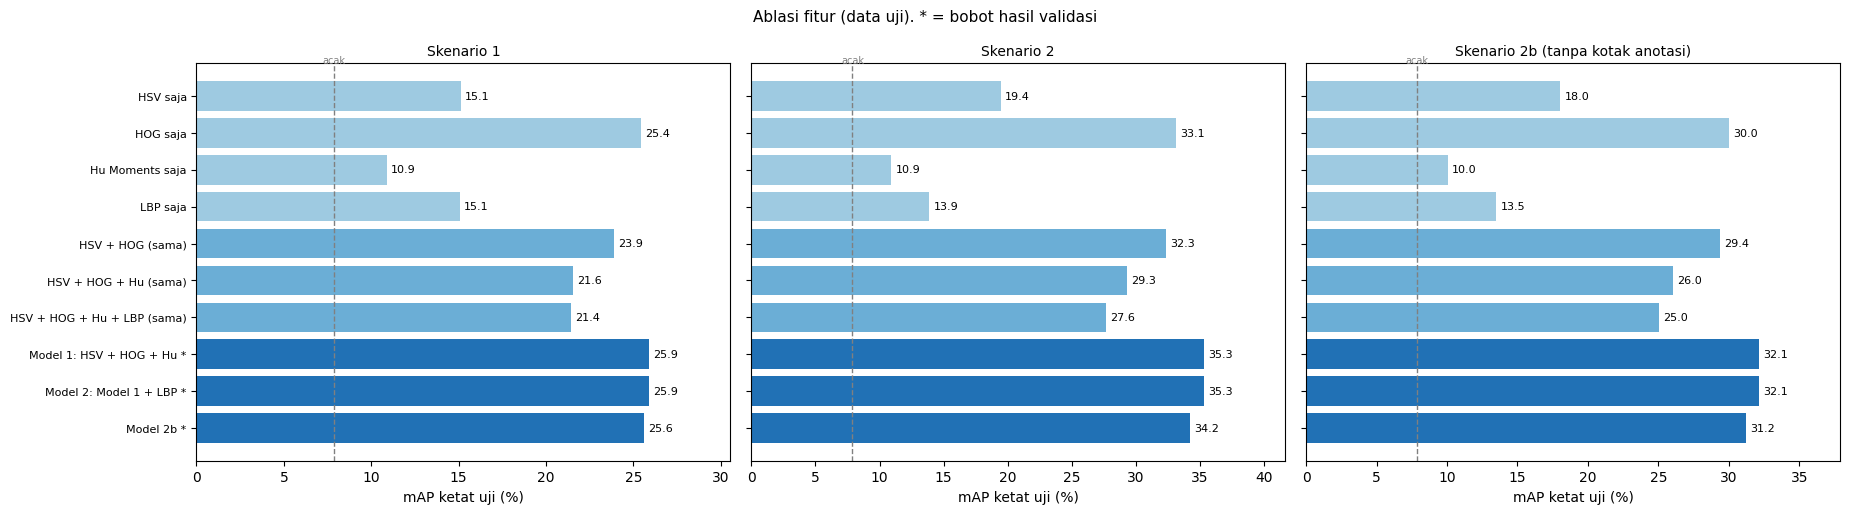

In [17]:
ablation_test_df = pd.DataFrame([r for c in CTX.values() for r in c["ablation_test"]])
for sc_name in ablation_test_df["Skenario"].unique():
    print(f"\nAblasi fitur pada data UJI - {sc_name} (pembanding acak: P@10 = {rand_row['P@10']:.1f}%, mAP = {rand_row['mAP_strict']:.1f}%)")
    display(ablation_test_df[ablation_test_df["Skenario"] == sc_name].drop(columns=["Skenario"]).round(2).reset_index(drop=True))
ablation_test_df.to_csv(WORK_DIR / "ablasi_fitur_uji.csv", index=False)

# Kontribusi marginal tiap fitur terhadap fusi (bobot sama): selisih mAP uji
_marg = []
for sc_name, c in CTX.items():
    t = ablation_test_df[ablation_test_df["Skenario"] == sc_name].set_index("Konfigurasi")["mAP_strict"]
    _marg.append({"Skenario": sc_name,
                  "+ HOG pada HSV (mAP)": t["HSV + HOG (bobot sama)"] - t["HSV saja"],
                  "+ Hu pada HSV+HOG (mAP)": t["HSV + HOG + Hu (bobot sama)"] - t["HSV + HOG (bobot sama)"],
                  "+ LBP pada HSV+HOG+Hu (mAP)": t["HSV + HOG + Hu + LBP (bobot sama)"] - t["HSV + HOG + Hu (bobot sama)"]})
print("\nPerubahan mAP ketat (poin persen) saat satu blok ditambahkan (bobot sama):")
display(pd.DataFrame(_marg).round(2))
pd.DataFrame(_marg).to_csv(WORK_DIR / "kontribusi_marginal_fitur.csv", index=False)

# ---- Grafik ablasi dengan label angka ----
SC_TITLES = {"s1_resize_saja": "Skenario 1", "s2_praproses_penuh": "Skenario 2", "s2b_praproses_otomatis": "Skenario 2b (tanpa kotak anotasi)"}
_scs = list(ablation_test_df["Skenario"].unique())
fig, axes = plt.subplots(1, len(_scs), figsize=(6.2 * len(_scs), 5.2), sharey=True)
axes = np.atleast_1d(axes)
for ax, sc_name in zip(axes, _scs):
    t = ablation_test_df[ablation_test_df["Skenario"] == sc_name].reset_index(drop=True)
    labels = [k.replace(" (bobot validasi)", " *").replace("(bobot sama)", "(sama)").replace("Model 2b (tambahan): semua blok aktif", "Model 2b") for k in t["Konfigurasi"]]
    bars = ax.barh(range(len(t)), t["mAP_strict"], color=["#9ecae1" if i < 4 else "#6baed6" if i < 7 else "#2171b5" for i in range(len(t))])
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8)
    ax.axvline(float(rand_row["mAP_strict"]), color="gray", ls="--", lw=1); ax.text(float(rand_row["mAP_strict"]), -0.9, "acak", fontsize=7, color="gray", ha="center")
    ax.set_yticks(range(len(t))); ax.set_yticklabels(labels, fontsize=8); ax.invert_yaxis()
    ax.set_title(SC_TITLES.get(sc_name, sc_name), fontsize=10); ax.set_xlabel("mAP ketat uji (%)")
    ax.set_xlim(0, float(t["mAP_strict"].max()) * 1.18)
fig.suptitle("Ablasi fitur (data uji). * = bobot hasil validasi", fontsize=11)
plt.tight_layout(); plt.savefig(WORK_DIR / "ablasi_fitur_uji.png", dpi=140, bbox_inches="tight"); plt.show()


## 10c. Interval kepercayaan bootstrap (tambahan)
Kueri uji di-resample dengan pengembalian; selisih antar model dihitung berpasangan pada kueri yang sama. Selisih dianggap bukan kebetulan hanya bila interval 95% tidak memuat 0. Catatan: kueri near-duplicate tidak independen penuh, sehingga interval ini cenderung sedikit optimistis.

In [18]:
def bootstrap_ci(values, n_boot=BOOTSTRAP_N, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(values), size=(n_boot, len(values)))
    means = values[idx].mean(axis=1)
    return float(values.mean()), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

def paired_bootstrap(a, b, n_boot=BOOTSTRAP_N, seed=RANDOM_SEED):
    d = a - b
    mean, lo, hi = bootstrap_ci(d, n_boot, seed)
    return mean, lo, hi, bool(lo > 0 or hi < 0)

boot_rows, diff_rows = [], []
for sc_name, c in CTX.items():
    named = {M_BASE: c["scores_base"], M_BASE_T: c["scores_base_t"], M_BASE_HOG: c["scores_hog_b"], M_1: c["scores_m1"], M_2: c["scores_m2"],
             M_2B: c["scores_m2m"], M_HOGCOS: c["scores_hogcos"], M_HSVHOG_EQ: c["scores_hsvhog_eq"]}
    pq = {}
    for mname, sc in named.items():
        d, vs, _ = per_query_metrics(sc, c["query_indices"], c["gallery_indices"], ks=(10,))
        pq[mname] = d
        for metric, key in (("mAP ketat", "AP_strict"), ("P@10", "P@10")):
            m, lo, hi = bootstrap_ci(d[key][vs])
            boot_rows.append({"Skenario": sc_name, "Model": mname, "Metrik": metric, "Rata-rata (%)": m, "CI95 bawah": lo, "CI95 atas": hi, "Jumlah kueri": int(vs.sum())})
    for a_, b_ in ((M_1, M_BASE), (M_2, M_BASE), (M_2, M_1), (M_2B, M_2),
                   (M_1, M_BASE_T), (M_1, M_BASE_HOG), (M_1, M_HOGCOS), (M_1, M_HSVHOG_EQ)):
        for metric, key in (("mAP ketat", "AP_strict"), ("P@10", "P@10")):
            m, lo, hi, sig = paired_bootstrap(pq[a_][key], pq[b_][key])
            diff_rows.append({"Skenario": sc_name, "A": a_, "B": b_, "Perbandingan": f"{a_}  -  {b_}", "Metrik": metric, "Selisih (poin)": m,
                              "CI95 bawah": lo, "CI95 atas": hi, "Signifikan (CI tak memuat 0)": sig})
boot_df, diff_df = pd.DataFrame(boot_rows), pd.DataFrame(diff_rows)
print("Rata-rata dan interval kepercayaan 95% (bootstrap atas kueri uji):")
display(boot_df.round(2))
print("\nSelisih berpasangan antar model (bootstrap atas kueri yang sama):")
display(diff_df.drop(columns=["A", "B"]).round(2))
boot_df.to_csv(WORK_DIR / "uji_bootstrap_ci.csv", index=False)
diff_df.to_csv(WORK_DIR / "uji_bootstrap_selisih.csv", index=False)


Rata-rata dan interval kepercayaan 95% (bootstrap atas kueri uji):


,Skenario,Model,Metrik,Rata-rata (%),CI95 bawah,CI95 atas,Jumlah kueri
0,s1_resize_saja,Baseline SIFT/SURF/HOG + Euclidean,mAP ketat,24.37,23.19,25.65,348
1,s1_resize_saja,Baseline SIFT/SURF/HOG + Euclidean,P@10,68.28,64.68,71.47,348
2,s1_resize_saja,Baseline [16] dengan bobot dituning di validas...,mAP ketat,23.61,22.42,24.83,348
3,s1_resize_saja,Baseline [16] dengan bobot dituning di validas...,P@10,71.09,67.59,74.02,348
4,s1_resize_saja,Varian baseline: HOG saja + Euclidean (tambahan),mAP ketat,23.96,22.71,25.30,348
5,s1_resize_saja,Varian baseline: HOG saja + Euclidean (tambahan),P@10,66.35,62.81,69.63,348
6,s1_resize_saja,Model 1: HSV + HOG + Hu,mAP ketat,25.90,24.71,27.05,348
7,s1_resize_saja,Model 1: HSV + HOG + Hu,P@10,70.72,67.21,73.79,348
8,s1_resize_saja,Model 2: Model 1 + LBP,mAP ketat,25.90,24.71,27.05,348
9,s1_resize_saja,Model 2: Model 1 + LBP,P@10,70.72,67.21,73.79,348



Selisih berpasangan antar model (bootstrap atas kueri yang sama):


,Skenario,Perbandingan,Metrik,Selisih (poin),CI95 bawah,CI95 atas,Signifikan (CI tak memuat 0)
0,s1_resize_saja,Model 1: HSV + HOG + Hu - Baseline SIFT/SURF...,mAP ketat,1.52,0.85,2.19,True
1,s1_resize_saja,Model 1: HSV + HOG + Hu - Baseline SIFT/SURF...,P@10,2.44,0.80,3.99,True
2,s1_resize_saja,Model 2: Model 1 + LBP - Baseline SIFT/SURF/...,mAP ketat,1.52,0.85,2.19,True
3,s1_resize_saja,Model 2: Model 1 + LBP - Baseline SIFT/SURF/...,P@10,2.44,0.80,3.99,True
4,s1_resize_saja,Model 2: Model 1 + LBP - Model 1: HSV + HOG ...,mAP ketat,0.00,0.00,0.00,False
5,s1_resize_saja,Model 2: Model 1 + LBP - Model 1: HSV + HOG ...,P@10,0.00,0.00,0.00,False
6,s1_resize_saja,Model 2b (tambahan): semua blok aktif - Mode...,mAP ketat,-0.28,-0.39,-0.17,True
7,s1_resize_saja,Model 2b (tambahan): semua blok aktif - Mode...,P@10,-0.95,-1.81,-0.11,True
8,s1_resize_saja,Model 1: HSV + HOG + Hu - Baseline [16] deng...,mAP ketat,2.29,1.15,3.39,True
9,s1_resize_saja,Model 1: HSV + HOG + Hu - Baseline [16] deng...,P@10,-0.37,-2.73,2.01,False


## 10d. Eksperimen tambahan: fitur LBP/Hu alternatif
Model usulan (Hu dari siluet, LBP grid 2x2) **tidak diubah**. Di sini diuji apakah ketidakberhasilan Hu/LBP berasal dari cara ekstraksinya: Hu dari peta tepi, LBP grid 4x4, dan LBP multiskala (P=8,R=1 dan P=16,R=2). Bobot dipilih di validasi; selisih terhadap Model 1 diuji dengan bootstrap berpasangan.

In [19]:
# Eksperimen TAMBAHAN: apakah Hu/LBP berguna bila diekstraksi dengan cara lain? Model usulan (Hu siluet, LBP 2x2) TIDAK diubah.
EXTRA_CONFIGS = {
    "Model 2c-1: HSV + HOG + Hu(tepi)": ["hsv", "hog", "hu_edge"],
    "Model 2c-2: HSV + HOG + LBP halus 4x4": ["hsv", "hog", "lbp_fine"],
    "Model 2c-3: HSV + HOG + LBP multiskala": ["hsv", "hog", "lbp_ms"],
    "Model 2c-4: HSV + HOG + Hu(tepi) + LBP halus": ["hsv", "hog", "hu_edge", "lbp_fine"],
}
extra_rows, extra_alone = [], []
if RUN_EXTRA_FEATURES:
    for sc_name in ("s2_praproses_penuh", "s2b_praproses_otomatis"):
        if sc_name not in CTX:
            continue
        c = CTX[sc_name]; raw = FEATURES[sc_name]; spec = NORM_MODES[c["norm_mode"]]
        names_all = ["hsv", "hog", "hu", "lbp", "hu_edge", "lbp_fine", "lbp_ms"]
        gn_v, qn_v, _ = prepare_feature_blocks(raw, train_idx, val_idx, center=spec["center"], names=names_all)
        gn_t, qn_t, _ = prepare_feature_blocks(raw, gallery_idx, test_idx, center=spec["center"], names=names_all)
        sv = cosine_blocks(gn_v, qn_v, names_all, spec["zs"]); st = cosine_blocks(gn_t, qn_t, names_all, spec["zs"])
        for b in ("hu", "hu_edge", "lbp", "lbp_fine", "lbp_ms"):
            mm = metrics_from_scores(st[b], test_idx, gallery_idx)
            extra_alone.append({"Skenario": sc_name, "Fitur sendirian": b, "Dimensi": int(raw[b].shape[1]), "P@10": mm["P@10"], "mAP_strict": mm["mAP_strict"]})
        d1, vs1, _ = per_query_metrics(c["scores_m1"], test_idx, gallery_idx, ks=(10,))
        for cname, blocks in EXTRA_CONFIGS.items():
            h = evaluate_weight_grid({b: sv[b] for b in blocks}, val_idx, train_idx, blocks)
            w, vm = select_weights(h, blocks, verbose=False)
            sc = combine_similarity({b: st[b] for b in blocks}, w)
            mm = metrics_from_scores(sc, test_idx, gallery_idx)
            d, vs, _ = per_query_metrics(sc, test_idx, gallery_idx, ks=(10,))
            dm, lo, hi, sig = paired_bootstrap(d["AP_strict"][vs & vs1], d1["AP_strict"][vs & vs1])
            extra_rows.append({"Skenario": sc_name, "Konfigurasi": cname, "Bobot": json.dumps({k: round(v, 2) for k, v in w.items()}),
                               "mAP validasi": vm, "P@10 uji": mm["P@10"], "mAP uji": mm["mAP_strict"],
                               "Selisih mAP vs Model 1": dm, "CI95 bawah": lo, "CI95 atas": hi, "Signifikan": sig})
    extra_alone_df, extra_df = pd.DataFrame(extra_alone), pd.DataFrame(extra_rows)
    print("Fitur alternatif SENDIRIAN pada data uji (pembanding acak: mAP %.1f%%):" % float(rand_row["mAP_strict"]))
    display(extra_alone_df.round(2))
    print("\nFusi dengan fitur alternatif (bobot dari validasi) dibandingkan dengan Model 1:")
    display(extra_df.round(2))
    extra_alone_df.to_csv(WORK_DIR / "tambahan_fitur_alternatif_sendirian.csv", index=False)
    extra_df.to_csv(WORK_DIR / "tambahan_fitur_alternatif_fusi.csv", index=False)
else:
    extra_alone_df = extra_df = pd.DataFrame()
    print("RUN_EXTRA_FEATURES = False: eksperimen fitur alternatif dilewati.")


Fitur alternatif SENDIRIAN pada data uji (pembanding acak: mAP 7.9%):


,Skenario,Fitur sendirian,Dimensi,P@10,mAP_strict
0,s2_praproses_penuh,hu,7,16.98,10.92
1,s2_praproses_penuh,hu_edge,7,23.88,12.89
2,s2_praproses_penuh,lbp,236,39.08,13.89
3,s2_praproses_penuh,lbp_fine,944,49.66,18.36
4,s2_praproses_penuh,lbp_ms,448,47.76,19.01
5,s2b_praproses_otomatis,hu,7,14.08,10.04
6,s2b_praproses_otomatis,hu_edge,7,22.96,12.28
7,s2b_praproses_otomatis,lbp,236,35.00,13.49
8,s2b_praproses_otomatis,lbp_fine,944,44.54,17.12
9,s2b_praproses_otomatis,lbp_ms,448,42.07,17.84



Fusi dengan fitur alternatif (bobot dari validasi) dibandingkan dengan Model 1:


,Skenario,Konfigurasi,Bobot,mAP validasi,P@10 uji,mAP uji,Selisih mAP vs Model 1,CI95 bawah,CI95 atas,Signifikan
0,s2_praproses_penuh,Model 2c-1: HSV + HOG + Hu(tepi),"{""hsv"": 0.2, ""hog"": 0.6, ""hu_edge"": 0.2}",35.34,76.09,35.50,0.22,-0.07,0.49,False
1,s2_praproses_penuh,Model 2c-2: HSV + HOG + LBP halus 4x4,"{""hsv"": 0.3, ""hog"": 0.7, ""lbp_fine"": 0.0}",34.55,77.36,35.28,0.00,0.00,0.00,False
2,s2_praproses_penuh,Model 2c-3: HSV + HOG + LBP multiskala,"{""hsv"": 0.3, ""hog"": 0.7, ""lbp_ms"": 0.0}",34.55,77.36,35.28,0.00,0.00,0.00,False
3,s2_praproses_penuh,Model 2c-4: HSV + HOG + Hu(tepi) + LBP halus,"{""hsv"": 0.2, ""hog"": 0.6, ""hu_edge"": 0.2, ""lbp_...",35.34,76.09,35.50,0.22,-0.07,0.49,False
4,s2b_praproses_otomatis,Model 2c-1: HSV + HOG + Hu(tepi),"{""hsv"": 0.2, ""hog"": 0.6, ""hu_edge"": 0.2}",31.72,72.21,32.41,0.30,0.03,0.57,True
5,s2b_praproses_otomatis,Model 2c-2: HSV + HOG + LBP halus 4x4,"{""hsv"": 0.3, ""hog"": 0.7, ""lbp_fine"": 0.0}",31.16,72.44,32.11,0.00,0.00,0.00,False
6,s2b_praproses_otomatis,Model 2c-3: HSV + HOG + LBP multiskala,"{""hsv"": 0.3, ""hog"": 0.7, ""lbp_ms"": 0.0}",31.16,72.44,32.11,0.00,0.00,0.00,False
7,s2b_praproses_otomatis,Model 2c-4: HSV + HOG + Hu(tepi) + LBP halus,"{""hsv"": 0.2, ""hog"": 0.6, ""hu_edge"": 0.2, ""lbp_...",31.72,72.21,32.41,0.30,0.03,0.57,True


## 11. Skenario 3 — uji ketahanan
Citra kueri diubah secara sintetis (rotasi ±15°, kecerahan ×0,7/×1,3, skala 0,8, pemotongan tepi 20%) setelah pra-pemrosesan penuh; galeri tidak diubah.

In [20]:
def apply_perturbation(bgr, cmask, smask, kind):
    image, cm, sm = bgr.copy(), cmask.copy(), smask.copy()
    h, w = image.shape[:2]
    if kind in (None, "none"):
        return image, cm, sm
    if kind in {"rotate_plus", "rotate_minus"}:
        M = cv2.getRotationMatrix2D((w / 2, h / 2), 15 if kind == "rotate_plus" else -15, 1.0)
        image = cv2.warpAffine(image, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=(255, 255, 255))
        cm = cv2.warpAffine(cm, M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        sm = cv2.warpAffine(sm, M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    elif kind in {"brightness_down", "brightness_up"}:
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
        hsv[:, :, 2] = np.clip(hsv[:, :, 2].astype(np.float32) * (0.70 if kind == "brightness_down" else 1.30), 0, 255).astype(np.uint8)
        image = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
    elif kind == "scale_0.8":
        nw, nh = max(1, int(w * 0.8)), max(1, int(h * 0.8))
        x0, y0 = (w - nw) // 2, (h - nh) // 2
        small = cv2.resize(image, (nw, nh), interpolation=cv2.INTER_AREA)
        image = np.full_like(image, 255); image[y0:y0 + nh, x0:x0 + nw] = small
        c2 = np.zeros_like(cm); c2[y0:y0 + nh, x0:x0 + nw] = cv2.resize(cm, (nw, nh), interpolation=cv2.INTER_NEAREST); cm = c2
        s2 = np.zeros_like(sm); s2[y0:y0 + nh, x0:x0 + nw] = cv2.resize(sm, (nw, nh), interpolation=cv2.INTER_NEAREST); sm = s2
    elif kind == "crop_edge_20":
        y0, y1, x0, x1 = int(0.1 * h), int(0.9 * h), int(0.1 * w), int(0.9 * w)
        image = cv2.resize(image[y0:y1, x0:x1], IMAGE_SIZE, interpolation=cv2.INTER_AREA)
        cm = cv2.resize(cm[y0:y1, x0:x1], IMAGE_SIZE, interpolation=cv2.INTER_NEAREST)
        sm = cv2.resize(sm[y0:y1, x0:x1], IMAGE_SIZE, interpolation=cv2.INTER_NEAREST)
    return image, cm, sm

def normalize_query_blocks(raw_q, scaler):
    out = {}
    for b in BLOCKS_M2:
        v = np.asarray(raw_q[b], np.float32).reshape(1, -1)
        if b == "hu":
            v = (v - scaler["mean"]) / scaler["std"]
        elif b in scaler.get("center", {}):
            v = v - scaler["center"][b]
        out[b] = l2_normalize_rows(v)[0]
    return out

def scores_single(qblocks, gn, weights, zs=False):
    s = np.zeros(len(next(iter(gn.values()))), np.float32)
    for b, w in weights.items():
        sb = gn[b] @ qblocks[b]
        s += float(w) * (standardize_scores(sb) if zs else sb)
    return s

def baseline_vector_single(raw_q, names):
    parts = [l2_normalize_rows(np.asarray(raw_q[n], np.float32).reshape(1, -1))[0] / math.sqrt(len(names)) for n in names]
    return np.concatenate(parts).astype(np.float32)

PERTURB_CASES = [("Tanpa perturbasi", [None]), ("Rotasi ±15°", ["rotate_plus", "rotate_minus"]),
                 ("Kecerahan ±30%", ["brightness_down", "brightness_up"]), ("Skala 0,8 kali", ["scale_0.8"]),
                 ("Pemotongan tepi 20%", ["crop_edge_20"])]
MODEL_NAMES = [M_BASE, M_1, M_2, M_BASE_T]

def baseline_tuned_single(raw_q, ctx):
    """Skor baseline dengan bobot dituning (tambahan) untuk satu kueri."""
    g = ctx["baseline_blocks_g"]; s = np.zeros(len(next(iter(g.values()))), np.float32)
    for n, w in ctx["wb"].items():
        q = l2_normalize_rows(np.asarray(raw_q[n], np.float32).reshape(1, -1))[0]
        s -= float(w) * ((g[n] - q[None, :]) ** 2).sum(1)
    return s

def apply_perturbation_raw(bgr, kind):
    """(tambahan) Perturbasi pada citra MENTAH sebelum pra-pemrosesan: seluruh pipeline (segmentasi dan crop ulang) ikut diuji."""
    if kind in (None, "none"):
        return bgr.copy()
    h, w = bgr.shape[:2]
    if kind in {"rotate_plus", "rotate_minus"}:
        M = cv2.getRotationMatrix2D((w / 2, h / 2), 15 if kind == "rotate_plus" else -15, 1.0)
        return cv2.warpAffine(bgr, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=(255, 255, 255))
    if kind in {"brightness_down", "brightness_up"}:
        hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
        hsv[:, :, 2] = np.clip(hsv[:, :, 2].astype(np.float32) * (0.70 if kind == "brightness_down" else 1.30), 0, 255).astype(np.uint8)
        return cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
    if kind == "scale_0.8":
        nw, nh = max(1, int(w * 0.8)), max(1, int(h * 0.8))
        canvas = np.full_like(bgr, 255); x0, y0 = (w - nw) // 2, (h - nh) // 2
        canvas[y0:y0 + nh, x0:x0 + nw] = cv2.resize(bgr, (nw, nh), interpolation=cv2.INTER_AREA)
        return canvas
    if kind == "crop_edge_20":
        return bgr[int(0.1 * h):int(0.9 * h), int(0.1 * w):int(0.9 * w)].copy()
    return bgr.copy()

def _robust_task(args):
    cv2.setNumThreads(1)
    path, bbox, kind = args
    bgr, cm, sm, use_mask = preprocess_image(path, bbox=bbox, full_preprocess=True)
    bgr, cm, sm = apply_perturbation(bgr, cm, sm, kind)
    return extract_raw_features_from_arrays(bgr, cm, sm, use_mask_for_visual=True)

def _robust_raw_task(args):
    cv2.setNumThreads(1)
    path, _bbox, kind = args
    img = apply_perturbation_raw(cv2.imread(str(path)), kind)
    bgr, cm, sm, use_mask = preprocess_image(path, bbox=None, full_preprocess=True, image=img)   # tanpa kotak anotasi (tidak valid setelah perturbasi)
    return extract_raw_features_from_arrays(bgr, cm, sm, use_mask_for_visual=True)

def run_robustness(ctx, raw_image=False):
    """raw_image=False: sesuai proposal (perturbasi SETELAH pra-pemrosesan penuh). raw_image=True: tambahan (perturbasi pada citra mentah)."""
    task = _robust_raw_task if raw_image else _robust_task
    rng = np.random.default_rng(RANDOM_SEED)
    q = ctx["query_indices"]
    sel = q if (ROBUSTNESS_MAX_QUERIES is None or len(q) <= ROBUSTNESS_MAX_QUERIES) else np.sort(rng.choice(q, ROBUSTNESS_MAX_QUERIES, replace=False))
    g_global = ctx["gallery_indices"]
    collected = {(c, m): [] for c, _ in PERTURB_CASES for m in MODEL_NAMES}
    count_pool = []
    for case, variants in PERTURB_CASES:
        for kind in variants:
            raws = parallel_map(task, [(paths_all[int(i)], None if raw_image else records_df.at[int(i), "bbox"], kind) for i in sel], f"{case} | {kind or 'asli'}")
            for gi, raw_q in zip(sel, raws):
                qb = normalize_query_blocks(raw_q, ctx["hu_scaler"])
                sc = {MODEL_NAMES[0]: -cdist(baseline_vector_single(raw_q, ctx["baseline_names"])[None, :], ctx["baseline_gallery_vec"])[0],
                      MODEL_NAMES[1]: scores_single(qb, ctx["gallery_norm"], ctx["w1"], ctx["zs"]),
                      MODEL_NAMES[2]: scores_single(qb, ctx["gallery_norm"], ctx["w2"], ctx["zs"]),
                      MODEL_NAMES[3]: baseline_tuned_single(raw_q, ctx)}
                for m, s in sc.items():
                    collected[(case, m)].append(metrics_from_scores(s[None, :], [gi], g_global))
                count_pool += count_rows(sc[MODEL_NAMES[2]][None, :], [gi], g_global)
    rows = []
    for case, _ in PERTURB_CASES:
        for m in MODEL_NAMES:
            rows.append({"Perturbasi": case, "Model": m, "Jumlah kueri": len(sel), **pd.DataFrame(collected[(case, m)]).mean(numeric_only=True).to_dict()})
    return pd.DataFrame(rows), count_pool

robust_df, robust_counts = run_robustness(ctx_s2)
display(robust_df.round(3))
robust_df.to_csv(WORK_DIR / "hasil_ketahanan.csv", index=False)

# ---- TAMBAHAN: ketahanan dengan perturbasi pada citra mentah (kondisi pipeline website: tanpa kotak anotasi, gudang fitur S2b) ----
robust_raw_df = None
if RUN_ROBUST_RAW and UNIT_MODE == "image" and ctx_s2b is not None:
    robust_raw_df, _ = run_robustness(ctx_s2b, raw_image=True)
    print("Tambahan - ketahanan, perturbasi pada citra mentah (Skenario 2b):")
    display(robust_raw_df.round(3))
    robust_raw_df.to_csv(WORK_DIR / "hasil_ketahanan_citra_mentah.csv", index=False)
else:
    print("Ketahanan citra mentah dilewati.")

Tanpa perturbasi | asli: 100%|██████████| 3/3 [00:04<00:00,  1.61s/it]
Rotasi ±15° | rotate_plus: 100%|██████████| 3/3 [00:01<00:00,  1.52it/s]
Rotasi ±15° | rotate_minus: 100%|██████████| 3/3 [00:01<00:00,  1.50it/s]
Kecerahan ±30% | brightness_down: 100%|██████████| 3/3 [00:02<00:00,  1.40it/s]
Kecerahan ±30% | brightness_up: 100%|██████████| 3/3 [00:01<00:00,  1.54it/s]
Skala 0,8 kali | scale_0.8: 100%|██████████| 3/3 [00:01<00:00,  1.56it/s]
Pemotongan tepi 20% | crop_edge_20: 100%|██████████| 3/3 [00:02<00:00,  1.49it/s]


,Perturbasi,Model,Jumlah kueri,P@1,P@5,R@5,P@10,R@10,P@20,R@20,R@50,R@100,R@200,R-Prec,mAP_strict,mAP_loose
0,Tanpa perturbasi,Baseline SIFT/SURF/HOG + Euclidean,100,88.0,81.4,1.218,75.10,2.249,68.650,4.113,8.794,15.077,24.535,33.744,32.013,41.392
1,Tanpa perturbasi,Model 1: HSV + HOG + Hu,100,90.0,84.2,1.259,80.10,2.396,73.900,4.420,9.398,16.105,26.078,36.358,36.203,47.017
2,Tanpa perturbasi,Model 2: Model 1 + LBP,100,90.0,84.2,1.259,80.10,2.396,73.900,4.420,9.398,16.105,26.078,36.358,36.203,47.017
3,Tanpa perturbasi,Baseline [16] dengan bobot dituning di validas...,100,89.0,82.6,1.237,78.20,2.342,71.100,4.260,9.088,15.522,25.003,34.437,33.137,42.629
4,Rotasi ±15°,Baseline SIFT/SURF/HOG + Euclidean,100,76.5,68.3,1.023,62.60,1.877,55.500,3.332,7.185,12.338,20.288,28.670,26.289,35.812
5,Rotasi ±15°,Model 1: HSV + HOG + Hu,100,83.0,75.5,1.130,70.20,2.102,63.600,3.811,8.089,13.728,22.388,31.653,30.036,41.183
6,Rotasi ±15°,Model 2: Model 1 + LBP,100,83.0,75.5,1.130,70.20,2.102,63.600,3.811,8.089,13.728,22.388,31.653,30.036,41.183
7,Rotasi ±15°,Baseline [16] dengan bobot dituning di validas...,100,83.5,72.0,1.078,66.55,1.994,59.725,3.581,7.539,13.099,21.622,30.519,28.406,38.167
8,Kecerahan ±30%,Baseline SIFT/SURF/HOG + Euclidean,100,88.5,79.6,1.191,74.00,2.216,67.300,4.033,8.703,14.893,24.521,33.781,31.848,41.085
9,Kecerahan ±30%,Model 1: HSV + HOG + Hu,100,87.0,81.8,1.223,76.60,2.292,70.550,4.223,9.032,15.537,25.351,35.326,34.900,45.983


Tanpa perturbasi | asli: 100%|██████████| 3/3 [00:02<00:00,  1.44it/s]
Rotasi ±15° | rotate_plus: 100%|██████████| 3/3 [00:02<00:00,  1.19it/s]
Rotasi ±15° | rotate_minus: 100%|██████████| 3/3 [00:02<00:00,  1.13it/s]
Kecerahan ±30% | brightness_down: 100%|██████████| 3/3 [00:02<00:00,  1.33it/s]
Kecerahan ±30% | brightness_up: 100%|██████████| 3/3 [00:02<00:00,  1.35it/s]
Skala 0,8 kali | scale_0.8: 100%|██████████| 3/3 [00:01<00:00,  2.18it/s]
Pemotongan tepi 20% | crop_edge_20: 100%|██████████| 3/3 [00:02<00:00,  1.00it/s]


Tambahan - ketahanan, perturbasi pada citra mentah (Skenario 2b):


,Perturbasi,Model,Jumlah kueri,P@1,P@5,R@5,P@10,R@10,P@20,R@20,R@50,R@100,R@200,R-Prec,mAP_strict,mAP_loose
0,Tanpa perturbasi,Baseline SIFT/SURF/HOG + Euclidean,100,86.0,78.4,1.173,70.70,2.117,63.250,3.790,8.188,13.817,22.223,30.869,30.151,42.039
1,Tanpa perturbasi,Model 1: HSV + HOG + Hu,100,89.0,85.6,1.280,78.30,2.342,69.850,4.178,8.865,15.377,25.370,35.455,35.224,46.789
2,Tanpa perturbasi,Model 2: Model 1 + LBP,100,89.0,85.6,1.280,78.30,2.342,69.850,4.178,8.865,15.377,25.370,35.455,35.224,46.789
3,Tanpa perturbasi,Baseline [16] dengan bobot dituning di validas...,100,88.0,80.2,1.201,73.80,2.210,65.650,3.934,8.264,13.945,22.632,31.643,31.128,43.016
4,Rotasi ±15°,Baseline SIFT/SURF/HOG + Euclidean,100,76.5,64.9,0.973,57.00,1.711,50.200,3.014,6.075,10.290,17.184,24.799,23.261,35.196
5,Rotasi ±15°,Model 1: HSV + HOG + Hu,100,79.0,72.5,1.085,65.90,1.974,58.300,3.495,7.215,12.071,19.648,27.968,26.534,38.382
6,Rotasi ±15°,Model 2: Model 1 + LBP,100,79.0,72.5,1.085,65.90,1.974,58.300,3.495,7.215,12.071,19.648,27.968,26.534,38.382
7,Rotasi ±15°,Baseline [16] dengan bobot dituning di validas...,100,84.0,72.3,1.084,63.65,1.910,55.700,3.344,6.784,11.458,18.955,26.993,26.040,37.651
8,Kecerahan ±30%,Baseline SIFT/SURF/HOG + Euclidean,100,85.0,77.0,1.152,70.70,2.116,62.625,3.751,8.004,13.542,21.834,30.452,29.778,41.494
9,Kecerahan ±30%,Model 1: HSV + HOG + Hu,100,87.5,83.2,1.244,77.50,2.318,68.800,4.116,8.690,15.141,25.017,34.878,34.664,45.986


## 12. Skenario 4 — Model 3 (Relevance feedback Rocchio)
Umpan balik disimulasikan dari label pada 10 hasil teratas (label sama = positif, lainnya = negatif). Citra yang sudah dinilai dikeluarkan dari peringkat berikutnya (*residual ranking*). Karena galeri residual mengecil dan kehilangan citra relevan teratas, metrik antar putaran **tidak sebanding langsung**; karena itu dihitung juga (a) **kontrol tanpa umpan balik** pada galeri residual yang sama besar dan (b) **presisi kumulatif** semua citra yang sudah ditampilkan.

Simulasi Rocchio (w2): 100%|██████████| 348/348 [00:05<00:00, 60.60it/s]

Model 3 (bobot Model 2 hasil validasi, sesuai proposal):


,Model,Putaran,Jumlah kueri,P@1,P@5,R@5,P@10,R@10,P@20,R@20,R@50,R@100,R@200,R-Prec,mAP_strict,mAP_loose,P_kumulatif_RF,P_kumulatif_kontrol
0,Model 3 - Rocchio putaran 0,0,348,87.931,82.874,1.235,77.356,2.307,70.661,4.215,9.000,15.398,25.372,35.812,35.279,46.871,77.356,77.356
1,Model 3 - Rocchio putaran 1,1,348,91.092,83.218,1.271,77.500,2.370,71.825,4.395,9.479,16.322,26.967,37.268,37.095,49.078,77.428,70.661
2,Model 3 - Rocchio putaran 2,2,348,94.253,86.494,1.354,80.632,2.528,73.879,4.638,9.974,17.212,28.416,38.604,38.707,50.797,78.496,66.121
3,Model 3 - Rocchio putaran 3,3,348,93.103,84.483,1.359,79.971,2.576,73.894,4.767,10.347,17.887,29.476,39.422,39.581,51.897,78.865,62.874


Kontrol tanpa umpan balik (galeri residual sama besar):


,Model,Putaran,Jumlah kueri,P@1,P@5,R@5,P@10,R@10,P@20,R@20,R@50,R@100,R@200,R-Prec,mAP_strict,mAP_loose
0,"Kontrol: Model 2 tanpa umpan balik, galeri res...",0,348,87.931,82.874,1.235,77.356,2.307,70.661,4.215,9.000,15.398,25.372,35.812,35.279,46.871
1,"Kontrol: Model 2 tanpa umpan balik, galeri res...",1,348,65.230,67.241,1.030,63.966,1.959,60.503,3.709,8.324,14.562,24.542,34.480,32.840,45.128
2,"Kontrol: Model 2 tanpa umpan balik, galeri res...",2,348,58.333,58.448,0.919,57.040,1.792,55.086,3.459,7.905,14.037,24.005,33.488,31.261,43.871
3,"Kontrol: Model 2 tanpa umpan balik, galeri res...",3,348,53.736,54.368,0.872,53.132,1.705,51.552,3.306,7.612,13.674,23.578,32.617,29.987,42.868


Simulasi Rocchio (w2m): 100%|██████████| 348/348 [00:06<00:00, 57.53it/s]

Tambahan - Model 3 di atas Model 2b (semua blok aktif):


,Model,Putaran,Jumlah kueri,P@1,P@5,R@5,P@10,R@10,P@20,R@20,R@50,R@100,R@200,R-Prec,mAP_strict,mAP_loose,P_kumulatif_RF,P_kumulatif_kontrol
0,Model 3 - Rocchio putaran 0,0,348,87.644,82.414,1.228,75.948,2.265,68.951,4.114,8.799,15.095,24.982,34.997,34.234,45.954,75.948,75.948
1,Model 3 - Rocchio putaran 1,1,348,93.103,83.621,1.277,76.322,2.333,70.431,4.309,9.320,16.025,26.513,36.488,35.891,48.040,76.135,68.951
2,Model 3 - Rocchio putaran 2,2,348,93.103,87.126,1.363,80.833,2.532,73.693,4.623,9.889,16.809,27.699,37.424,37.160,49.487,77.701,64.540
3,Model 3 - Rocchio putaran 3,3,348,94.828,85.575,1.375,80.489,2.590,73.836,4.761,10.216,17.447,28.533,38.005,37.727,50.299,78.398,61.501


Simulasi Rocchio (w2, S2b): 100%|██████████| 348/348 [00:05<00:00, 67.21it/s]


Ringkasan relevance feedback: RF vs kontrol tanpa umpan balik (bootstrap berpasangan atas kueri):


,Kueri,Jumlah kueri,mAP putaran 0,mAP RF putaran 3,mAP kontrol putaran 3,Selisih mAP (RF - kontrol),CI95 bawah,CI95 atas,Signifikan,P@10 RF putaran 3,P@10 kontrol putaran 3,P kumulatif RF,P kumulatif kontrol
0,"Skenario 2, semua kueri uji",348,35.28,39.58,29.99,9.59,8.59,10.69,True,79.97,53.13,78.86,62.87
1,"Skenario 2, tanpa kueri near-duplicate",249,35.23,40.60,30.03,10.57,9.32,11.96,True,81.33,52.01,79.35,61.96
2,"Skenario 2b (tanpa kotak anotasi), semua kueri",348,32.11,36.96,27.15,9.82,8.84,10.85,True,75.78,46.38,73.57,56.99


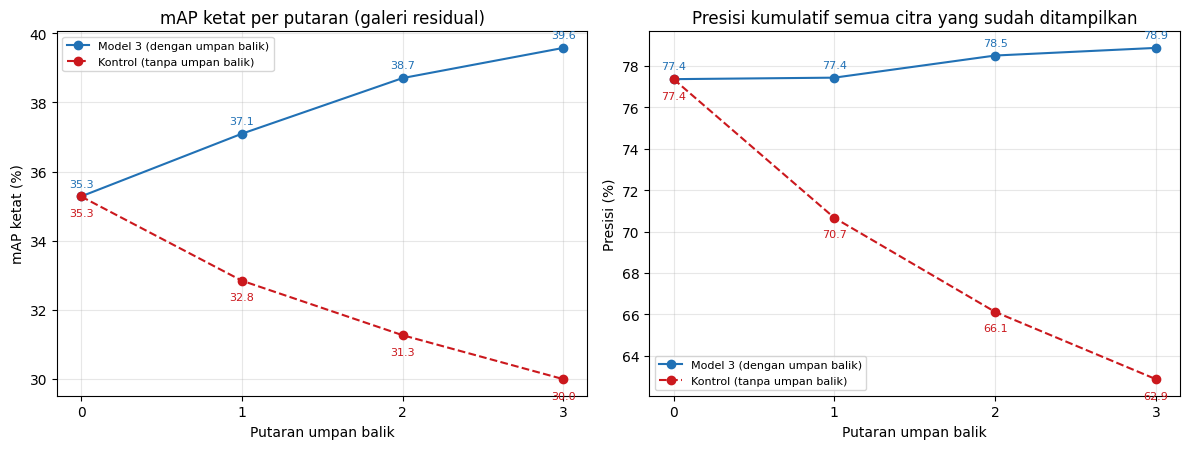

In [21]:
def rocchio_update(qblocks, gn, pos, neg):
    out = {}
    for b in BLOCKS_M2:
        q = ROCCHIO_ALPHA * np.asarray(qblocks[b], np.float32)
        if len(pos): q = q + ROCCHIO_BETA * gn[b][pos].mean(axis=0)
        if len(neg): q = q - ROCCHIO_GAMMA * gn[b][neg].mean(axis=0)
        n = float(np.linalg.norm(q)); out[b] = (q / n if n > 1e-12 else q).astype(np.float32)
    return out

def run_rocchio(ctx, wkey="w2", subset=None, label=""):
    """Simulasi Rocchio (Persamaan 8) dengan residual ranking, putaran 0..FEEDBACK_ROUNDS.
    Selain metrik residual (sesuai proposal), dihitung dua pembanding yang adil:
      - KONTROL tanpa umpan balik: peringkat awal yang SAMA, dengan jumlah citra terbuang yang sama per putaran
        (galeri residual identik ukurannya), sehingga selisih dengan Model 3 = efek umpan balik, bukan efek galeri mengecil.
      - Presisi KUMULATIF: proporsi relevan di antara semua citra yang sudah ditampilkan sampai putaran tsb."""
    gn, wts, g_global, zs = ctx["gallery_norm"], ctx[wkey], ctx["gallery_indices"], ctx["zs"]
    g_lab = LAB_ID[g_global]
    q_global = ctx["query_indices"]
    pos_ids = np.arange(len(q_global)) if subset is None else np.where(np.asarray(subset, bool))[0]
    if FEEDBACK_MAX_QUERIES is not None and len(pos_ids) > FEEDBACK_MAX_QUERIES:
        pos_ids = np.sort(np.random.default_rng(RANDOM_SEED).choice(pos_ids, FEEDBACK_MAX_QUERIES, replace=False))
    R, K = FEEDBACK_ROUNDS, FEEDBACK_TOP_K
    per_round = {r: [] for r in range(R + 1)}; per_ctrl = {r: [] for r in range(R + 1)}
    cum_rf = {r: [] for r in range(R + 1)}; cum_ct = {r: [] for r in range(R + 1)}
    final_counts = []
    for qp in tqdm(pos_ids, desc=f"Simulasi Rocchio ({wkey}{label})"):
        qg = int(q_global[qp]); qlab = LAB_ID[qg]
        qb = {b: ctx["query_norm"][b][qp].copy() for b in BLOCKS_M2}
        sc0 = scores_single(qb, gn, wts, zs)
        order0 = np.argsort(-sc0, kind="stable")
        excluded = np.zeros(len(g_global), dtype=bool); shown = []
        for rnd in range(R + 1):
            cand = np.where(~excluded)[0]
            sc = scores_single(qb, gn, wts, zs)[cand]
            ranked = cand[np.argsort(-sc, kind="stable")]
            per_round[rnd].append(metrics_from_scores(sc[None, :], [qg], g_global[cand]))
            cc = order0[K * rnd:]                                          # kontrol: buang K*rnd teratas peringkat awal
            per_ctrl[rnd].append(metrics_from_scores(sc0[cc][None, :], [qg], g_global[cc]))
            screen = ranked[:min(K, len(ranked))]; shown.extend(screen.tolist())
            cum_rf[rnd].append(float(np.mean(g_lab[shown] == qlab)) * 100)
            cum_ct[rnd].append(float(np.mean(g_lab[order0[:K * (rnd + 1)]] == qlab)) * 100)
            if rnd == R:
                final_counts += count_rows(sc[None, :], [qg], g_global[cand]); break
            pos = screen[g_lab[screen] == qlab]; neg = screen[g_lab[screen] != qlab]
            qb = rocchio_update(qb, gn, pos, neg)
            excluded[screen] = True
    rows = [{"Model": f"Model 3 - Rocchio putaran {r}", "Putaran": r, "Jumlah kueri": len(pos_ids),
             **pd.DataFrame(per_round[r]).mean(numeric_only=True).to_dict(),
             "P_kumulatif_RF": float(np.mean(cum_rf[r])), "P_kumulatif_kontrol": float(np.mean(cum_ct[r]))} for r in range(R + 1)]
    ctrl = [{"Model": f"Kontrol: Model 2 tanpa umpan balik, galeri residual putaran {r}", "Putaran": r, "Jumlah kueri": len(pos_ids),
             **pd.DataFrame(per_ctrl[r]).mean(numeric_only=True).to_dict()} for r in range(R + 1)]
    R1 = range(R + 1)
    perq = {"ap_rf": np.array([[d["mAP_strict"] for d in per_round[r]] for r in R1]), "ap_ct": np.array([[d["mAP_strict"] for d in per_ctrl[r]] for r in R1]),
            "p10_rf": np.array([[d["P@10"] for d in per_round[r]] for r in R1]), "p10_ct": np.array([[d["P@10"] for d in per_ctrl[r]] for r in R1])}
    return pd.DataFrame(rows), final_counts, pd.DataFrame(ctrl), perq

feedback_df, rf_counts, control_df, perq_all = run_rocchio(ctx_s2, "w2")
print("Model 3 (bobot Model 2 hasil validasi, sesuai proposal):")
display(feedback_df.round(3))
print("Kontrol tanpa umpan balik (galeri residual sama besar):")
display(control_df.round(3))
feedback_df.to_csv(WORK_DIR / "hasil_relevance_feedback.csv", index=False)
control_df.to_csv(WORK_DIR / "hasil_relevance_feedback_kontrol.csv", index=False)

# Tambahan: Model 3 di atas Model 2b (semua blok aktif) bila bobotnya berbeda dari Model 2
feedback_df_b = control_df_b = None
if ctx_s2["w2m"] != ctx_s2["w2"]:
    feedback_df_b, _, control_df_b, _ = run_rocchio(ctx_s2, "w2m")
    print("Tambahan - Model 3 di atas Model 2b (semua blok aktif):")
    display(feedback_df_b.round(3))
    feedback_df_b.to_csv(WORK_DIR / "hasil_relevance_feedback_model2b.csv", index=False)

# ---- TAMBAHAN: robustnes hasil umpan balik -> (a) tanpa kueri near-duplicate, (b) Skenario 2b (tanpa kotak anotasi) ----
RF_RUNS = {"Skenario 2, semua kueri uji": (feedback_df, control_df, perq_all)}
_fb, _, _ct, _pq = run_rocchio(ctx_s2, "w2", subset=~NEAR_DUP_MASK, label=", tanpa near-duplicate")
RF_RUNS["Skenario 2, tanpa kueri near-duplicate"] = (_fb, _ct, _pq)
if ctx_s2b is not None:
    _fb, _, _ct, _pq = run_rocchio(ctx_s2b, "w2", label=", S2b")
    RF_RUNS["Skenario 2b (tanpa kotak anotasi), semua kueri"] = (_fb, _ct, _pq)

def _boot_diff(a, b):
    ok = ~(np.isnan(a) | np.isnan(b))
    m, lo, hi, sig = paired_bootstrap(a[ok], b[ok]); return m, lo, hi, sig

rf_rows = []
for name_, (fb_, ct_, pq_) in RF_RUNS.items():
    R_ = FEEDBACK_ROUNDS
    m, lo, hi, sig = _boot_diff(pq_["ap_rf"][R_], pq_["ap_ct"][R_])
    rf_rows.append({"Kueri": name_, "Jumlah kueri": int(fb_["Jumlah kueri"].iloc[0]),
                    "mAP putaran 0": fb_.loc[0, "mAP_strict"], f"mAP RF putaran {R_}": fb_.loc[R_, "mAP_strict"], f"mAP kontrol putaran {R_}": ct_.loc[R_, "mAP_strict"],
                    "Selisih mAP (RF - kontrol)": m, "CI95 bawah": lo, "CI95 atas": hi, "Signifikan": sig,
                    f"P@10 RF putaran {R_}": fb_.loc[R_, "P@10"], f"P@10 kontrol putaran {R_}": ct_.loc[R_, "P@10"],
                    "P kumulatif RF": fb_.loc[R_, "P_kumulatif_RF"], "P kumulatif kontrol": fb_.loc[R_, "P_kumulatif_kontrol"]})
rf_summary = pd.DataFrame(rf_rows)
print("Ringkasan relevance feedback: RF vs kontrol tanpa umpan balik (bootstrap berpasangan atas kueri):")
display(rf_summary.round(2))
rf_summary.to_csv(WORK_DIR / "ringkasan_relevance_feedback.csv", index=False)

# ---- Grafik RF dengan label angka ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
rounds = list(range(FEEDBACK_ROUNDS + 1))
def _line(ax, x, y, label, style, color, below=False):
    ax.plot(x, y, style, color=color, label=label, marker="o")
    for xi, yi in zip(x, y):
        ax.annotate(f"{yi:.1f}", (xi, yi), textcoords="offset points", xytext=(0, -14 if below else 7), ha="center", fontsize=8, color=color)
_line(axes[0], rounds, feedback_df["mAP_strict"].tolist(), "Model 3 (dengan umpan balik)", "-", "#2171b5")
_line(axes[0], rounds, control_df["mAP_strict"].tolist(), "Kontrol (tanpa umpan balik)", "--", "#cb181d", below=True)
axes[0].set_title("mAP ketat per putaran (galeri residual)"); axes[0].set_xlabel("Putaran umpan balik"); axes[0].set_ylabel("mAP ketat (%)")
_line(axes[1], rounds, feedback_df["P_kumulatif_RF"].tolist(), "Model 3 (dengan umpan balik)", "-", "#2171b5")
_line(axes[1], rounds, feedback_df["P_kumulatif_kontrol"].tolist(), "Kontrol (tanpa umpan balik)", "--", "#cb181d", below=True)
axes[1].set_title("Presisi kumulatif semua citra yang sudah ditampilkan"); axes[1].set_xlabel("Putaran umpan balik"); axes[1].set_ylabel("Presisi (%)")
for ax in axes:
    ax.set_xticks(rounds); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(WORK_DIR / "perbandingan_relevance_feedback.png", dpi=140, bbox_inches="tight"); plt.show()


## 13. Ringkasan akhir
Tabel format template (TP, TN, FP, FN, Presisi, Recall, F1, Akurasi, Specificity, Support) disertakan sebagai **lampiran**: TP/TN/FP/FN adalah rata-rata per kueri pada k = `TABLE_K`; Akurasi dan Specificity mendekati 100% karena TN sangat besar, dan Recall kecil karena jumlah citra relevan jauh lebih besar dari k. Metrik utama tetap P@k, R@k, dan mAP (proposal Bab 2.4). Baris Model 3 dihitung pada putaran terakhir terhadap galeri residual (lebih kecil).


LAMPIRAN - tabel format template (TP/TN/FP/FN rata-rata per kueri pada k = 10 )
Akurasi/Specificity mendekati 100% karena TN sangat besar, dan Recall kecil karena R >> k: gunakan P@k, R@k, mAP sebagai metrik utama.
Tabel perbandingan skenario (model usulan):


,Scenario,Class / Label,TP,TN,FP,FN,(%) Presisi,(%) Recall (Sensitivity),(%) F1-Score,(%) Akurasi,(%) Specificity,Support
0,Scenario 1,Topeng Barong Bangkung,7.38,4011.38,2.62,340.62,73.79,2.12,4.12,92.13,99.93,29
1,Scenario 1,Topeng Barong Ket,8.44,4031.44,1.56,320.56,84.40,2.57,4.98,92.62,99.96,25
2,Scenario 1,Topeng Barong Macan,8.00,4024.00,2.00,328.00,80.00,2.38,4.62,92.43,99.95,28
3,Scenario 1,Topeng Bujuh,5.93,4020.93,4.07,331.07,59.26,1.76,3.42,92.32,99.90,27
4,Scenario 1,Topeng Dalem Arsa Wijaya,7.37,4020.37,2.63,331.63,73.70,2.17,4.22,92.34,99.93,27
5,Scenario 1,Topeng Jauk Keras,6.72,4036.72,3.28,315.28,67.20,2.09,4.05,92.70,99.92,25
6,Scenario 1,Topeng Jauk Manis,7.35,4024.35,2.65,327.65,73.46,2.19,4.26,92.43,99.93,26
7,Scenario 1,Topeng Keras,5.77,4012.77,4.23,339.23,57.69,1.67,3.25,92.13,99.89,26
8,Scenario 1,Topeng Penasar,6.58,4015.58,3.42,336.42,65.81,1.92,3.73,92.21,99.91,31
9,Scenario 1,Topeng Sidakarya,7.52,4031.52,2.48,320.48,75.19,2.29,4.45,92.60,99.94,27


Tabel perbandingan model:


,Model,Class / Label,TP,TN,FP,FN,(%) Presisi,(%) Recall (Sensitivity),(%) F1-Score,(%) Akurasi,(%) Specificity,Support
0,Baseline (adaptasi),Topeng Barong Bangkung,5.17,4009.17,4.83,342.83,51.72,1.49,2.89,92.03,99.88,29
1,Baseline (adaptasi),Topeng Barong Ket,6.88,4029.88,3.12,322.12,68.80,2.09,4.06,92.54,99.92,25
2,Baseline (adaptasi),Topeng Barong Macan,8.14,4024.14,1.86,327.86,81.43,2.42,4.71,92.44,99.95,28
3,Baseline (adaptasi),Topeng Bujuh,6.56,4021.56,3.44,330.44,65.56,1.95,3.78,92.35,99.91,27
4,Baseline (adaptasi),Topeng Dalem Arsa Wijaya,6.59,4019.59,3.41,332.41,65.93,1.94,3.78,92.30,99.92,27
5,Baseline (adaptasi),Topeng Jauk Keras,7.48,4037.48,2.52,314.52,74.80,2.32,4.51,92.73,99.94,25
6,Baseline (adaptasi),Topeng Jauk Manis,7.50,4024.50,2.50,327.50,75.00,2.24,4.35,92.43,99.94,26
7,Baseline (adaptasi),Topeng Keras,5.88,4012.88,4.12,339.12,58.85,1.71,3.32,92.13,99.90,26
8,Baseline (adaptasi),Topeng Penasar,7.48,4016.48,2.52,335.52,74.84,2.18,4.24,92.25,99.94,31
9,Baseline (adaptasi),Topeng Sidakarya,9.07,4033.07,0.93,318.93,90.74,2.77,5.37,92.67,99.98,27


,Skenario,Model,Subset,Jumlah kueri,Normalisasi,P@1,P@5,R@5,P@10,R@10,...,R@20,R@50,R@100,R@200,R-Prec,mAP_strict,mAP_loose,Putaran,P_kumulatif_RF,P_kumulatif_kontrol
0,s1_resize_saja,Acak (pembanding),semua kueri uji,348,centered+zscore,6.034,7.644,0.114,7.443,0.222,...,0.444,1.163,2.296,4.595,7.740,7.884,12.637,NaN,NaN,NaN
1,s1_resize_saja,Baseline SIFT/SURF/HOG + Euclidean,semua kueri uji,348,centered+zscore,84.195,75.402,1.124,68.276,2.036,...,3.560,6.968,11.317,18.621,26.558,24.372,35.159,NaN,NaN,NaN
2,s1_resize_saja,Model 1: HSV + HOG + Hu,semua kueri uji,348,centered+zscore,82.184,76.092,1.135,70.718,2.108,...,3.752,7.423,12.052,19.264,27.398,25.896,34.982,NaN,NaN,NaN
3,s1_resize_saja,Model 2: Model 1 + LBP,semua kueri uji,348,centered+zscore,82.184,76.092,1.135,70.718,2.108,...,3.752,7.423,12.052,19.264,27.398,25.896,34.982,NaN,NaN,NaN
4,s1_resize_saja,Model 2b (tambahan): semua blok aktif,semua kueri uji,348,centered+zscore,80.172,76.207,1.136,69.770,2.080,...,3.655,7.243,11.815,19.028,27.243,25.618,34.872,NaN,NaN,NaN
5,s1_resize_saja,Baseline [16] dengan bobot dituning di validas...,semua kueri uji,348,centered+zscore,83.908,77.069,1.150,71.092,2.122,...,3.690,7.131,11.314,17.936,25.152,23.608,35.378,NaN,NaN,NaN
6,s1_resize_saja,Varian baseline: HOG saja + Euclidean (tambahan),semua kueri uji,348,centered+zscore,83.333,73.851,1.101,66.351,1.979,...,3.475,6.796,11.141,18.447,26.287,23.962,33.941,NaN,NaN,NaN
7,s1_resize_saja,Varian baseline: SIFT saja + Euclidean (tambahan),semua kueri uji,348,centered+zscore,65.230,59.713,0.891,52.931,1.580,...,2.639,4.941,7.941,12.818,18.724,17.680,28.677,NaN,NaN,NaN
8,s2_praproses_penuh,Acak (pembanding),semua kueri uji,348,centered+zscore,6.034,7.644,0.114,7.443,0.222,...,0.444,1.163,2.296,4.595,7.740,7.884,12.637,NaN,NaN,NaN
9,s2_praproses_penuh,Baseline SIFT/SURF/HOG + Euclidean,semua kueri uji,348,centered+zscore,86.207,79.483,1.185,72.989,2.178,...,3.916,8.313,14.239,23.185,32.273,30.377,41.469,NaN,NaN,NaN


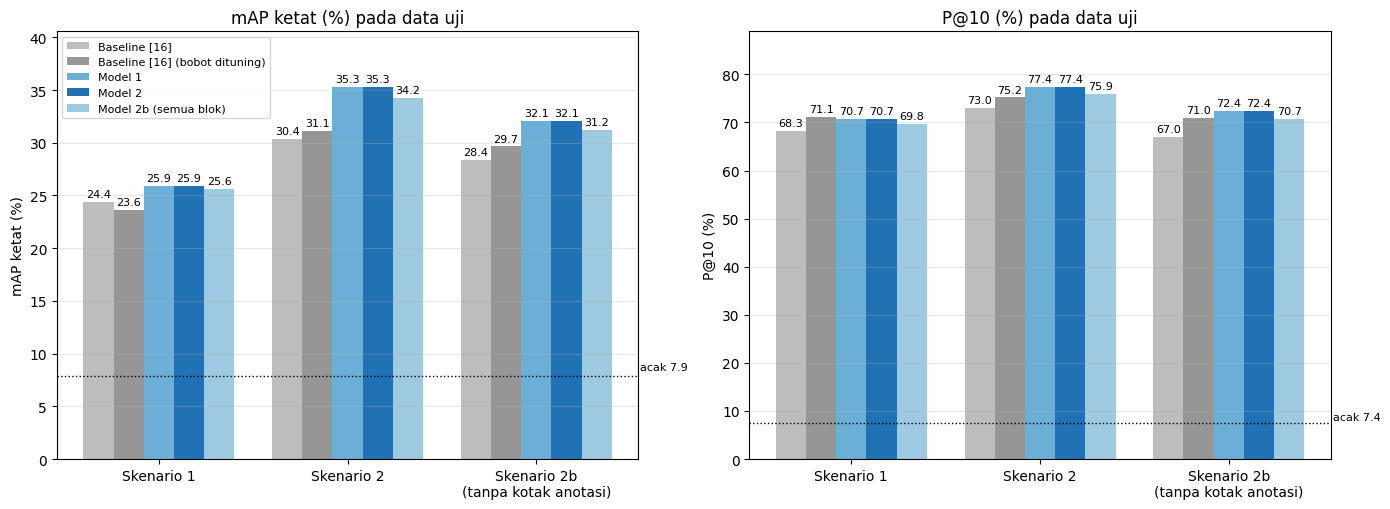

In [22]:
t_scen = pd.concat([
    template_table(ctx_s1["counts"][M_2], "Scenario 1"),
    template_table(ctx_s2["counts"][M_2], "Scenario 2"),
    template_table(robust_counts, "Scenario 3"),
    template_table(rf_counts, "Scenario 4"),
], ignore_index=True)
t_model = pd.concat([
    template_table(ctx_s2["counts"][M_BASE], "Baseline (adaptasi)", "Model"),
    template_table(ctx_s2["counts"][M_1], "Model 1", "Model"),
    template_table(ctx_s2["counts"][M_2], "Model 2", "Model"),
    template_table(rf_counts, "Proposed Model (Model 3, putaran terakhir)", "Model"),
], ignore_index=True)
print("LAMPIRAN - tabel format template (TP/TN/FP/FN rata-rata per kueri pada k =", TABLE_K, ")")
print("Akurasi/Specificity mendekati 100% karena TN sangat besar, dan Recall kecil karena R >> k: gunakan P@k, R@k, mAP sebagai metrik utama.")
print("Tabel perbandingan skenario (model usulan):"); display(t_scen.round(2))
print("Tabel perbandingan model:"); display(t_model.round(2))
t_scen.to_csv(WORK_DIR / "tabel_template_skenario.csv", index=False)
t_model.to_csv(WORK_DIR / "tabel_template_model.csv", index=False)

fb = feedback_df.copy(); fb["Skenario"] = "s4_relevance_feedback"; fb["Subset"] = "semua kueri uji (galeri residual)"; fb["Normalisasi"] = ctx_s2["norm_mode"]
ct = control_df.copy(); ct["Skenario"] = "s4_kontrol_tanpa_umpan_balik"; ct["Subset"] = "semua kueri uji (galeri residual)"; ct["Normalisasi"] = ctx_s2["norm_mode"]
base = results_base_models[results_base_models["Subset"] == "semua kueri uji"].copy(); base["Putaran"] = np.nan
final_results = pd.concat([base, fb, ct], ignore_index=True, sort=False)
display(final_results.round(3))
final_results.to_csv(WORK_DIR / "ringkasan_metrik_peringkat.csv", index=False)

# ---- Grafik metrik utama dengan label angka (mAP ketat dan P@10 per skenario dan model) ----
SHORT = {M_BASE: "Baseline [16]", M_BASE_T: "Baseline [16]\n(bobot dituning)", M_1: "Model 1", M_2: "Model 2", M_2B: "Model 2b\n(semua blok)"}
SCN = [("s1_resize_saja", "Skenario 1"), ("s2_praproses_penuh", "Skenario 2"), ("s2b_praproses_otomatis", "Skenario 2b\n(tanpa kotak anotasi)")]
SCN = [(k, v) for k, v in SCN if k in CTX]
palette = ["#bdbdbd", "#969696", "#6baed6", "#2171b5", "#9ecae1"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, (col, ttl, rand_v) in zip(axes, (("mAP_strict", "mAP ketat (%)", rand_row["mAP_strict"]), ("P@10", "P@10 (%)", rand_row["P@10"]))):
    width = 0.8 / len(SHORT)
    for j, (m, lab) in enumerate(SHORT.items()):
        vals = [float(base[(base["Skenario"] == k) & (base["Model"] == m)][col].iloc[0]) for k, _ in SCN]
        bars = ax.bar(np.arange(len(SCN)) + (j - (len(SHORT) - 1) / 2) * width, vals, width, label=lab.replace("\n", " "), color=palette[j])
        ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
    ax.axhline(float(rand_v), color="k", ls=":", lw=1); ax.text(len(SCN) - 0.45, float(rand_v) + 0.6, f"acak {float(rand_v):.1f}", fontsize=8)
    ax.set_xticks(range(len(SCN))); ax.set_xticklabels([v for _, v in SCN]); ax.set_ylabel(ttl); ax.set_title(ttl + " pada data uji")
    ax.set_ylim(0, max(base[col]) * 1.15); ax.grid(axis="y", alpha=0.3)
axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(WORK_DIR / "perbandingan_mAP.png", dpi=140, bbox_inches="tight"); plt.show()


## 13b. Tabel 3, 4, 5 format proposal, hasil per kelas, dan kebingungan top-10
Tabel di bawah mengisi Tabel 3, 4, dan 5 pada proposal (tabel hasil di proposal masih kosong). Baris tambahan diberi label.

Tabel 3. Perbandingan performa model pada tiap skenario


,Skenario,Model,P@5 (%),P@10 (%),R@10 (%),mAP ketat (%),mAP longgar (%)
0,Skenario 1,Baseline [16],75.40,68.28,2.04,24.37,35.16
1,Skenario 1,Model 1,76.09,70.72,2.11,25.90,34.98
2,Skenario 1,Model 2,76.09,70.72,2.11,25.90,34.98
3,Skenario 2,Baseline [16],79.48,72.99,2.18,30.38,41.47
4,Skenario 2,Model 1,82.87,77.36,2.31,35.28,46.87
5,Skenario 2,Model 2,82.87,77.36,2.31,35.28,46.87
6,Skenario 4,"Model 3, putaran 0",82.87,77.36,2.31,35.28,46.87
7,Skenario 4,"Model 3, putaran 1",83.22,77.50,2.37,37.09,49.08
8,Skenario 4,"Model 3, putaran 2",86.49,80.63,2.53,38.71,50.80
9,Skenario 4,"Model 3, putaran 3",84.48,79.97,2.58,39.58,51.90


Tabel 3b (tambahan). Pembanding yang lebih adil dan Skenario 2b


,Skenario,Model,P@5 (%),P@10 (%),R@10 (%),mAP ketat (%),mAP longgar (%)
0,Skenario 1,Baseline [16] (bobot sama),75.40,68.28,2.04,24.37,35.16
1,Skenario 1,Baseline [16] (bobot dituning),77.07,71.09,2.12,23.61,35.38
2,Skenario 1,HOG saja + Euclidean,73.85,66.35,1.98,23.96,33.94
3,Skenario 1,SIFT saja + Euclidean,59.71,52.93,1.58,17.68,28.68
4,Skenario 1,Model 1,76.09,70.72,2.11,25.90,34.98
5,Skenario 1,Model 2,76.09,70.72,2.11,25.90,34.98
6,Skenario 1,Model 2b (semua blok aktif),76.21,69.77,2.08,25.62,34.87
7,Skenario 2,Baseline [16] (bobot sama),79.48,72.99,2.18,30.38,41.47
8,Skenario 2,Baseline [16] (bobot dituning),79.94,75.20,2.25,31.15,41.92
9,Skenario 2,HOG saja + Euclidean,78.45,71.47,2.13,29.28,40.31


Tabel 4. Hasil uji ketahanan (mAP ketat, %)


Model,Perturbasi,Baseline [16],Model 1,Model 2
0,Tanpa perturbasi,32.01,36.20,36.20
1,Rotasi ±15°,26.29,30.04,30.04
2,Kecerahan ±30%,31.85,34.90,34.90
3,"Skala 0,8 kali",20.83,20.51,20.51
4,Pemotongan tepi 20%,22.45,24.62,24.62


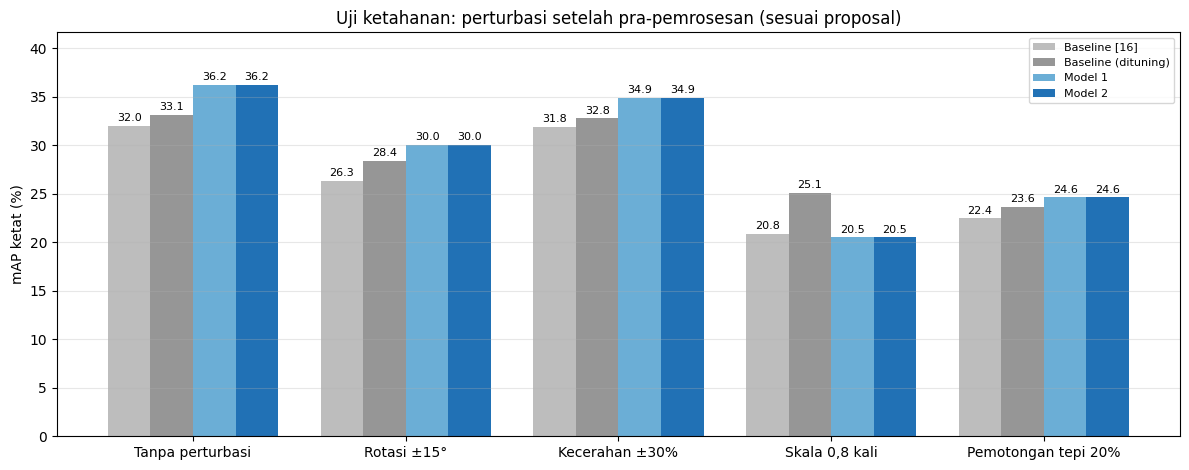

Tabel 4b (tambahan). Ketahanan dengan perturbasi pada citra mentah, Skenario 2b (mAP ketat, %)


Model,Perturbasi,Baseline [16],Baseline (dituning),Model 1,Model 2
0,Tanpa perturbasi,30.15,31.13,35.22,35.22
1,Rotasi ±15°,23.26,26.04,26.53,26.53
2,Kecerahan ±30%,29.78,30.80,34.66,34.66
3,"Skala 0,8 kali",16.72,17.73,18.81,18.81
4,Pemotongan tepi 20%,21.69,23.11,25.28,25.28


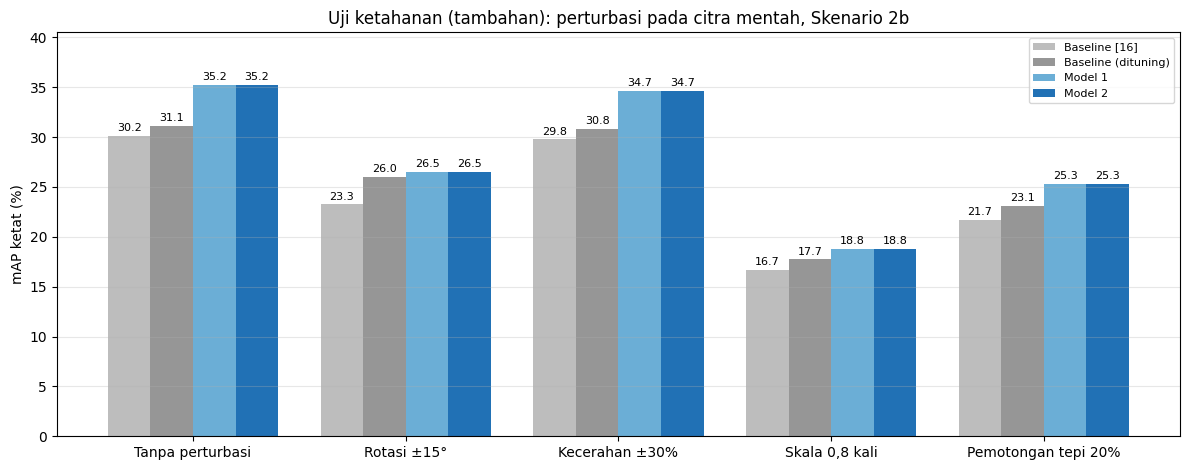

Tabel 5. Proposed model vs baseline yang diadaptasi pada dataset yang sama
CATATAN: metrik Model 3 dihitung pada galeri residual (citra yang sudah dinilai dikeluarkan), sehingga bandingkan dengan baris KONTROL, bukan dengan Model 2 pada galeri penuh.


,Model,P@5 (%),P@10 (%),R@10 (%),mAP ketat (%),mAP longgar (%)
0,Baseline [16] (adaptasi),79.48,72.99,2.18,30.38,41.47
1,Model 1,82.87,77.36,2.31,35.28,46.87
2,Model 2,82.87,77.36,2.31,35.28,46.87
3,"Proposed model (Model 3, putaran 3; galeri res...",84.48,79.97,2.58,39.58,51.90
4,Kontrol: Model 2 tanpa umpan balik (galeri res...,54.37,53.13,1.70,29.99,42.87



Presisi kumulatif (semua citra yang sudah ditampilkan sampai putaran r) - dengan vs tanpa umpan balik:


,Putaran,P_kumulatif_RF,P_kumulatif_kontrol
0,0,77.36,77.36
1,1,77.43,70.66
2,2,78.50,66.12
3,3,78.86,62.87



Per kelas (Skenario 2):


,Jumlah kueri,P@10 Model 2,AP ketat Model 2,P@10 Baseline,AP ketat Baseline
label,,,,,
Topeng Barong Bangkung,29,70.69,35.45,51.72,17.82
Topeng Barong Ket,25,74.00,37.74,68.80,33.90
Topeng Barong Macan,28,78.21,34.09,81.43,38.28
Topeng Bujuh,27,69.26,23.41,65.56,20.94
Topeng Dalem Arsa Wijaya,27,67.41,27.99,65.93,26.61
Topeng Jauk Keras,25,73.20,40.57,74.80,40.36
Topeng Jauk Manis,26,93.85,37.53,75.00,23.58
Topeng Keras,26,66.54,23.87,58.85,21.08
Topeng Penasar,31,72.26,34.82,74.84,24.20


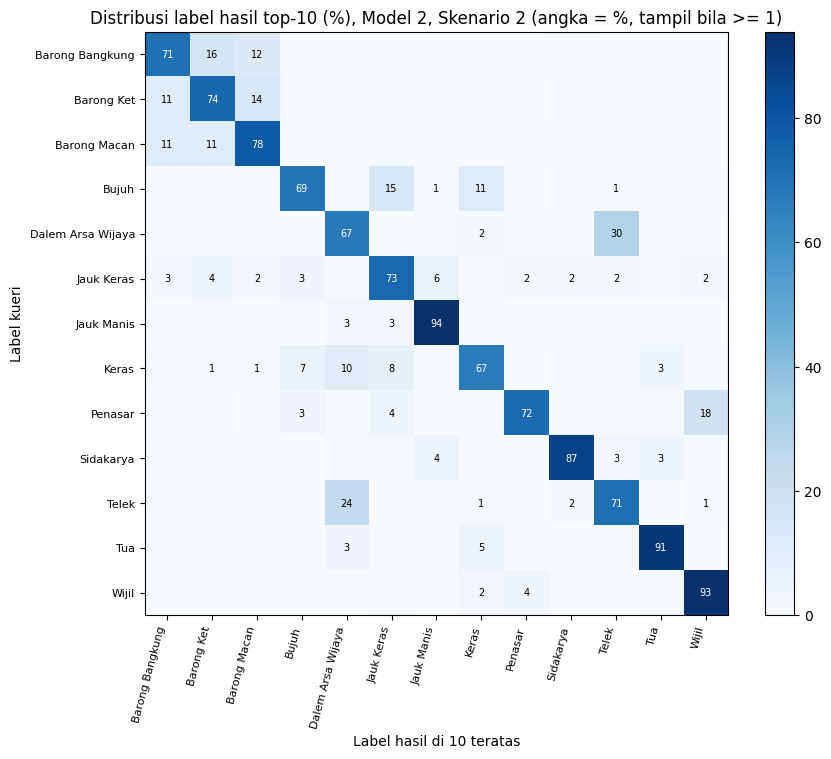

In [23]:
COLS = ["P@5", "P@10", "R@10", "mAP_strict", "mAP_loose"]
RENAME = {"mAP_strict": "mAP ketat (%)", "mAP_loose": "mAP longgar (%)", "P@5": "P@5 (%)", "P@10": "P@10 (%)", "R@10": "R@10 (%)"}
def _row(df, scen, model, label_scen, label_model):
    r = df[(df["Skenario"] == scen) & (df["Model"] == model) & (df["Subset"] == "semua kueri uji")].iloc[0]
    return {"Skenario": label_scen, "Model": label_model, **{RENAME[c]: r[c] for c in COLS}}

# ---- Tabel 3: perbandingan performa model pada tiap skenario ----
t3 = []
for scen, lab in (("s1_resize_saja", "Skenario 1"), ("s2_praproses_penuh", "Skenario 2")):
    for m, ml in ((M_BASE, "Baseline [16]"), (M_1, "Model 1"), (M_2, "Model 2")):
        t3.append(_row(results_base_models, scen, m, lab, ml))
for r in range(FEEDBACK_ROUNDS + 1):
    t3.append({"Skenario": "Skenario 4", "Model": f"Model 3, putaran {r}", **{RENAME[c]: feedback_df.loc[r, c] for c in COLS}})
for r in range(FEEDBACK_ROUNDS + 1):
    t3.append({"Skenario": "Skenario 4 (kontrol)", "Model": f"Model 2 tanpa umpan balik, galeri residual putaran {r}", **{RENAME[c]: control_df.loc[r, c] for c in COLS}})
tabel3 = pd.DataFrame(t3)
print("Tabel 3. Perbandingan performa model pada tiap skenario"); display(tabel3.round(2))

# ---- Tabel 3b (tambahan): Skenario 2b dan pembanding yang lebih adil ----
t3b = []
for scen, lab in (("s1_resize_saja", "Skenario 1"), ("s2_praproses_penuh", "Skenario 2"), ("s2b_praproses_otomatis", "Skenario 2b")):
    if scen not in CTX:
        continue
    for m, ml in ((M_BASE, "Baseline [16] (bobot sama)"), (M_BASE_T, "Baseline [16] (bobot dituning)"), (M_BASE_HOG, "HOG saja + Euclidean"), (M_BASE_SIFT, "SIFT saja + Euclidean"),
                  (M_1, "Model 1"), (M_2, "Model 2"), (M_2B, "Model 2b (semua blok aktif)")):
        if ((results_base_models["Skenario"] == scen) & (results_base_models["Model"] == m)).any():
            t3b.append(_row(results_base_models, scen, m, lab, ml))
tabel3b = pd.DataFrame(t3b)
print("Tabel 3b (tambahan). Pembanding yang lebih adil dan Skenario 2b"); display(tabel3b.round(2))
tabel3b.to_csv(WORK_DIR / "tabel3b_pembanding_tambahan.csv", index=False)

# ---- Tabel 4: uji ketahanan (mAP ketat) ----
tabel4 = (robust_df.pivot(index="Perturbasi", columns="Model", values="mAP_strict")
          .reindex([c for c, _ in PERTURB_CASES])[[M_BASE, M_1, M_2]]
          .rename(columns={M_BASE: "Baseline [16]", M_1: "Model 1", M_2: "Model 2"}).reset_index())
print("Tabel 4. Hasil uji ketahanan (mAP ketat, %)"); display(tabel4.round(2))

def robust_chart(df, title, fname):
    piv = df.pivot(index="Perturbasi", columns="Model", values="mAP_strict").reindex([c for c, _ in PERTURB_CASES])
    cols = [(M_BASE, "Baseline [16]", "#bdbdbd"), (M_BASE_T, "Baseline (dituning)", "#969696"), (M_1, "Model 1", "#6baed6"), (M_2, "Model 2", "#2171b5")]
    fig, ax = plt.subplots(figsize=(12, 4.8)); width = 0.8 / len(cols)
    for j, (m, lab, colr) in enumerate(cols):
        bars = ax.bar(np.arange(len(piv)) + (j - (len(cols) - 1) / 2) * width, piv[m].values, width, label=lab, color=colr)
        ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
    ax.set_xticks(range(len(piv))); ax.set_xticklabels(piv.index); ax.set_ylabel("mAP ketat (%)"); ax.set_title(title)
    ax.set_ylim(0, float(np.nanmax(piv.values)) * 1.15); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.savefig(WORK_DIR / fname, dpi=140, bbox_inches="tight"); plt.show()
robust_chart(robust_df, "Uji ketahanan: perturbasi setelah pra-pemrosesan (sesuai proposal)", "ketahanan_mAP.png")
if robust_raw_df is not None:
    tabel4b = (robust_raw_df.pivot(index="Perturbasi", columns="Model", values="mAP_strict").reindex([c for c, _ in PERTURB_CASES])[[M_BASE, M_BASE_T, M_1, M_2]]
               .rename(columns={M_BASE: "Baseline [16]", M_BASE_T: "Baseline (dituning)", M_1: "Model 1", M_2: "Model 2"}).reset_index())
    print("Tabel 4b (tambahan). Ketahanan dengan perturbasi pada citra mentah, Skenario 2b (mAP ketat, %)"); display(tabel4b.round(2))
    tabel4b.to_csv(WORK_DIR / "tabel4b_ketahanan_citra_mentah.csv", index=False)
    robust_chart(robust_raw_df, "Uji ketahanan (tambahan): perturbasi pada citra mentah, Skenario 2b", "ketahanan_citra_mentah_mAP.png")

# ---- Tabel 5: proposed model vs baseline ----
last = FEEDBACK_ROUNDS
t5 = [_row(results_base_models, "s2_praproses_penuh", M_BASE, "", "Baseline [16] (adaptasi)"),
      _row(results_base_models, "s2_praproses_penuh", M_1, "", "Model 1"),
      _row(results_base_models, "s2_praproses_penuh", M_2, "", "Model 2"),
      {"Skenario": "", "Model": f"Proposed model (Model 3, putaran {last}; galeri residual)", **{RENAME[c]: feedback_df.loc[last, c] for c in COLS}},
      {"Skenario": "", "Model": f"Kontrol: Model 2 tanpa umpan balik (galeri residual yang sama, putaran {last})", **{RENAME[c]: control_df.loc[last, c] for c in COLS}}]
tabel5 = pd.DataFrame(t5).drop(columns=["Skenario"])
print("Tabel 5. Proposed model vs baseline yang diadaptasi pada dataset yang sama")
print("CATATAN: metrik Model 3 dihitung pada galeri residual (citra yang sudah dinilai dikeluarkan), sehingga bandingkan dengan baris KONTROL, bukan dengan Model 2 pada galeri penuh.")
display(tabel5.round(2))
print("\nPresisi kumulatif (semua citra yang sudah ditampilkan sampai putaran r) - dengan vs tanpa umpan balik:")
display(feedback_df[["Putaran", "P_kumulatif_RF", "P_kumulatif_kontrol"]].round(2))

tabel3.to_csv(WORK_DIR / "tabel3_performa_skenario.csv", index=False)
tabel4.to_csv(WORK_DIR / "tabel4_ketahanan.csv", index=False)
tabel5.to_csv(WORK_DIR / "tabel5_proposed_vs_baseline.csv", index=False)

# ---- Per kelas (Model 2, Skenario 2) dan kebingungan top-10 ----
c = ctx_s2
pq_m2, vs_, _ = per_query_metrics(c["scores_m2"], c["query_indices"], c["gallery_indices"], ks=(10,))
pq_bs, _, _ = per_query_metrics(c["scores_base"], c["query_indices"], c["gallery_indices"], ks=(10,))
per_class = pd.DataFrame({"label": labels_all[c["query_indices"]], "P@10 Model 2": pq_m2["P@10"], "AP ketat Model 2": pq_m2["AP_strict"],
                          "P@10 Baseline": pq_bs["P@10"], "AP ketat Baseline": pq_bs["AP_strict"]}).groupby("label").agg(["mean"]).droplevel(1, axis=1)
per_class.insert(0, "Jumlah kueri", pd.Series(labels_all[c["query_indices"]]).value_counts())
print("\nPer kelas (Skenario 2):"); display(per_class.round(2))
per_class.to_csv(WORK_DIR / "hasil_per_kelas.csv")

top10 = np.argsort(-c["scores_m2"], axis=1)[:, :10]
g_lab_ids = LAB_ID[c["gallery_indices"]]; q_lab_ids = LAB_ID[c["query_indices"]]
conf = np.zeros((len(ALL_LABELS), len(ALL_LABELS)))
for qi, row in enumerate(top10):
    for gi in row:
        conf[q_lab_ids[qi], g_lab_ids[gi]] += 1
conf = conf / np.maximum(conf.sum(1, keepdims=True), 1)
conf_df = pd.DataFrame(conf * 100, index=ALL_LABELS, columns=ALL_LABELS)
conf_df.to_csv(WORK_DIR / "kebingungan_top10.csv")
plt.figure(figsize=(9, 7.5)); plt.imshow(conf_df.values, cmap="Blues")
plt.xticks(range(len(ALL_LABELS)), [l.replace("Topeng ", "") for l in ALL_LABELS], rotation=75, ha="right", fontsize=8)
plt.yticks(range(len(ALL_LABELS)), [l.replace("Topeng ", "") for l in ALL_LABELS], fontsize=8)
for _i in range(conf_df.shape[0]):
    for _j in range(conf_df.shape[1]):
        _v = conf_df.values[_i, _j]
        if _v >= 1:
            plt.text(_j, _i, f"{_v:.0f}", ha="center", va="center", fontsize=7, color="white" if _v > 45 else "black")
plt.xlabel("Label hasil di 10 teratas"); plt.ylabel("Label kueri"); plt.title("Distribusi label hasil top-10 (%), Model 2, Skenario 2 (angka = %, tampil bila >= 1)")
plt.colorbar(); plt.tight_layout(); plt.savefig(WORK_DIR / "kebingungan_top10.png", dpi=140, bbox_inches="tight"); plt.show()


## 13c. Pemeriksaan hipotesis (otomatis)
Ringkasan status tiap klaim berdasarkan interval kepercayaan bootstrap. Gunakan sebagai batas klaim di laporan: hanya klaim berstatus DIDUKUNG yang boleh dinyatakan sebagai peningkatan.

In [24]:
def _status(lo, hi):
    if lo > 0: return "DIDUKUNG (CI95 di atas 0)"
    if hi < 0: return "BERLAWANAN (CI95 di bawah 0)"
    return "TIDAK TERBUKTI (CI95 memuat 0)"

def _d(scen, a, b, metric="mAP ketat"):
    r = diff_df[(diff_df["Skenario"] == scen) & (diff_df["A"] == a) & (diff_df["B"] == b) & (diff_df["Metrik"] == metric)]
    return None if r.empty else r.iloc[0]

lines = []
for scen, lab in SC_TITLES.items():
    if scen not in CTX:
        continue
    lines.append(f"== {lab} ==")
    for hid, text, a, b in (("H1a", "Model 1 lebih baik dari baseline [16] (bobot sama)", M_1, M_BASE),
                            ("H1b", "Model 1 lebih baik dari baseline dengan bobot dituning (pembanding adil)", M_1, M_BASE_T),
                            ("H1c", "Warna ikut berkontribusi: Model 1 lebih baik dari HOG saja", M_1, M_HOGCOS),
                            ("H1d", "Penimbangan perlu: Model 1 lebih baik dari HSV+HOG bobot sama", M_1, M_HSVHOG_EQ),
                            ("H2", "Tekstur (LBP) menambah: Model 2 lebih baik dari Model 1", M_2, M_1)):
        r = _d(scen, a, b)
        if r is None:
            continue
        extra = ""
        if hid == "H2":
            w2_ = CTX[scen]["w2"]
            if w2_["lbp"] == 0:
                extra = " | bobot LBP = 0 pada Model 2, sehingga Model 2 identik dengan Model 1 (LBP tidak dipakai)"
            if w2_["hu"] == 0:
                extra += " | bobot Hu = 0 (Hu tidak dipakai oleh Model 1/2)"
        lines.append(f"  [{hid}] {text}: selisih mAP {r['Selisih (poin)']:+.2f} (CI95 {r['CI95 bawah']:+.2f} .. {r['CI95 atas']:+.2f}) -> {_status(r['CI95 bawah'], r['CI95 atas'])}{extra}")
lines.append("== Relevance feedback (Model 3 vs kontrol tanpa umpan balik, putaran %d) ==" % FEEDBACK_ROUNDS)
for _, r in rf_summary.iterrows():
    lines.append(f"  [H3] {r['Kueri']}: selisih mAP {r['Selisih mAP (RF - kontrol)']:+.2f} (CI95 {r['CI95 bawah']:+.2f} .. {r['CI95 atas']:+.2f}) -> {_status(r['CI95 bawah'], r['CI95 atas'])}")
lines.append("== Ketahanan (mAP ketat Model 1 dikurangi baseline [16]; %d kueri, tanpa CI) ==" % int(robust_df['Jumlah kueri'].iloc[0]))
for case, _v in PERTURB_CASES:
    sub = robust_df[robust_df["Perturbasi"] == case].set_index("Model")["mAP_strict"]
    dlt = sub[M_1] - sub[M_BASE]
    lines.append(f"  [H4] {case}: Model 1 {sub[M_1]:.1f} vs baseline {sub[M_BASE]:.1f} (selisih {dlt:+.1f})" + ("  <- keunggulan hampir hilang" if abs(dlt) < 1.0 else ""))
if extra_rows:
    lines.append("== Fitur alternatif (tambahan) vs Model 1 ==")
    for r in extra_rows:
        lines.append(f"  [H5] {SC_TITLES.get(r['Skenario'], r['Skenario'])} | {r['Konfigurasi']}: selisih mAP {r['Selisih mAP vs Model 1']:+.2f} "
                     f"(CI95 {r['CI95 bawah']:+.2f} .. {r['CI95 atas']:+.2f}) -> {_status(r['CI95 bawah'], r['CI95 atas'])}")
print("PEMERIKSAAN HIPOTESIS (otomatis dari hasil di atas; gunakan sebagai batas klaim di laporan)\n" + "\n".join(lines))
open(WORK_DIR / "pemeriksaan_hipotesis.txt", "w").write("\n".join(lines))


PEMERIKSAAN HIPOTESIS (otomatis dari hasil di atas; gunakan sebagai batas klaim di laporan)
== Skenario 1 ==
  [H1a] Model 1 lebih baik dari baseline [16] (bobot sama): selisih mAP +1.52 (CI95 +0.85 .. +2.19) -> DIDUKUNG (CI95 di atas 0)
  [H1b] Model 1 lebih baik dari baseline dengan bobot dituning (pembanding adil): selisih mAP +2.29 (CI95 +1.15 .. +3.39) -> DIDUKUNG (CI95 di atas 0)
  [H1c] Warna ikut berkontribusi: Model 1 lebih baik dari HOG saja: selisih mAP +0.45 (CI95 +0.24 .. +0.67) -> DIDUKUNG (CI95 di atas 0)
  [H1d] Penimbangan perlu: Model 1 lebih baik dari HSV+HOG bobot sama: selisih mAP +2.00 (CI95 +1.58 .. +2.41) -> DIDUKUNG (CI95 di atas 0)
  [H2] Tekstur (LBP) menambah: Model 2 lebih baik dari Model 1: selisih mAP +0.00 (CI95 +0.00 .. +0.00) -> TIDAK TERBUKTI (CI95 memuat 0) | bobot LBP = 0 pada Model 2, sehingga Model 2 identik dengan Model 1 (LBP tidak dipakai)
== Skenario 2 ==
  [H1a] Model 1 lebih baik dari baseline [16] (bobot sama): selisih mAP +4.90 (CI95 +3.87

4601

## 14. Contoh pencarian (kualitatif)

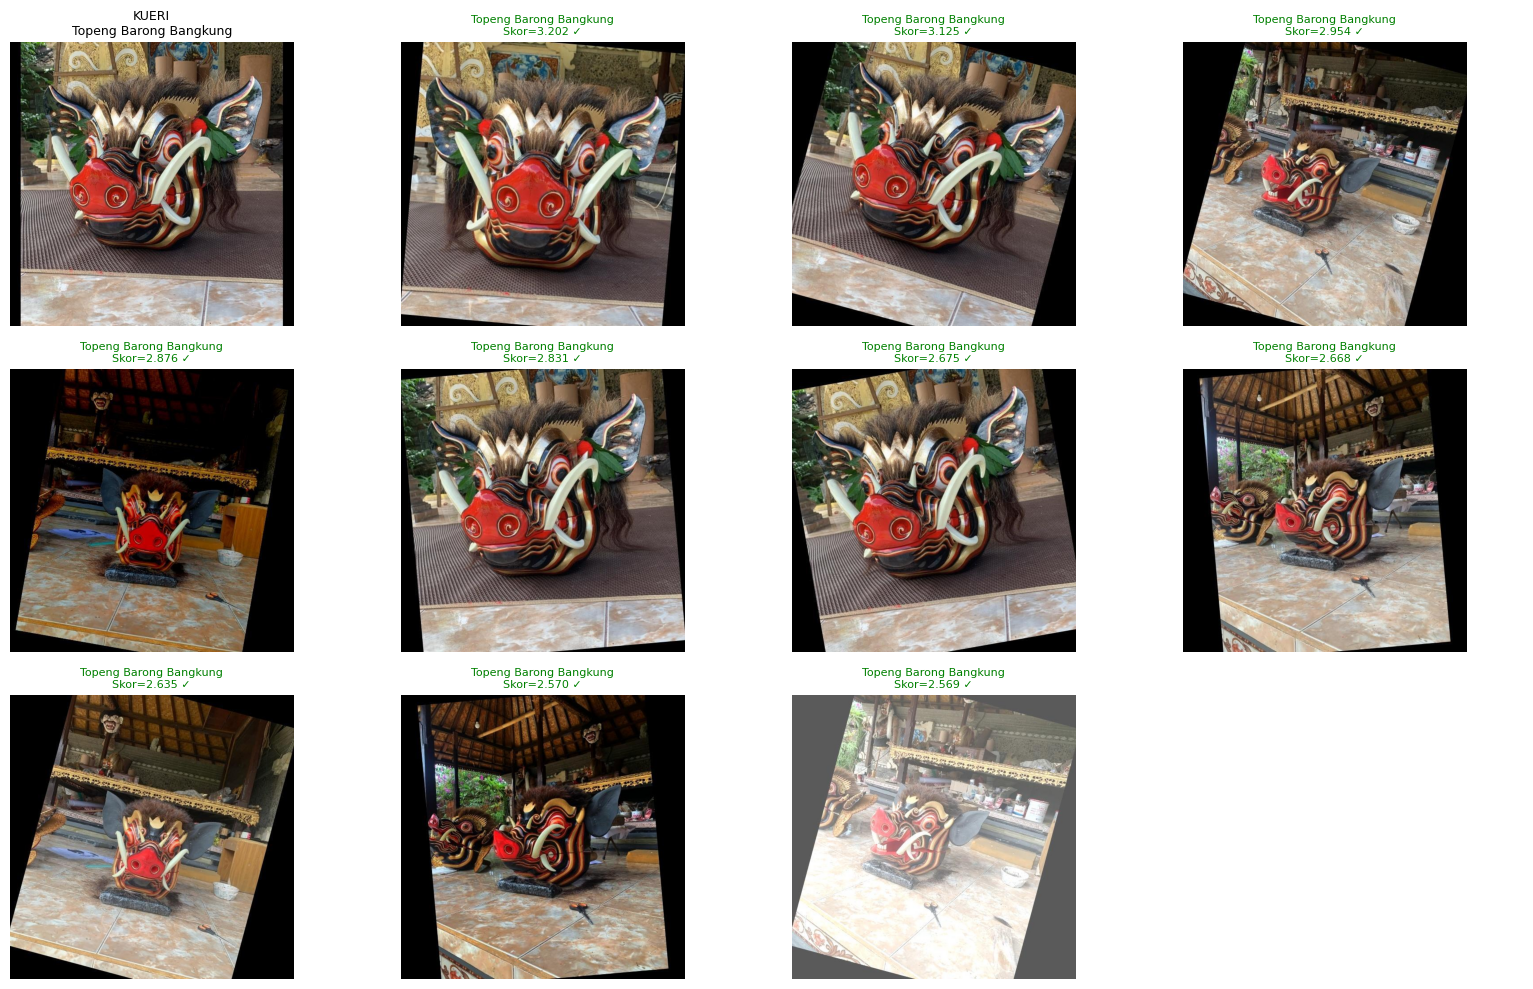

,Peringkat,Path,Label,Skor,Relevan ketat,Relevan longgar
0,1,..\dataset\valid\bangkal-ig-9-_rotated-5_jpg.r...,Topeng Barong Bangkung,3.201583,True,True
1,2,..\dataset\train\bangkal-ig-11-_rotated-15_jpg...,Topeng Barong Bangkung,3.124676,True,True
2,3,..\dataset\train\bangkal-ig-17-_rotated-15_jpg...,Topeng Barong Bangkung,2.954082,True,True
3,4,..\dataset\train\bangkal-ig-15-_rotated-10_jpg...,Topeng Barong Bangkung,2.876436,True,True
4,5,..\dataset\train\bangkal-ig-11-_rotated5_jpg.r...,Topeng Barong Bangkung,2.831090,True,True
5,6,..\dataset\valid\bangkal-ig-11-_rotated10_jpg....,Topeng Barong Bangkung,2.675235,True,True
6,7,..\dataset\train\bangkal-ig-16-_rotated5_jpg.r...,Topeng Barong Bangkung,2.667906,True,True
7,8,..\dataset\train\bangkal-ig-15-_rotated-15_jpg...,Topeng Barong Bangkung,2.635108,True,True
8,9,..\dataset\train\bangkal-ig-16-_rotated5_jpg.r...,Topeng Barong Bangkung,2.570083,True,True
9,10,..\dataset\train\bangkal-ig-17-_rotated-15_jpg...,Topeng Barong Bangkung,2.569173,True,True


In [25]:
def show_retrieval_example(ctx, query_position=0, top_k=10):
    g_global = ctx["gallery_indices"]
    qb = {b: ctx["query_norm"][b][query_position] for b in BLOCKS_M2}
    scores = scores_single(qb, ctx["gallery_norm"], ctx["w2"], ctx["zs"])
    top = np.argsort(-scores)[:top_k]
    q_global = int(ctx["query_indices"][query_position])
    fig, axes = plt.subplots(3, 4, figsize=(16, 10)); axes = axes.ravel()
    axes[0].imshow(cv2.cvtColor(cv2.imread(paths_all[q_global]), cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"KUERI\n{labels_all[q_global]}", fontsize=9); axes[0].axis("off")
    for ax, gi in zip(axes[1:11], top):
        gg = int(g_global[gi])
        ax.imshow(cv2.cvtColor(cv2.imread(paths_all[gg]), cv2.COLOR_BGR2RGB))
        ok = labels_all[gg] == labels_all[q_global]
        ax.set_title(f"{labels_all[gg]}\nSkor={scores[gi]:.3f} {'✓' if ok else '✗'}", fontsize=8, color="green" if ok else "red"); ax.axis("off")
    for ax in axes[11:]: ax.axis("off")
    plt.tight_layout(); plt.savefig(WORK_DIR / "contoh_pencarian.png", dpi=130, bbox_inches="tight"); plt.show()
    return pd.DataFrame([{"Peringkat": r + 1, "Path": paths_all[int(g_global[gi])], "Label": labels_all[int(g_global[gi])],
                          "Skor": float(scores[gi]), "Relevan ketat": bool(labels_all[int(g_global[gi])] == labels_all[q_global]),
                          "Relevan longgar": bool(loose_family(labels_all[int(g_global[gi])]) == loose_family(labels_all[q_global]))}
                         for r, gi in enumerate(top)])

example_df = show_retrieval_example(ctx_s2, 0)
display(example_df)
example_df.to_csv(WORK_DIR / "contoh_pencarian_top10.csv", index=False)

## 15. Prototipe website (opsional)
Ubah `RUN_GRADIO_DEMO = True` pada sel konfigurasi (butuh `pip install gradio`). Fitur sesuai proposal: unggah foto topeng, 10 hasil beserta skor kemiripan, pengaturan bobot warna/bentuk/tekstur, dan umpan balik "mirip / tidak mirip" (Rocchio, beberapa putaran, citra yang sudah dinilai dikeluarkan). Kueri diproses **tanpa kotak anotasi** (Model 2, Skenario 2).


In [26]:
def demo_weights(ctx, w_warna, w_bentuk, w_tekstur):
    """Bobot pengguna (warna, bentuk, tekstur) -> bobot blok. Bobot bentuk dibagi HOG/Hu menurut proporsi hasil validasi."""
    w2 = ctx["w2"]; shape_tot = w2["hog"] + w2["hu"]
    hog_share = (w2["hog"] / shape_tot) if shape_tot > 0 else 1.0
    tot = float(w_warna + w_bentuk + w_tekstur)
    if tot <= 0:
        return dict(w2)
    a, b, c = w_warna / tot, w_bentuk / tot, w_tekstur / tot
    return {"hsv": a, "hog": b * hog_share, "hu": b * (1 - hog_share), "lbp": c}

def demo_search_core(ctx, qb, weights, excluded, top_k=10):
    sc = scores_single(qb, ctx["gallery_norm"], weights, ctx["zs"])
    sc = np.where(excluded, -np.inf, sc)
    top = np.argsort(-sc, kind="stable")[:top_k]
    return top, sc

def make_gradio_app():
    import gradio as gr
    ctx = ctx_s2; g_global = ctx["gallery_indices"]; w2 = ctx["w2"]
    d_warna, d_bentuk, d_tekstur = w2["hsv"], w2["hog"] + w2["hu"], w2["lbp"]
    def render(state, weights):
        top, sc = demo_search_core(ctx, state["qb"], weights, state["excluded"])
        state["shown"] = top.tolist()
        gallery = [(cv2.cvtColor(cv2.imread(paths_all[int(g_global[i])]), cv2.COLOR_BGR2RGB),
                    f"{r + 1}. {labels_all[int(g_global[i])]} (skor {sc[i]:.3f})") for r, i in enumerate(top)]
        msg = f"Putaran umpan balik: {state['round']}. Centang hasil yang MIRIP (sisanya dianggap tidak mirip), lalu klik 'Kirim umpan balik'."
        return gallery, msg, state, gr.update(choices=[str(i) for i in range(1, len(top) + 1)], value=[])
    def do_search(image, wc, ws, wt):
        if image is None:
            return [], "Unggah gambar terlebih dahulu.", None, gr.update(choices=[], value=[])
        tmp = WORK_DIR / "_upload.jpg"
        cv2.imwrite(str(tmp), cv2.cvtColor(np.asarray(image), cv2.COLOR_RGB2BGR))
        bgr, cm, sm, um = preprocess_image(tmp, bbox=None, full_preprocess=True)   # tanpa kotak anotasi, seperti pengguna nyata
        qb = normalize_query_blocks(extract_raw_features_from_arrays(bgr, cm, sm, use_mask_for_visual=um), ctx["hu_scaler"])
        state = {"qb": qb, "excluded": np.zeros(len(g_global), dtype=bool), "shown": None, "round": 0}
        return render(state, demo_weights(ctx, wc, ws, wt))
    def do_feedback(chosen, wc, ws, wt, state):
        if state is None or not state.get("shown"):
            return [], "Lakukan pencarian terlebih dahulu.", state, gr.update(choices=[], value=[])
        shown = state["shown"]
        pos = np.array([shown[int(x) - 1] for x in (chosen or [])], dtype=int)
        neg = np.array([i for i in shown if i not in set(pos.tolist())], dtype=int)
        state["qb"] = rocchio_update(state["qb"], ctx["gallery_norm"], pos, neg)   # Persamaan (8)
        state["excluded"][shown] = True                                            # residual ranking
        state["round"] += 1
        return render(state, demo_weights(ctx, wc, ws, wt))
    def do_reweight(wc, ws, wt, state):
        if state is None:
            return [], "Lakukan pencarian terlebih dahulu.", state, gr.update(choices=[], value=[])
        return render(state, demo_weights(ctx, wc, ws, wt))
    with gr.Blocks() as demo:
        gr.Markdown("## Pencarian Topeng Bali Berbasis Kemiripan Visual (warna HSV, bentuk HOG+Hu, tekstur LBP)")
        state = gr.State(None)
        img = gr.Image(type="numpy", label="Unggah foto topeng")
        with gr.Row():
            sw = gr.Slider(0, 1, value=round(d_warna, 2), step=0.05, label="Bobot warna")
            ss = gr.Slider(0, 1, value=round(d_bentuk, 2), step=0.05, label="Bobot bentuk")
            st = gr.Slider(0, 1, value=round(d_tekstur, 2), step=0.05, label="Bobot tekstur")
        out = gr.Gallery(label="10 hasil paling mirip", columns=5); msg = gr.Markdown()
        rel = gr.CheckboxGroup(choices=[], label="Hasil yang MIRIP")
        with gr.Row():
            b1 = gr.Button("Cari"); b2 = gr.Button("Kirim umpan balik (mirip / tidak mirip)"); b3 = gr.Button("Terapkan bobot")
        b1.click(do_search, [img, sw, ss, st], [out, msg, state, rel])
        b2.click(do_feedback, [rel, sw, ss, st, state], [out, msg, state, rel])
        b3.click(do_reweight, [sw, ss, st, state], [out, msg, state, rel])
    return demo

if RUN_GRADIO_DEMO:
    make_gradio_app().launch(share=True)
else:
    print("Demo Gradio dinonaktifkan (RUN_GRADIO_DEMO = False).")


Demo Gradio dinonaktifkan (RUN_GRADIO_DEMO = False).


## 15b. Simpan model untuk aplikasi (Streamlit)
Menyimpan indeks galeri ternormalisasi, statistik normalisasi, bobot hasil validasi, dan thumbnail ke folder `model_cbir/`. 
Format `.npz`/`.json`/`.csv` (bukan pickle). Skenario 2b (tanpa kotak anotasi) menjadi bawaan karena pengguna website tidak punya kotak anotasi; Skenario 2 ikut disimpan. 
Dibaca oleh `cbir_engine.py`.

In [27]:
# ---- Simpan model untuk aplikasi (Streamlit / skrip lain) ----------------------------------------------------
# Format sengaja BUKAN pickle: .npz (matriks), .json (parameter), .csv (galeri), .jpg (thumbnail), sehingga aman
# dibuka lintas versi Python/NumPy. Dibaca oleh cbir_engine.py.
from datetime import datetime

MODEL_DIR = Path(os.environ.get("CBIR_MODEL_DIR") or "model_cbir")
SAVE_THUMBS = True
THUMB_SIDE = 256
SAVE_CTX = {"s2b_praproses_otomatis": ctx_s2b, "s2_praproses_penuh": ctx_s2}     # s2b = kondisi pengguna nyata (tanpa kotak anotasi)
SAVE_CTX = {k: v for k, v in SAVE_CTX.items() if v is not None}
MODEL_DIR.mkdir(parents=True, exist_ok=True)

_ref = next(iter(SAVE_CTX.values()))
_gidx = np.asarray(_ref["gallery_indices"], int)
for _c in SAVE_CTX.values():
    assert np.array_equal(np.asarray(_c["gallery_indices"], int), _gidx), "galeri antar skenario harus sama"

def _rel(p):
    try:
        return str(Path(p).resolve().relative_to(Path(ROOT).resolve()))
    except Exception:
        return str(p)

_thumb_dir = MODEL_DIR / "thumbs"
if SAVE_THUMBS:
    _thumb_dir.mkdir(exist_ok=True)
_rows = []
for _i, _g in enumerate(tqdm(_gidx, desc="Galeri + thumbnail")):
    _name = f"{_i:05d}.jpg"
    if SAVE_THUMBS:
        _im = cv2.imread(str(paths_all[_g]))
        if _im is not None:
            _s = THUMB_SIDE / max(_im.shape[:2])
            if _s < 1:
                _im = cv2.resize(_im, (max(1, int(_im.shape[1] * _s)), max(1, int(_im.shape[0] * _s))), interpolation=cv2.INTER_AREA)
            cv2.imwrite(str(_thumb_dir / _name), _im, [cv2.IMWRITE_JPEG_QUALITY, 85])
        else:
            _name = ""
    _rows.append({"id": _i, "global_index": int(_g), "label": labels_all[_g], "split": splits_all[_g], "path": _rel(paths_all[_g]), "thumb": _name if SAVE_THUMBS else ""})
pd.DataFrame(_rows).to_csv(MODEL_DIR / "gallery.csv", index=False)

_meta = {"format_version": 1, "created": datetime.now().isoformat(timespec="seconds"), "n_gallery": int(len(_gidx)),
         "classes": sorted(set(labels_all[_gidx].tolist())), "unit_mode": UNIT_MODE, "random_seed": RANDOM_SEED,
         "default_scenario": next(iter(SAVE_CTX)),
         "features": {"IMAGE_SIZE": list(IMAGE_SIZE), "SEG_MAX_SIDE": SEG_MAX_SIDE, "HSV_BINS": list(HSV_BINS), "HOG_ORIENTATIONS": HOG_ORIENTATIONS,
                      "HOG_PIXELS_PER_CELL": list(HOG_PIXELS_PER_CELL), "HOG_CELLS_PER_BLOCK": list(HOG_CELLS_PER_BLOCK),
                      "LBP_P": LBP_P, "LBP_R": LBP_R, "LBP_GRID": list(LBP_GRID), "LBP_BINS_PER_CELL": LBP_BINS_PER_CELL},
         "rocchio": {"alpha": ROCCHIO_ALPHA, "beta": ROCCHIO_BETA, "gamma": ROCCHIO_GAMMA},
         "scenarios": {}}
for _tag, _c in SAVE_CTX.items():
    _arr = {f"g_{b}": np.asarray(_c["gallery_norm"][b], np.float32) for b in BLOCKS_M2}
    _sc = _c["hu_scaler"]
    for _b, _mu in _sc.get("center", {}).items():
        _arr[f"c_{_b}"] = np.asarray(_mu, np.float32)
    _arr["hu_mean"], _arr["hu_std"] = np.asarray(_sc["mean"], np.float32), np.asarray(_sc["std"], np.float32)
    np.savez_compressed(MODEL_DIR / f"index_{_tag}.npz", **_arr)
    _meta["scenarios"][_tag] = {"norm_mode": _c["norm_mode"], "zscore": bool(_c["zs"]),
                                "weights": {"w1": {k: float(v) for k, v in _c["w1"].items()}, "w2": {k: float(v) for k, v in _c["w2"].items()},
                                            "w2m": {k: float(v) for k, v in _c["w2m"].items()}},
                                "val_mAP_strict": {"model1": float(_c["vm1"]), "model2": float(_c["vm2"]), "model2b": float(_c["vm2m"])}}
(MODEL_DIR / "meta.json").write_text(json.dumps(_meta, indent=2, ensure_ascii=False), encoding="utf-8")
print("Model tersimpan di:", MODEL_DIR.resolve())
for _f in sorted(MODEL_DIR.glob("*")):
    if _f.is_file():
        print(f" - {_f.name}  ({_f.stat().st_size / 1024 / 1024:.1f} MB)")
print("Skenario:", list(SAVE_CTX), "| bawaan:", _meta["default_scenario"])


Galeri + thumbnail: 100%|██████████| 4362/4362 [00:24<00:00, 181.13it/s]


Model tersimpan di: D:\Semester 7\citra\TuBes\notebook\model_cbir
 - gallery.csv  (0.5 MB)
 - index_s2_praproses_penuh.npz  (34.9 MB)
 - index_s2b_praproses_otomatis.npz  (34.9 MB)
 - meta.json  (0.0 MB)
Skenario: ['s2b_praproses_otomatis', 's2_praproses_penuh'] | bawaan: s2b_praproses_otomatis


## 16. Berkas keluaran

In [28]:
print("Semua keluaran ada di:", WORK_DIR)
for f in sorted(WORK_DIR.glob("*")):
    if f.is_file():
        print(f" - {f.name}  ({f.stat().st_size / 1024:.1f} KB)")

Semua keluaran ada di: cbir_topeng_output
 - ablasi_fitur_uji.csv  (5.1 KB)
 - ablasi_fitur_uji.png  (67.9 KB)
 - audit_near_duplicate_uji.csv  (36.1 KB)
 - bobot_terpilih.csv  (1.4 KB)
 - bobot_terpilih.json  (1.6 KB)
 - contoh_citra_per_label.png  (2336.1 KB)
 - contoh_pencarian.png  (2752.8 KB)
 - contoh_pencarian_top10.csv  (1.4 KB)
 - dataset_counts.csv  (0.5 KB)
 - dataset_counts_vs_proposal.csv  (0.5 KB)
 - diagnosis_blok_fitur.csv  (3.3 KB)
 - hasil_baseline_model1_model2.csv  (14.9 KB)
 - hasil_ketahanan.csv  (4.9 KB)
 - hasil_ketahanan_citra_mentah.csv  (4.9 KB)
 - hasil_per_kelas.csv  (1.2 KB)
 - hasil_relevance_feedback.csv  (1.3 KB)
 - hasil_relevance_feedback_kontrol.csv  (1.3 KB)
 - hasil_relevance_feedback_model2b.csv  (1.3 KB)
 - kebingungan_top10.csv  (2.1 KB)
 - kebingungan_top10.png  (87.5 KB)
 - ketahanan_citra_mentah_mAP.png  (51.2 KB)
 - ketahanan_mAP.png  (52.0 KB)
 - kontribusi_marginal_fitur.csv  (0.3 KB)
 - pemeriksaan_hipotesis.txt  (4.5 KB)
 - perbandingan_